<a href="https://colab.research.google.com/github/AntonyRMV26/GRUPO-1---Ingenier-a-del-Conocimiento/blob/main/Pipeline_CNN_Kather_GrupoPolmar.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import tensorflow as tf

print("TensorFlow:", tf.__version__)
print("GPU:", tf.config.list_physical_devices("GPU"))

TensorFlow: 2.21.0
GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


# 🔬 Pipeline CNN Completo: Clasificación de Tejidos Histológicos de Cáncer Colorrectal


---

## 📌 Presentación

| | |
|---|---|
| **Curso** | Ingeniería de Conocimientos |
| **Semestre** | V |
| **Fecha** | 11/11/2026 |
| **Universidad** | Universidad Nacional del Centro del Perú (UNCP) · Facultad de Ingeniería de Sistemas |
| **Docente** | Msc. Jaime Antonio Huaytalla Pariona |

### 👥 Integrantes

1. Bendezu Arana Joss Erick
2. Briceño Carrión Polmar Yacid
3. Morales Huaman Jhordan Aldair
4. Morales Valverde Antony Rodrigo

---

## 🗂️ Dataset elegido

**Kather Colorectal Histology (Kather-texture-2016): clasificación de tejidos microscópicos**

🔗 **URL:** https://huggingface.co/datasets/1aurent/Kather-texture-2016

### ✍️ Justificación de la elección

Para escoger el dataset primero revisamos los criterios que pidió el ingeniero (mínimo 1000 imágenes, al menos 3 clases, un contexto real y nada de MNIST ni Fashion-MNIST) y después buscamos en Hugging Face algo que además nos llamara la atención. Este dataset cumple todo eso con bastante margen: tiene 5000 imágenes y 8 clases de tejido, así que no estamos justos en ningún requisito.

Lo que más nos convenció fue el contexto. Son imágenes de cortes de cáncer colorrectal vistos al microscopio, y nos pareció interesante que una red convolucional pueda ayudar a reconocer qué tipo de tejido hay en cada parche (tumor, estroma, linfocitos, grasa, etc.). Es una aplicación que sí existe en patología digital, no un problema de juguete, y eso hace que el trabajo tenga más sentido que clasificar dígitos o ropa.

También pesó el tema práctico. Las imágenes son de 150 × 150 píxeles y todo el dataset ocupa unos 293 MB, por lo que es razonable para Google Colab; el tiempo y la disponibilidad de GPU dependerán de la sesión y la arquitectura. Según la descripción original viene balanceado (625 imágenes por clase), algo que vamos a comprobar nosotros mismos en el EDA en lugar de asumirlo. Además tiene licencia CC BY 4.0, las muestras están anonimizadas, el estudio pasó por un comité de ética y viene acompañado de un artículo publicado (Kather et al., *Scientific Reports*, 2016), lo cual nos da una referencia seria con la cual comparar nuestros resultados.

Por último, nos interesó porque es distinto al ejemplo que se vio en clase (hojas de plantas). En histología el tejido no tiene una orientación fija, así que técnicas como el giro vertical y las rotaciones sí tienen justificación real, y eso nos permite razonar el data augmentation en vez de copiarlo.

### 🩺 Descripción del problema

En un laboratorio de patología, el médico revisa láminas de tumores colorrectales al microscopio y tiene que reconocer qué hay en cada zona: células tumorales, estroma (el tejido de soporte), linfocitos, mucosa normal, grasa, restos de tejido muerto, zonas complejas o simplemente fondo sin tejido. Hacerlo a mano toma mucho tiempo y puede variar de un observador a otro. Además, se sabe que la composición del tejido se estudia en patología digital. No estimaremos pronóstico ni diagnóstico con estos parches: solo clasificaremos su tipo de tejido.

El problema que vamos a resolver es el siguiente: **dada una imagen RGB de 150 × 150 píxeles (un parche de unos 74 × 74 µm), predecir a cuál de los 8 tipos de tejido pertenece.** Es un problema de **clasificación multiclase** (una sola etiqueta por imagen), por lo que la capa de salida será softmax con 8 neuronas y usaremos entropía cruzada categórica como función de pérdida.

Queremos construir el proceso completo como se haría en un proyecto real: definir el problema, revisar los datos, preprocesar, entrenar tres arquitecturas, evaluarlas con rigor sobre un conjunto de prueba reservado antes del entrenamiento (independiente por archivo, pero no necesariamente por paciente/lámina), analizar sus errores, versionar el proyecto, documentarlo y dejarlo listo para desplegar. Aclaramos que es un trabajo académico: el modelo no reemplaza el criterio de un patólogo y no está validado para pacientes o centros nuevos. Los recortes originales provienen de diez muestras y la versión empleada no proporciona identificadores fiables de procedencia por recorte.

> 📚 **Referencia del dataset:** Kather JN, Weis CA, Bianconi F, Melchers SM, Schad LR, Gaiser T, Marx A, Zöllner FG. *Multi-class texture analysis in colorectal cancer histology.* Scientific Reports 6, 27988 (2016). Zenodo: https://zenodo.org/records/53169


---
## 🧭 Mapa del notebook

El trabajo sigue las **12 fases** de las sesiones 08-A y 08-B. Como las dos presentaciones agrupan algunas fases de forma distinta, usamos la numeración del slide *«El Puente hacia Producción»* y aquí dejamos la equivalencia para que no haya confusión:

| Fase | Contenido | Equivale en Sesión 08-A / 08-B |
|:---:|---|---|
| 0 | Configuración del entorno y reproducibilidad | Pipeline profesional (semilla fija, scripts) |
| 1 | Definición del problema | 08-A · Fase 1 |
| 2 | Selección y validación del dataset | 08-A · Fase 2 |
| 3 | EDA para imágenes | 08-A · Fase 2 (EDA) |
| 4 | Preprocesamiento y data augmentation | 08-A · Fase 3 |
| 5 | Arquitecturas, configuración, callbacks y entrenamiento | 08-A · Fases 4 y 5 |
| 6 | Suite de evaluación completa | 08-B · Fase 6 |
| 7 | Análisis de errores | 08-B · Fase 7 |
| 8 | Comparación sistemática de modelos | 08-B · Fase 8 |
| 9 | Versionado del proyecto y metadata | 08-B · Fase 9 |
| 10 | Logging y registro de experimentos | 08-B · Fase 10 |
| 11 | Documentación técnica | 08-B · Fase 11 |
| 12 | Despliegue básico | 08-B · Fase 12 |
| ✅ | Cierre: checklist del pipeline completo | 08-B · Cierre |

> ⚙️ **Cómo ejecutarlo:** *Entorno de ejecución → Cambiar tipo → GPU (T4)* en Google Colab, y luego *Ejecutar todo*. Ningún resultado está escrito a mano: todas las métricas, tablas y conclusiones se calculan al ejecutar. **Este archivo se entrega sin salidas ejecutadas**: ejecutar en Colab y verificar el checklist. La partición por recorte NO demuestra independencia por paciente. Si no se dispone de ID de lámina, esa limitación debe figurar en la sustentación.


---
## ⚙️ Fase 0: Configuración del Entorno

Aquí fijamos todo lo que hace que el experimento sea **reproducible**: semilla única, estructura de carpetas del proyecto y funciones auxiliares. Es la diferencia entre un notebook exploratorio y un pipeline profesional (semilla fija, ejecutable de inicio a fin).

In [2]:
# Instalación de dependencias que Colab no trae por defecto (silencioso)
%pip install -q datasets flask

In [3]:
import os, re, io, json, time, shutil, random, hashlib, logging, platform, subprocess, datetime, textwrap, inspect, importlib.util
from pathlib import Path
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image
from IPython.display import display, Markdown

import tensorflow as tf
from sklearn.model_selection import train_test_split
from sklearn.metrics import (classification_report, confusion_matrix, roc_curve, auc,
                             roc_auc_score, f1_score, accuracy_score)
from sklearn.preprocessing import label_binarize

# ------------------------------------------------------------------ Reproducibilidad
SEED = 42
os.environ['PYTHONHASHSEED'] = str(SEED)
random.seed(SEED)
np.random.seed(SEED)
tf.keras.utils.set_random_seed(SEED)        # fija random, numpy y tensorflow a la vez

print(f"TensorFlow : {tf.__version__}")
print(f"Python     : {platform.python_version()}")
gpus = tf.config.list_physical_devices('GPU')
print(f"GPU        : {gpus if gpus else 'No disponible (se usará CPU, será más lento)'}")

# ------------------------------------------------------------------ Parámetros globales
IMG_SIZE   = (150, 150)      # resolución nativa del dataset: no inventamos píxeles
BATCH_SIZE = 32
NUM_CLASSES = 8              # lo definimos en la Fase 1 y lo verificamos en la Fase 2
IMG_EXT    = ('.png', '.jpg', '.jpeg', '.tif', '.tiff', '.bmp')

# Restricciones y metas del proyecto (Fase 1)
MAX_MODEL_MB   = 50          # meta propia del grupo; el ejemplo del docente NO la impone
MAX_LATENCY_MS = 100         # meta propia; inferencia por imagen en CPU de Colab
TARGET_MACRO_F1 = 0.90       # meta previa al entrenamiento, NO resultado garantizado

# ------------------------------------------------------------------ Estructura del proyecto (Fase 9)
PROJECT_DIR = Path('proyecto_cnn')
RAW_DIR     = PROJECT_DIR / 'data' / 'raw'
PROC_DIR    = PROJECT_DIR / 'data' / 'processed'
SRC_DIR     = PROJECT_DIR / 'src'
EXP_DIR     = PROJECT_DIR / 'experiments'
FIG_DIR     = EXP_DIR / 'figures'
PROD_DIR    = PROJECT_DIR / 'models' / 'production'
for d in [RAW_DIR, PROC_DIR, SRC_DIR / 'models', SRC_DIR / 'training', SRC_DIR / 'deployment',
          EXP_DIR, FIG_DIR, PROD_DIR]:
    d.mkdir(parents=True, exist_ok=True)

# ------------------------------------------------------------------ Estilo de gráficos
plt.rcParams.update({'figure.dpi': 100, 'savefig.dpi': 150, 'axes.grid': True,
                     'grid.alpha': 0.25, 'axes.spines.top': False, 'axes.spines.right': False})
sns.set_theme(style='whitegrid', context='notebook')

def save_fig(name):
    """Guarda la figura actual en experiments/figures y la muestra."""
    plt.savefig(FIG_DIR / f"{name}.png", bbox_inches='tight')
    plt.show()

# ------------------------------------------------------------------ Nombres legibles de las clases
ES_NAMES = {'tumor': 'Tumor', 'stroma': 'Estroma', 'complex': 'Complejo', 'lympho': 'Linfocitos',
            'debris': 'Detritos', 'mucosa': 'Mucosa', 'adipose': 'Adiposo', 'empty': 'Fondo vacío'}
def pretty_name(cls):
    low = cls.lower()
    for key, val in ES_NAMES.items():
        if key in low:
            return val
    return cls

print("\n✅ Entorno configurado. Carpeta del proyecto:", PROJECT_DIR.resolve())


TensorFlow : 2.21.0
Python     : 3.13.16
GPU        : [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]

✅ Entorno configurado. Carpeta del proyecto: /content/proyecto_cnn


---
## 📝 Fase 1: Definición del Problema

Antes de escribir código de modelos respondemos las cinco preguntas clave del slide *«Fase 1: Definición del Problema»*.

| # | Pregunta | Nuestra respuesta |
|:-:|---|---|
| 1 | **¿Qué problema resuelvo?** | Reconocer automáticamente el tipo de tejido que aparece en un parche microscópico de cáncer colorrectal (tumor, estroma, complejo, linfocitos, detritos, mucosa, adiposo o fondo vacío). Sirve como apoyo en patología digital. |
| 2 | **¿Binaria o multiclase?** | **Multiclase (8 categorías)**, una etiqueta por imagen. Esto define la capa de salida (`Dense(8, softmax)`) y la pérdida (`CategoricalCrossentropy`). |
| 3 | **¿Métrica de éxito?** | **Macro F1-Score**. El dataset está balanceado, pero en un contexto médico cada tejido pesa igual y no queremos que una clase mala se esconda detrás de un buen promedio. Macro F1 promedia el F1 de cada clase sin darle más peso a ninguna. Como apoyo usamos accuracy y **Macro AUC (One-vs-Rest)**. |
| 4 | **¿Restricciones?** | Modelo **< 50 MB** (lo pide el slide para dispositivos móviles) y una latencia de inferencia **< 100 ms por imagen** en CPU. Todo con el mismo hardware que ofrece Colab. |
| 5 | **¿Baseline?** | Un clasificador completamente aleatorio acierta **1/8 = 12.5 %**. Cualquier modelo útil tiene que superar ese piso con mucha diferencia. |

> 💡 Meta de rendimiento que nos propusimos: **Macro F1 ≥ 0.90** sobre el conjunto de prueba.

In [4]:
# ---------- Case Study Card (ficha del proyecto) ----------
case_study = pd.DataFrame({
    'Campo': ['Tipo', 'Dataset', 'Métrica', 'Baseline', 'Restricción'],
    'Valor': [
        f'Clasificación multiclase ({NUM_CLASSES} categorías de tejido)',
        'Kather-texture-2016 (5,000 imágenes histológicas de 150×150 px)',
        f'Macro F1-Score (meta ≥ {TARGET_MACRO_F1:.2f}); apoyo: accuracy y Macro AUC',
        f'{1/NUM_CLASSES:.1%} accuracy (clasificador 100% aleatorio: 1/{NUM_CLASSES})',
        f'Modelo < {MAX_MODEL_MB} MB y latencia < {MAX_LATENCY_MS} ms por imagen en CPU',
    ]
})
display(case_study.style.hide(axis='index').set_properties(**{'text-align': 'left'}))

Campo,Valor
Tipo,Clasificación multiclase (8 categorías de tejido)
Dataset,"Kather-texture-2016 (5,000 imágenes histológicas de 150×150 px)"
Métrica,Macro F1-Score (meta ≥ 0.90); apoyo: accuracy y Macro AUC
Baseline,12.5% accuracy (clasificador 100% aleatorio: 1/8)
Restricción,Modelo < 50 MB y latencia < 100 ms por imagen en CPU


---
## 🗂️ Fase 2: Selección y Validación del Dataset

El dataset está publicado en Hugging Face. Lo descargamos con la librería `datasets` y lo guardamos como **carpetas por clase** (`data/raw/<clase>/<imagen>.png`). Así el resto del pipeline (EDA, hashing, `image_dataset_from_directory`) funciona igual que en las diapositivas.

> Si la descarga automática fallara (por ejemplo, sin internet), el código indica cómo cargarlo manualmente desde Zenodo.

In [5]:
HF_DATASET = "1aurent/Kather-texture-2016"
HF_URL     = "https://huggingface.co/datasets/1aurent/Kather-texture-2016"

def count_images(root):
    root = Path(root)
    return sum(1 for p in root.rglob('*') if p.suffix.lower() in IMG_EXT) if root.exists() else 0

def export_hf_dataset(raw_dir):
    """Descarga el dataset de Hugging Face y lo guarda como carpetas por clase."""
    from datasets import load_dataset, ClassLabel, Image as HFImage
    ds = load_dataset(HF_DATASET, split="train")
    feats = ds.features
    img_cols = [k for k, v in feats.items() if isinstance(v, HFImage)]
    if not img_cols:
        raise RuntimeError(f"No se encontró una columna de imagen. Columnas: {list(feats)}")
    img_col = img_cols[0]

    lab_cols = [k for k, v in feats.items() if isinstance(v, ClassLabel)]
    if lab_cols:
        lab_col, names = lab_cols[0], list(feats[lab_cols[0]].names)
        get_name = lambda v: names[v]
    else:                                   # etiqueta guardada como int o str
        lab_col = next(k for k in feats if k.lower() in ('label', 'labels', 'class', 'target'))
        values = ds[lab_col]
        if isinstance(values[0], str):
            get_name = lambda v: v
        else:
            get_name = lambda v: f"clase_{int(v)}"

    print(f"Columnas detectadas -> imagen: '{img_col}', etiqueta: '{lab_col}'  ({len(ds)} filas)")
    for i, ex in enumerate(ds):
        cls = re.sub(r'[^0-9A-Za-z_\-]', '_', str(get_name(ex[lab_col])))
        out = Path(raw_dir) / cls
        out.mkdir(parents=True, exist_ok=True)
        ex[img_col].convert('RGB').save(out / f"{cls}_{i:04d}.png")
    print("✅ Exportación terminada.")

EXPECTED_TOTAL = 5000
existing_count = count_images(RAW_DIR)
if existing_count == EXPECTED_TOTAL:
    print(f"✅ Dataset ya disponible en {RAW_DIR} ({existing_count:,} imágenes). No se vuelve a descargar.")
elif existing_count > 0:
    raise RuntimeError(f"Hay {existing_count} imágenes en {RAW_DIR}; se esperaban {EXPECTED_TOTAL}. "
                       "Comprueba la descarga o elimina la carpeta incompleta antes de reintentar. "
                       "No se mezclarán exportaciones parciales con nuevas descargas.")
else:
    print("⬇️  Descargando Kather-texture-2016 desde Hugging Face (volumen variable según la descarga)...")
    try:
        export_hf_dataset(RAW_DIR)
    except Exception as e:
        raise RuntimeError(
            f"No se pudo descargar automáticamente ({e}).\n"
            "Alternativa manual: baja 'Kather_texture_2016_image_tiles_5000.zip' de "
            "https://zenodo.org/records/53169 y descomprímelo para que quede "
            f"{RAW_DIR}/<clase>/<imagen>.tif (una carpeta por clase), luego vuelve a ejecutar esta celda.")

assert count_images(RAW_DIR) == EXPECTED_TOTAL, (f"Se esperaban {EXPECTED_TOTAL} imágenes; "
                                                f"se encontraron {count_images(RAW_DIR)}")
# TensorFlow image_dataset_from_directory NO admite TIFF directamente.
# Convertimos a PNG si se cargó el ZIP oficial manualmente; no alteramos tamaño ni etiqueta.
tif_files = sorted(p for p in RAW_DIR.rglob('*') if p.suffix.lower() in ('.tif', '.tiff'))
if tif_files:
    print(f'Convirtiendo {len(tif_files)} TIFF del archivo oficial a PNG para tf.data...')
    for tif in tif_files:
        target = tif.with_suffix('.png')
        assert not target.exists(), f'Existe el destino {target}, revisar manualmente'
        with Image.open(tif) as im:
            im.convert('RGB').save(target)
        tif.unlink()
    assert count_images(RAW_DIR) == EXPECTED_TOTAL
CLASS_DIRS = sorted([d.name for d in RAW_DIR.iterdir() if d.is_dir()])
assert len(CLASS_DIRS) == 8, (
    'Se esperaban ocho carpetas de clase directamente dentro de data/raw/. '
    'Si descomprimiste el ZIP oficial, mueve las ocho carpetas desde la carpeta contenedora.')
print(f"\nClases encontradas ({len(CLASS_DIRS)}): {CLASS_DIRS}")


⬇️  Descargando Kather-texture-2016 desde Hugging Face (volumen variable según la descarga)...


README.md:   0%|          | 0.00/3.06k [00:00<?, ?B/s]

data/train-00000-of-00001-969839c50ce262(…): reconstructing file:   0%|          |  0.00B /  293MB            

data/train-00000-of-00001-969839c50ce262(…): downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/5000 [00:00<?, ? examples/s]

Columnas detectadas -> imagen: 'image', etiqueta: 'label'  (5000 filas)
✅ Exportación terminada.

Clases encontradas (8): ['ADIPOSE', 'COMPLEX', 'DEBRIS', 'EMPTY', 'LYMPHO', 'MUCOSA', 'STROMA', 'TUMOR']


### 2.1 Validación contra los criterios mínimos de aceptación

El slide *«Fase 2»* exige cuatro cosas: volumen ≥ 1,000 imágenes, complejidad ≥ 3 clases, viabilidad (contexto real) y que **no** sea MNIST ni Fashion-MNIST. Lo comprobamos con código en lugar de afirmarlo.

In [6]:
total_imgs = count_images(RAW_DIR)
is_forbidden = any(w in HF_DATASET.lower() for w in ['mnist'])

criterios = pd.DataFrame([
    ['Volumen: ≥ 1,000 imágenes en total', f'{total_imgs:,} imágenes', total_imgs >= 1000],
    ['Complejidad: ≥ 3 clases diferentes', f'{len(CLASS_DIRS)} clases', len(CLASS_DIRS) >= 3],
    ['Viabilidad: contexto claro y aplicable al mundo real',
     'Patología digital: clasificación de tejido en cáncer colorrectal', True],
    ['Exclusión: no usar MNIST ni Fashion-MNIST', f'Dataset: {HF_DATASET}', not is_forbidden],
    [f'Número de clases coincide con la Fase 1 ({NUM_CLASSES})', f'{len(CLASS_DIRS)} clases', len(CLASS_DIRS) == NUM_CLASSES],
], columns=['Criterio', 'Resultado', 'Cumple'])
criterios['Cumple'] = criterios['Cumple'].map({True: '✅ Sí', False: '❌ No'})
display(criterios.style.hide(axis='index').set_properties(**{'text-align': 'left'}))

assert total_imgs >= 1000 and len(CLASS_DIRS) >= 3 and not is_forbidden, "El dataset no cumple los criterios mínimos"
assert len(CLASS_DIRS) == NUM_CLASSES, f"Se esperaban {NUM_CLASSES} clases y hay {len(CLASS_DIRS)}; ajusta NUM_CLASSES en la Fase 0"
print("\n🎯 El dataset cumple todos los criterios de aceptación.")

Criterio,Resultado,Cumple
"Volumen: ≥ 1,000 imágenes en total","5,000 imágenes",✅ Sí
Complejidad: ≥ 3 clases diferentes,8 clases,✅ Sí
Viabilidad: contexto claro y aplicable al mundo real,Patología digital: clasificación de tejido en cáncer colorrectal,✅ Sí
Exclusión: no usar MNIST ni Fashion-MNIST,Dataset: 1aurent/Kather-texture-2016,✅ Sí
Número de clases coincide con la Fase 1 (8),8 clases,✅ Sí



🎯 El dataset cumple todos los criterios de aceptación.


---
## 🔍 Fase 3: EDA para Imágenes

El análisis exploratorio en imágenes se hace en tres frentes (slides *«EDA: Distribución de Clases»* y *«EDA: Propiedades y Calidad»*): **cuántas hay por clase**, **qué propiedades tienen** (dimensiones, canales) y **qué calidad tienen** (corruptas, duplicadas, ruido visual).

### 3.1 Distribución de clases

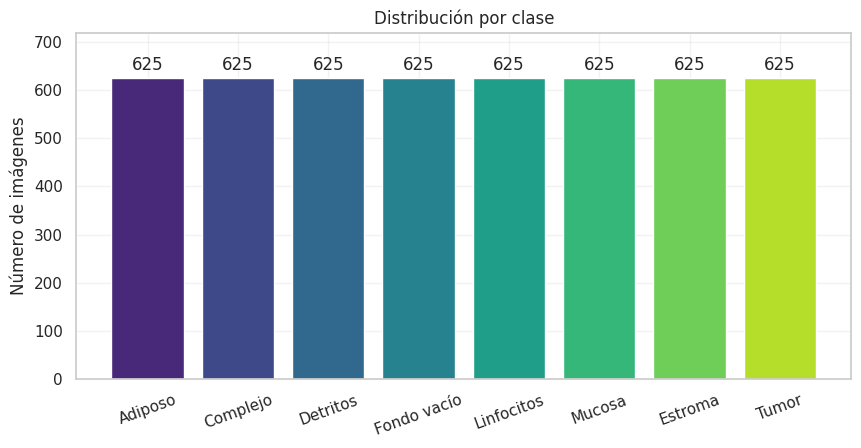

Total de imágenes : 5,000
Clase más grande  : Adiposo (625)
Clase más pequeña : Adiposo (625)
Ratio de desbalance: 1.0:1
✅ Dataset balanceado: no hace falta class_weight ni sobremuestreo. El 'alto accuracy engañoso' por clase dominante no es un riesgo aquí, aunque igual usamos Macro F1.


In [7]:
# Contar imágenes por clase (mismo enfoque del slide)
class_counts = {cls: len([f for f in os.listdir(RAW_DIR / cls) if f.lower().endswith(IMG_EXT)])
                for cls in CLASS_DIRS}

fig, ax = plt.subplots(figsize=(10, 4.5))
labels = [pretty_name(c) for c in class_counts]
bars = ax.bar(labels, class_counts.values(), color=sns.color_palette('viridis', len(class_counts)))
ax.bar_label(bars, padding=3)
ax.set_title('Distribución por clase'); ax.set_ylabel('Número de imágenes')
ax.set_ylim(0, max(class_counts.values()) * 1.15)
plt.xticks(rotation=20)
save_fig('eda_distribucion_clases')

max_c, min_c = max(class_counts.values()), min(class_counts.values())
print(f"Total de imágenes : {sum(class_counts.values()):,}")
print(f"Clase más grande  : {pretty_name(max(class_counts, key=class_counts.get))} ({max_c})")
print(f"Clase más pequeña : {pretty_name(min(class_counts, key=class_counts.get))} ({min_c})")
print(f"Ratio de desbalance: {max_c/min_c:.1f}:1")
if max_c / min_c < 1.5:
    print("✅ Dataset balanceado: no hace falta class_weight ni sobremuestreo. El 'alto accuracy engañoso' "
          "por clase dominante no es un riesgo aquí, aunque igual usamos Macro F1.")
else:
    print("⚠️ Hay desbalance relevante: se recomienda usar class_weight o más peso a las clases minoritarias.")

### 3.2 Visualización de muestras

Antes de modelar conviene **mirar** los datos. Mostramos 6 imágenes por cada tipo de tejido para entender qué patrón visual distingue a cada clase.

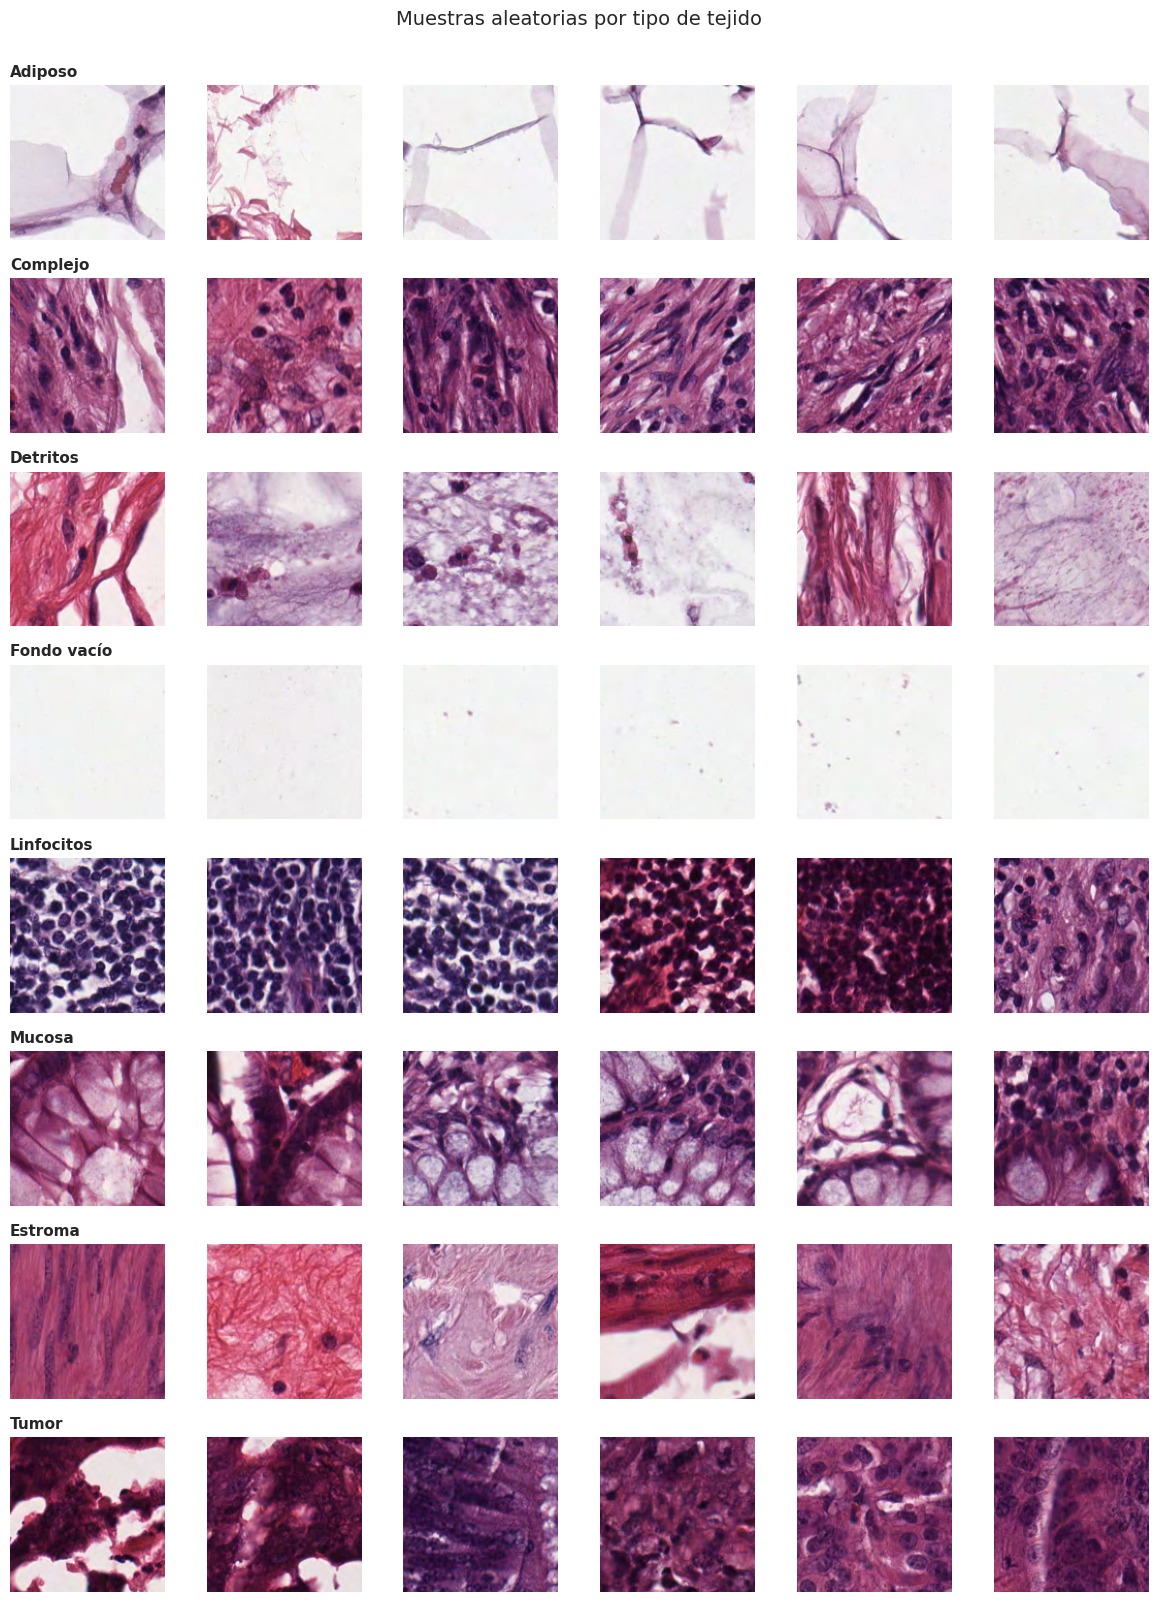

In [8]:
N_SHOW = 6
fig, axes = plt.subplots(NUM_CLASSES, N_SHOW, figsize=(N_SHOW * 2, NUM_CLASSES * 2))
rng = random.Random(SEED)
for i, cls in enumerate(CLASS_DIRS):
    files = sorted(os.listdir(RAW_DIR / cls))
    for j, fname in enumerate(rng.sample(files, N_SHOW)):
        axes[i, j].imshow(Image.open(RAW_DIR / cls / fname))
        axes[i, j].axis('off')
    axes[i, 0].set_title(pretty_name(cls), fontsize=11, loc='left', fontweight='bold')
plt.suptitle('Muestras aleatorias por tipo de tejido', fontsize=14, y=1.0)
plt.tight_layout()
save_fig('eda_muestras')

### 3.3 Propiedades, auditoría de calidad y análisis de color

Recorremos **todas** las imágenes una sola vez (son solo 5,000 y pequeñas) y construimos una tabla de metadatos con:

- **Propiedades:** ancho, alto, modo de color/canales.
- **Imágenes corruptas:** `Image.open().verify()`.
- **Duplicados exactos:** hash MD5 del archivo (`hashlib`).
- **Ruido visual:** brillo medio, nitidez (varianza del Laplaciano, bajo = desenfocada) y color medio RGB por imagen.

In [9]:
def md5_file(path, chunk=1 << 20):
    h = hashlib.md5()
    with open(path, 'rb') as f:
        for block in iter(lambda: f.read(chunk), b''):
            h.update(block)
    return h.hexdigest()

def laplacian_variance(gray):
    """Nitidez: varianza del Laplaciano (valores bajos = imagen desenfocada)."""
    lap = (4 * gray[1:-1, 1:-1] - gray[:-2, 1:-1] - gray[2:, 1:-1] - gray[1:-1, :-2] - gray[1:-1, 2:])
    return float(lap.var())

records = []
for cls in CLASS_DIRS:
    for p in sorted((RAW_DIR / cls).iterdir()):
        if p.suffix.lower() not in IMG_EXT:
            continue
        rec = {'path': str(p), 'class': cls, 'file': p.name, 'md5': md5_file(p), 'corrupt': False}
        try:
            with Image.open(p) as im:
                im.verify()                      # detecta archivos corruptos (deja la imagen inutilizable)
            with Image.open(p) as im:            # se reabre para leer los datos
                rec.update(width=im.width, height=im.height, mode=im.mode, channels=len(im.getbands()))
                arr = np.asarray(im.convert('RGB'), dtype=np.float32)
            gray = arr.mean(axis=2)
            rec.update(brightness=float(gray.mean()), sharpness=laplacian_variance(gray),
                       mean_r=float(arr[..., 0].mean()), mean_g=float(arr[..., 1].mean()),
                       mean_b=float(arr[..., 2].mean()))
        except Exception as e:
            rec.update(corrupt=True, error=str(e))
        records.append(rec)

df_meta = pd.DataFrame(records)
df_meta['label_name'] = df_meta['class'].map(pretty_name)
print(f"Imágenes analizadas: {len(df_meta):,}")
display(df_meta.head(3))

Imágenes analizadas: 5,000


,path,class,file,md5,corrupt,width,height,mode,channels,brightness,sharpness,mean_r,mean_g,mean_b,label_name
0,proyecto_cnn/data/raw/ADIPOSE/ADIPOSE_0000.png,ADIPOSE,ADIPOSE_0000.png,05968d70286c0f0892dcde855c9b6a33,False,150,150,RGB,3,213.966843,227.645721,218.272888,205.882492,217.745193,Adiposo
1,proyecto_cnn/data/raw/ADIPOSE/ADIPOSE_0001.png,ADIPOSE,ADIPOSE_0001.png,2feeeac9c3104b9c2f0528b3427c6897,False,150,150,RGB,3,236.574707,64.673042,240.101639,235.041336,234.581207,Adiposo
2,proyecto_cnn/data/raw/ADIPOSE/ADIPOSE_0002.png,ADIPOSE,ADIPOSE_0002.png,c887f5c5be830f5c7baf5a9fc340ebe2,False,150,150,RGB,3,236.195160,239.732040,237.306137,234.397827,236.881561,Adiposo


In [10]:
# ---- Dimensiones y canales (equivalente al slide, pero sobre todo el dataset) ----
ok = df_meta[~df_meta.corrupt]
print("📐 DIMENSIONES Y CANALES")
print(f"  Resoluciones distintas : {Counter(zip(ok.width, ok.height))}")
print(f"  Canales                : {Counter(ok.channels)}")
print(f"  Modos de color         : {Counter(ok['mode'])}")
print(f"  Aspecto promedio (w/h) : {ok.width.mean() / ok.height.mean():.2f}")

# ---- Auditoría de calidad ----
n_corrupt = int(df_meta.corrupt.sum())
dups = df_meta[~df_meta.corrupt & df_meta.duplicated('md5', keep=False)]
n_dup_extra = int(df_meta[~df_meta.corrupt].duplicated('md5', keep='first').sum())

print("\n🧪 AUDITORÍA DE CALIDAD")
print(f"  Imágenes corruptas        : {n_corrupt} ({n_corrupt/len(df_meta):.2%})")
print(f"  Duplicados exactos (extra): {n_dup_extra}")
if n_dup_extra:
    cross = dups.groupby('md5')['class'].nunique()
    print(f"  Grupos duplicados que cruzan clases distintas: {(cross > 1).sum()}")

# ---- Ruido visual: valores atípicos por regla IQR ----
def iqr_bounds(s, k=1.5):
    q1, q3 = s.quantile([.25, .75]); i = q3 - q1
    return q1 - k * i, q3 + k * i

lo_b, hi_b = iqr_bounds(ok.brightness)
lo_s, hi_s = iqr_bounds(ok.sharpness)
out_dark   = ok[ok.brightness < lo_b]
out_bright = ok[ok.brightness > hi_b]
out_blur   = ok[ok.sharpness < lo_s]
print("\n🌫️  RUIDO VISUAL (atípicos por IQR)")
print(f"  Muy oscuras   : {len(out_dark)}   |   Muy brillantes: {len(out_bright)}   |   Desenfocadas: {len(out_blur)}")

📐 DIMENSIONES Y CANALES
  Resoluciones distintas : Counter({(150, 150): 5000})
  Canales                : Counter({3: 5000})
  Modos de color         : Counter({'RGB': 5000})
  Aspecto promedio (w/h) : 1.00

🧪 AUDITORÍA DE CALIDAD
  Imágenes corruptas        : 0 (0.00%)
  Duplicados exactos (extra): 0

🌫️  RUIDO VISUAL (atípicos por IQR)
  Muy oscuras   : 0   |   Muy brillantes: 0   |   Desenfocadas: 0


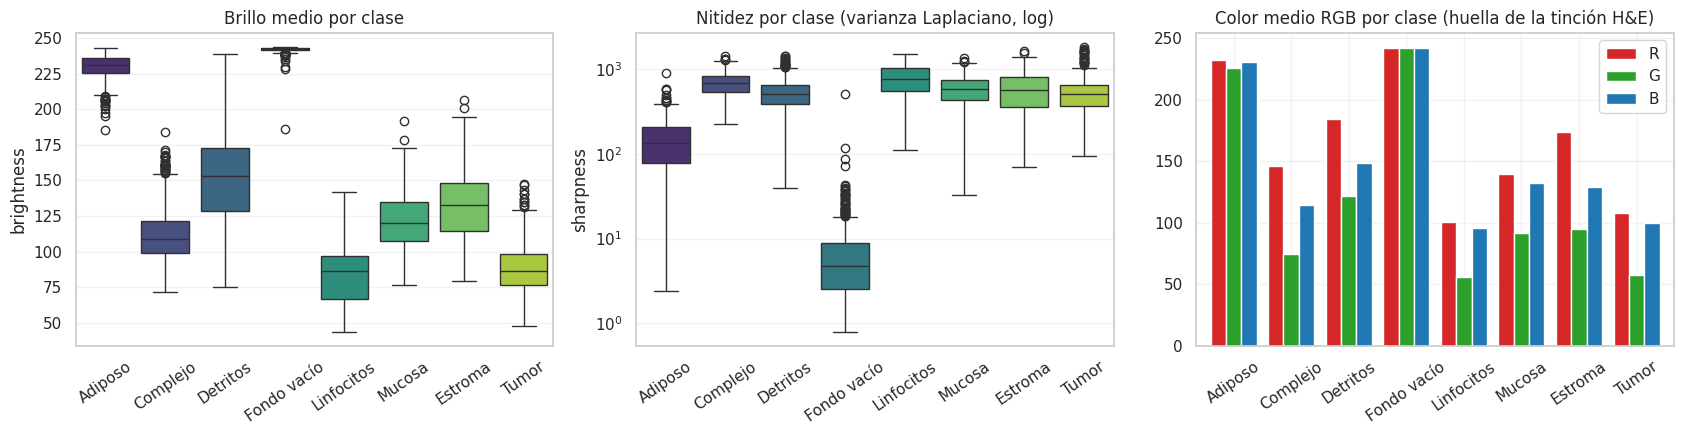

In [11]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))
order = [pretty_name(c) for c in CLASS_DIRS]

sns.boxplot(data=ok, x='label_name', y='brightness', order=order, ax=axes[0], hue='label_name', palette='viridis', legend=False)
axes[0].set_title('Brillo medio por clase'); axes[0].set_xlabel(''); axes[0].tick_params(axis='x', rotation=35)

sns.boxplot(data=ok, x='label_name', y='sharpness', order=order, ax=axes[1], hue='label_name', palette='viridis', legend=False)
axes[1].set_yscale('log'); axes[1].set_title('Nitidez por clase (varianza Laplaciano, log)')
axes[1].set_xlabel(''); axes[1].tick_params(axis='x', rotation=35)

rgb = ok.groupby('label_name')[['mean_r', 'mean_g', 'mean_b']].mean().loc[order]
rgb.plot(kind='bar', ax=axes[2], color=['#d62728', '#2ca02c', '#1f77b4'], width=0.8)
axes[2].set_title('Color medio RGB por clase (huella de la tinción H&E)')
axes[2].set_xlabel(''); axes[2].legend(['R', 'G', 'B']); axes[2].tick_params(axis='x', rotation=35)
plt.tight_layout()
save_fig('eda_calidad_color')

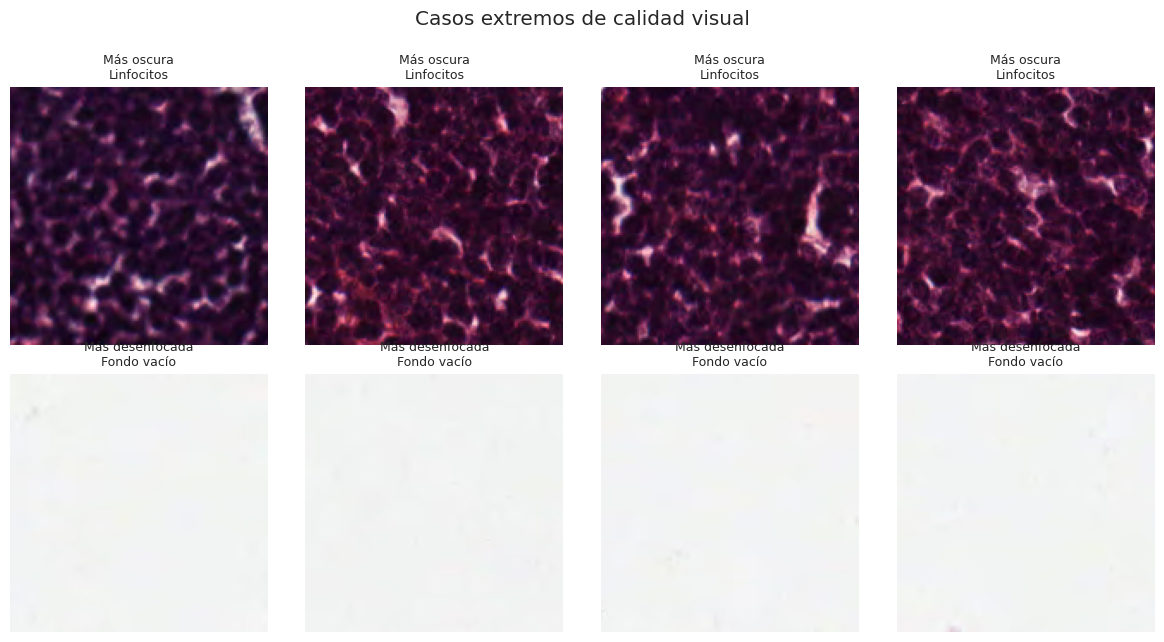

In [12]:
# Ejemplos de imágenes atípicas (las más oscuras y las más desenfocadas)
extremos = pd.concat([ok.nsmallest(4, 'brightness').assign(motivo='Más oscura'),
                      ok.nsmallest(4, 'sharpness').assign(motivo='Más desenfocada')])
fig, axes = plt.subplots(2, 4, figsize=(12, 6.4))
for ax, (_, r) in zip(axes.ravel(), extremos.iterrows()):
    ax.imshow(Image.open(r['path'])); ax.axis('off')
    ax.set_title(f"{r['motivo']}\n{pretty_name(r['class'])}", fontsize=9)
plt.suptitle('Casos extremos de calidad visual', y=1.0)
plt.tight_layout()
save_fig('eda_extremos')

### 3.4 Decisiones tras el EDA

1. **Corruptas:** excluirlas e indicar cuántas se encontraron.
2. **Duplicados exactos:** eliminar copias redundantes dentro de la misma etiqueta; si una misma imagen aparece con **etiquetas distintas**, detener el proceso y revisar. Un hash solo comprueba duplicados exactos de archivos, no similitud visual ni procedencia de lámina.
3. **Atípicos de brillo/nitidez:** conservarlos; la variación visual puede ser parte del problema real y no se deben borrar muestras sin revisión.
4. **Balance:** comprobar tras la limpieza; no asumir balance perfecto si se excluyeron ejemplos.
5. **Procedencia:** el artículo de Kather indica 10 muestras originales. La distribución de Hugging Face usada aquí no trae una columna verificada `patient_id/slide_id` por recorte. **Sin esa columna no se puede demostrar una partición independiente por paciente**, aunque el hash no se repita.


In [13]:
# No ocultar contradicciones de etiquetas en imágenes idénticas.
valid_meta = df_meta.loc[~df_meta.corrupt].copy()
conflicts = valid_meta.groupby('md5')['class'].nunique()
conflicting_hashes = conflicts[conflicts > 1]
assert conflicting_hashes.empty, (
    f"Hay {len(conflicting_hashes)} imágenes idénticas con etiquetas diferentes. "
    "Revisar manualmente antes de continuar.")
df_clean = valid_meta.drop_duplicates('md5', keep='first').reset_index(drop=True)
print(f"Dataset original : {len(df_meta):,} imágenes")
print(f"Corruptas        : -{n_corrupt}")
print(f"Duplicadas       : -{n_dup_extra}")
print(f"Dataset limpio   : {len(df_clean):,} imágenes\n")
display(df_clean['label_name'].value_counts().rename('imágenes').to_frame().T)


Dataset original : 5,000 imágenes
Corruptas        : -0
Duplicadas       : -0
Dataset limpio   : 5,000 imágenes



label_name,Adiposo,Complejo,Detritos,Fondo vacío,Linfocitos,Mucosa,Estroma,Tumor
imágenes,625,625,625,625,625,625,625,625


---
## 🔄 Fase 4: Preprocesamiento y Data Augmentation

### 4.1 División 70 / 15 / 15: qué garantiza y qué NO

La división se establece una sola vez y se guarda en un **manifiesto CSV**. Se usa `stratify` para que las ocho categorías mantengan proporciones similares.

| Partición | Uso |
|---|---|
| **train (70%)** | Ajustar pesos (con augmentation). |
| **val (15%)** | Elegir arquitectura, época y decisiones de inferencia. |
| **test (15%)** | Evaluación descriptiva final, **sin seleccionar/ajustar modelos después**. |

**Precaución científica:** esta es una división **por recorte de imagen**, no necesariamente por paciente o lámina. El artículo original indica diez muestras; no disponemos de IDs de origen verificables en la exportación utilizada. `MD5` impide copiar exactamente el mismo archivo en dos particiones, pero **no garantiza ausencia de dependencia histológica**. En la documentación y conclusiones se reportará como validación *interna por recortes*; no como validación clínica externa.

Si más adelante consiguen un CSV fiable con columnas `file,slide_id` (el nombre de archivo exportado y la lámina de procedencia), pueden guardarlo como `proyecto_cnn/procedencia_laminas.csv`. La celda siguiente intentará hacer una división por grupos y comprobar que aparecen las ocho clases en los tres conjuntos. No se inventarán IDs.


In [14]:
# Split reproducible. Si hay IDs de lámina fiables, se usa separación por grupos;
# de lo contrario se declara explícitamente el alcance del split por parche.
PROVENANCE_CSV = PROJECT_DIR / 'procedencia_laminas.csv'
SPLIT_BY_SLIDE = PROVENANCE_CSV.exists()
SPLIT_PROTOCOL = 'estratificado_por_parche; NO independiente por paciente/lámina'

if SPLIT_BY_SLIDE:
    from sklearn.model_selection import GroupShuffleSplit
    origin = pd.read_csv(PROVENANCE_CSV)
    assert {'file', 'slide_id'}.issubset(origin.columns), 'CSV de procedencia: columnas requeridas file,slide_id'
    assert not origin['file'].duplicated().any(), 'Existen archivos repetidos en el CSV de procedencia'
    labeled = df_clean.merge(origin[['file','slide_id']], on='file', how='left', validate='one_to_one')
    assert labeled['slide_id'].notna().all(), 'Faltan slide_id verificados para algunas imágenes'
    groups1 = GroupShuffleSplit(n_splits=1, test_size=0.30, random_state=SEED)
    tr, rem = next(groups1.split(labeled, groups=labeled['slide_id']))
    df_train = labeled.iloc[tr].copy(); remaining = labeled.iloc[rem].copy()
    groups2 = GroupShuffleSplit(n_splits=1, test_size=0.50, random_state=SEED)
    va, te = next(groups2.split(remaining, groups=remaining['slide_id']))
    df_val = remaining.iloc[va].copy(); df_test = remaining.iloc[te].copy()
    assert set(df_train['class']) == set(df_val['class']) == set(df_test['class']) == set(CLASS_DIRS), (
        'La partición por láminas no incluye las ocho clases en todos los conjuntos. '
        'Se requiere otra estrategia con IDs reales; NO pasar silenciosamente a mezcla por recortes.')
    assert not(set(df_train.slide_id) & set(df_val.slide_id))
    assert not(set(df_train.slide_id) & set(df_test.slide_id))
    assert not(set(df_val.slide_id) & set(df_test.slide_id))
    SPLIT_PROTOCOL = 'por lámina (GroupShuffleSplit); independencia según CSV de procedencia aportado'
else:
    df_train, df_tmp = train_test_split(df_clean, test_size=0.30, stratify=df_clean['class'], random_state=SEED)
    df_val, df_test = train_test_split(df_tmp, test_size=0.50, stratify=df_tmp['class'], random_state=SEED)
    print('⚠️  Sin IDs de lámina: división estratificada POR PARCHE. No se puede afirmar independencia por paciente.')

# Evita mezclar ejecuciones de distintos splits.
if PROC_DIR.exists():
    shutil.rmtree(PROC_DIR)
for split_name, part in [('train', df_train), ('val', df_val), ('test', df_test)]:
    for _, r in part.iterrows():
        dst = PROC_DIR / split_name / r['class']
        dst.mkdir(parents=True, exist_ok=True)
        shutil.copy2(r['path'], dst / r['file'])

h_tr, h_va, h_te = set(df_train.md5), set(df_val.md5), set(df_test.md5)
assert not (h_tr & h_va or h_tr & h_te or h_va & h_te), 'Archivos idénticos en particiones distintas'
assert (len(df_train) + len(df_val) + len(df_test)) == len(df_clean)
manifest = pd.concat([df_train.assign(split='train'), df_val.assign(split='val'), df_test.assign(split='test')])
manifest[['file', 'class', 'md5', 'split'] + (['slide_id'] if SPLIT_BY_SLIDE else [])].to_csv(
    PROC_DIR / 'manifest_splits.csv', index=False)
print('✅ Sin archivos exactamente duplicados entre particiones (comprobado por MD5).')
print('Protocolo:', SPLIT_PROTOCOL)
split_table = pd.DataFrame({'train': df_train['label_name'].value_counts(),
                            'val': df_val['label_name'].value_counts(),
                            'test': df_test['label_name'].value_counts()}).fillna(0).astype(int)
split_table.loc['TOTAL'] = split_table.sum()
display(split_table)


⚠️  Sin IDs de lámina: división estratificada POR PARCHE. No se puede afirmar independencia por paciente.
✅ Sin archivos exactamente duplicados entre particiones (comprobado por MD5).
Protocolo: estratificado_por_parche; NO independiente por paciente/lámina


,train,val,test
label_name,,,
Adiposo,438,93,94
Complejo,438,94,93
Detritos,437,94,94
Estroma,437,94,94
Fondo vacío,437,94,94
Linfocitos,437,94,94
Mucosa,438,93,94
Tumor,438,94,93
TOTAL,3500,750,750


### 4.2 Data augmentation: qué técnicas y por qué

El slide *«Guía Estratégica de Data Augmentation»* pide aplicar el **Principio Rectificador**: *toda transformación debe generar una imagen que podría existir en el mundo real*. Evaluamos cada técnica para nuestro dataset:

| Técnica | ¿La usamos? | Justificación para histología |
|---|:---:|---|
| **Flip horizontal** | ✅ | El tejido no tiene izquierda ni derecha; un espejo sigue siendo un parche plausible. |
| **Flip vertical** | ✅ | A diferencia de personas o autos, no hay "arriba" fijo en un corte de tejido visto al microscopio. |
| **Rotación (±90°)** | ✅ | Los parches se recortan en cualquier orientación de la lámina, así que rotar es natural. |
| **Zoom (±10 %)** | ✅ (leve) | Todas las imágenes están a 20x, no hay multiescala natural, por eso solo un zoom pequeño para no deformar la textura. |
| **Brillo / Contraste (±10 %)** | ✅ (suave) | La tinción H&E varía entre láminas y sesiones de escaneo. Se usa poco porque el color sí aporta información diagnóstica. |
| Cambios de matiz / saturación fuertes | ❌ | Alterarían los colores de la tinción, que distinguen los tejidos. |

> ⚠️ **Regla de oro:** el augmentation se aplica **solo en entrenamiento**. Validación y prueba van sin transformaciones y con `shuffle=False`, para que las predicciones se puedan alinear con sus etiquetas reales.

In [15]:
AUG_CONFIG = {'rotation': 0.25, 'zoom': 0.10, 'brightness': 0.10, 'contrast': 0.10}   # rotation 0.25 = rango hasta ±90° (Keras interpreta fraction of full turn)

def build_augmentation(rotation=0.25, zoom=0.10, brightness=0.10, contrast=0.10):
    """Augmentation como bloque Sequential de capas nativas (solo actúa con training=True)."""
    return tf.keras.Sequential([
        tf.keras.layers.RandomFlip('horizontal_and_vertical'),
        tf.keras.layers.RandomRotation(rotation, fill_mode='reflect'),
        tf.keras.layers.RandomZoom(zoom, fill_mode='reflect'),
        tf.keras.layers.RandomBrightness(brightness, value_range=(0, 255)),
        tf.keras.layers.RandomContrast(contrast),
    ], name='data_augmentation')

augmentation = build_augmentation(**AUG_CONFIG)
print("✅ Bloque de augmentation definido:", [l.__class__.__name__ for l in augmentation.layers])


✅ Bloque de augmentation definido: ['RandomFlip', 'RandomRotation', 'RandomZoom', 'RandomBrightness', 'RandomContrast']


### 4.3 Pipeline moderno con `tf.data`

Seguimos el slide *«El Pipeline Moderno con tf.data (Recomendado)»*: `image_dataset_from_directory` → `map` → `prefetch(AUTOTUNE)`.

📝 **Una decisión de diseño:** el reescalado `1/255` lo colocamos como **primera capa dentro de cada modelo** (no en el `map`). Así los modelos reciben píxeles 0–255, y el día del despliegue (API Flask, TFLite) basta con enviar la imagen cruda y es imposible olvidar normalizarla. El resto del pipeline es el del slide.

In [16]:
AUTOTUNE = tf.data.AUTOTUNE
common = dict(labels='inferred', label_mode='categorical', image_size=IMG_SIZE, batch_size=BATCH_SIZE)

# 1. Carga nativa
train_raw = tf.keras.utils.image_dataset_from_directory(PROC_DIR / 'train', seed=SEED, shuffle=True,  **common)
val_raw   = tf.keras.utils.image_dataset_from_directory(PROC_DIR / 'val',   seed=SEED, shuffle=False, **common)  # ¡CRÍTICO!
test_raw  = tf.keras.utils.image_dataset_from_directory(PROC_DIR / 'test',  seed=SEED, shuffle=False, **common)  # ¡CRÍTICO!

class_names  = train_raw.class_names
CLASS_LABELS = [pretty_name(c) for c in class_names]
assert class_names == val_raw.class_names == test_raw.class_names, "Las particiones no comparten el orden de clases"
assert len(class_names) == NUM_CLASSES
print("\nOrden de clases:", dict(enumerate(CLASS_LABELS)))

# 2 y 3. Mapeo optimizado con AUTOTUNE
def make_pipeline(ds, is_training=False, augment=False):
    if is_training and augment:                       # augmentation SOLO en train
        ds = ds.map(lambda x, y: (augmentation(x, training=True), y), num_parallel_calls=AUTOTUNE)
    if not is_training:
        ds = ds.cache()                               # val/test son estáticos: se cachean
    return ds.prefetch(AUTOTUNE)

train_ds       = make_pipeline(train_raw, is_training=True,  augment=True)    # Modelos 1 y 2 (augmentation en el pipeline)
train_ds_noaug = make_pipeline(train_raw, is_training=True,  augment=False)   # Modelo 3 (augmentation dentro del grafo)
val_ds         = make_pipeline(val_raw)
test_ds        = make_pipeline(test_raw)

xb, yb = next(iter(train_ds))
print(f"\nBatch de entrenamiento -> imágenes {xb.shape} ({xb.dtype}), etiquetas {yb.shape}")
print(f"Rango de píxeles: [{float(tf.reduce_min(xb)):.0f}, {float(tf.reduce_max(xb)):.0f}]  (el modelo reescala a [0,1])")

# Verificación de shuffle=False: dos pasadas sobre val deben dar exactamente el mismo orden de etiquetas
pass1 = np.concatenate([np.argmax(y.numpy(), 1) for _, y in val_ds])
pass2 = np.concatenate([np.argmax(y.numpy(), 1) for _, y in val_ds])
assert np.array_equal(pass1, pass2)
print("✅ Validación determinista (shuffle=False verificado): las etiquetas se alinean con las predicciones.")

Found 3500 files belonging to 8 classes.
Found 750 files belonging to 8 classes.
Found 750 files belonging to 8 classes.

Orden de clases: {0: 'Adiposo', 1: 'Complejo', 2: 'Detritos', 3: 'Fondo vacío', 4: 'Linfocitos', 5: 'Mucosa', 6: 'Estroma', 7: 'Tumor'}

Batch de entrenamiento -> imágenes (32, 150, 150, 3) (<dtype: 'float32'>), etiquetas (32, 8)
Rango de píxeles: [0, 255]  (el modelo reescala a [0,1])
✅ Validación determinista (shuffle=False verificado): las etiquetas se alinean con las predicciones.


### 4.4 Referencia: el enfoque clásico con `ImageDataGenerator`

El slide *«Fase 3: Preprocesamiento con ImageDataGenerator»* muestra el método clásico, hoy **deprecado**. Lo dejamos como demostración (si la versión de Keras ya no lo incluye, la celda lo avisa) para evidenciar la misma regla de oro: *train con augmentation, validación solo con rescale y `shuffle=False`*.

In [17]:
try:
    IDG = tf.keras.preprocessing.image.ImageDataGenerator           # puede no existir en Keras 3
    train_datagen = IDG(rescale=1./255, rotation_range=20, zoom_range=0.15,
                        horizontal_flip=True, vertical_flip=True)
    val_datagen   = IDG(rescale=1./255)                              # SIN augmentation
    legacy_train = train_datagen.flow_from_directory(PROC_DIR / 'train', target_size=IMG_SIZE,
                        batch_size=BATCH_SIZE, seed=SEED, shuffle=True)
    legacy_val   = val_datagen.flow_from_directory(PROC_DIR / 'val', target_size=IMG_SIZE,
                        batch_size=BATCH_SIZE, seed=SEED, shuffle=False)   # < ¡CRÍTICO!
    print("✅ ImageDataGenerator disponible (solo demostración; el pipeline real usa tf.data).")
except Exception as e:
    print(f"ℹ️ ImageDataGenerator no está disponible en esta versión de Keras ({type(e).__name__}). "
          "Es esperable: está deprecado y por eso usamos tf.data, como recomienda el slide.")

Found 3500 images belonging to 8 classes.
Found 750 images belonging to 8 classes.
✅ ImageDataGenerator disponible (solo demostración; el pipeline real usa tf.data).


### 4.5 Visualización del augmentation

Una imagen original y 9 versiones aumentadas. Verificamos el Principio Rectificador a simple vista: ¿todas podrían ser un parche real?

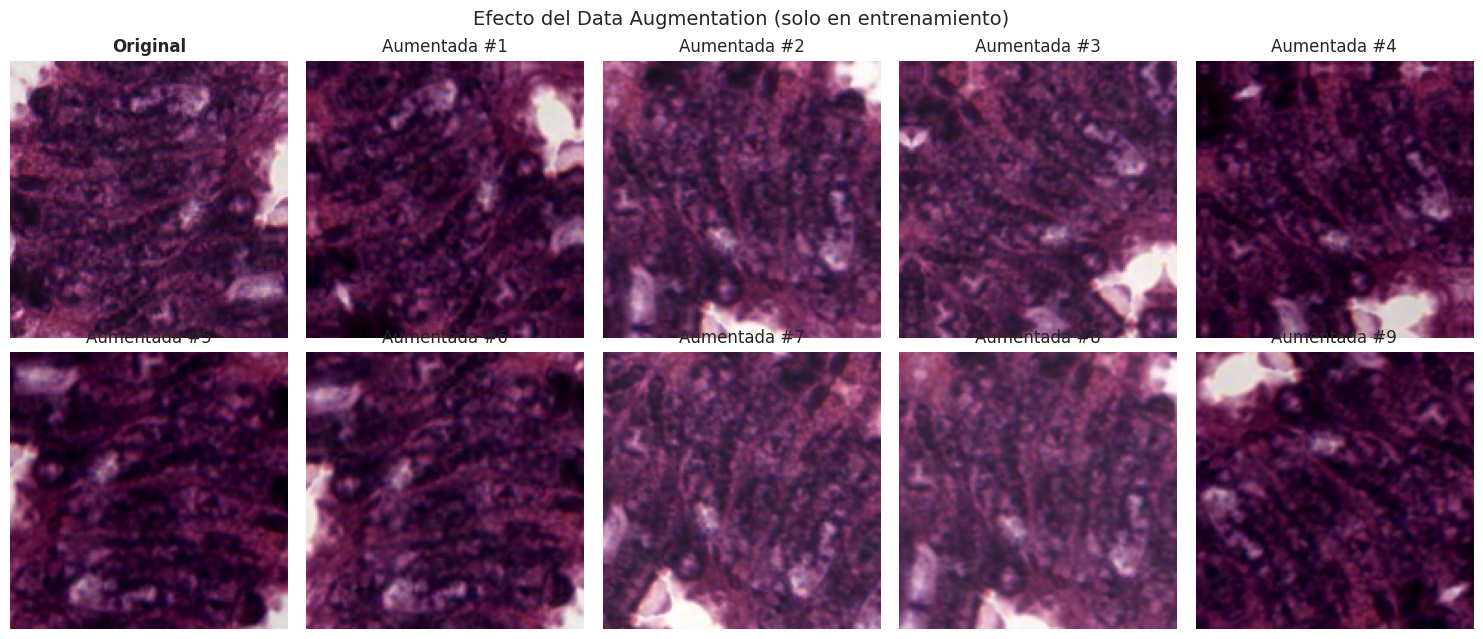

In [18]:
sample_img = next(iter(train_raw))[0][:1]          # imagen de TRAIN, no se consulta validación para ilustrar augmentation
fig, axes = plt.subplots(2, 5, figsize=(15, 6.5))
axes[0, 0].imshow(sample_img[0].numpy().astype('uint8')); axes[0, 0].set_title('Original', fontweight='bold')
for i in range(1, 10):
    aug = augmentation(sample_img, training=True)
    ax = axes[i // 5, i % 5]
    ax.imshow(np.clip(aug[0].numpy(), 0, 255).astype('uint8')); ax.set_title(f'Aumentada #{i}')
for ax in axes.ravel(): ax.axis('off')
plt.suptitle('Efecto del Data Augmentation (solo en entrenamiento)', fontsize=14)
plt.tight_layout()
save_fig('augmentation_ejemplos')


---
## 🏗️ Fase 5: Arquitecturas, Configuración y Entrenamiento

### 5.1 Configuración centralizada (el «Panel de Control»)

Un solo diccionario concentra los hiperparámetros (slide *«Fase 5»*). Si queremos probar otro valor, se cambia **aquí** y en ningún otro lugar.

- `weight_decay` → regularización L2 **desacoplada** dentro del optimizador.
- `label_smoothing` → evita la sobreconfianza (las etiquetas objetivo pasan de 1.0 a 0.9 y el resto se reparte).
- Métricas robustas: `accuracy` y `AUC(multi_label=True)`.

In [19]:
# Panel de Control Central (CONFIG)
CONFIG = {
    'learning_rate': 1e-3,
    'epochs': 50,
    'batch_size': BATCH_SIZE,
    'optimizer': 'adam',
    'weight_decay': 1e-4,        # desacoplamiento de regularización L2 (en el optimizador)
    'label_smoothing': 0.1,      # previene sobreconfianza (1.0 -> 0.9)
    # --- Parámetros del pipeline y callbacks (también centralizados) ---
    'l2_layers': 1e-4,           # L2 en capas del Modelo 3
    'early_stopping_patience': 10,
    'reduce_lr_patience': 5,
    'reduce_lr_factor': 0.5,
    'min_lr': 1e-6,
    'seed': SEED,
    'img_size': IMG_SIZE,
    'augmentation': AUG_CONFIG,
}
print(json.dumps(CONFIG, indent=2, default=str))

{
  "learning_rate": 0.001,
  "epochs": 50,
  "batch_size": 32,
  "optimizer": "adam",
  "weight_decay": 0.0001,
  "label_smoothing": 0.1,
  "l2_layers": 0.0001,
  "early_stopping_patience": 10,
  "reduce_lr_patience": 5,
  "reduce_lr_factor": 0.5,
  "min_lr": 1e-06,
  "seed": 42,
  "img_size": [
    150,
    150
  ],
  "augmentation": {
    "rotation": 0.25,
    "zoom": 0.1,
    "brightness": 0.1,
    "contrast": 0.1
  }
}


### 5.2 Tres arquitecturas, tres propósitos

| Modelo | Idea | Qué aporta |
|---|---|---|
| **1 · CNN Baseline** | 3 bloques `Conv+BN+ReLU+Pool` (32→64→128), GAP, `Dense+Dropout` | Confirmar que el pipeline funciona de principio a fin *antes* de invertir en algo complejo |
| **2 · CNN Mejorada (ResNet-style)** | Bloques residuales con *skip connection* | Combatir el desvanecimiento del gradiente y permitir más profundidad |
| **3 · CNN Optimizada** | Augmentation dentro del grafo, *stem* con *stride* agresivo, L2 en todas las capas, Dropout escalonado | Mejor generalización con tamaño controlado |

Todas terminan en `GlobalAveragePooling2D` (muy pocos parámetros comparado con `Flatten`) y `softmax` de 8 neuronas. La primera capa de cada una es `Rescaling(1/255)`.

In [20]:
# ============================================================ MODELO 1: CNN BASELINE
def build_baseline_model(input_shape, num_classes):
    model = tf.keras.Sequential([
        tf.keras.layers.Input(shape=input_shape),
        tf.keras.layers.Rescaling(1. / 255),

        # Bloque Conv repetido (32 -> 64 -> 128)
        tf.keras.layers.Conv2D(32, (3, 3), padding='same'),
        tf.keras.layers.BatchNormalization(),
        tf.keras.layers.Activation('relu'),
        tf.keras.layers.MaxPooling2D((2, 2)),

        tf.keras.layers.Conv2D(64, (3, 3), padding='same'),
        tf.keras.layers.BatchNormalization(),
        tf.keras.layers.Activation('relu'),
        tf.keras.layers.MaxPooling2D((2, 2)),

        tf.keras.layers.Conv2D(128, (3, 3), padding='same'),
        tf.keras.layers.BatchNormalization(),
        tf.keras.layers.Activation('relu'),
        tf.keras.layers.MaxPooling2D((2, 2)),

        # Transición y Clasificador
        tf.keras.layers.GlobalAveragePooling2D(),
        tf.keras.layers.Dense(256, activation='relu'),
        tf.keras.layers.Dropout(0.5),
        tf.keras.layers.Dense(num_classes, activation='softmax'),
    ], name='cnn_baseline')
    return model

In [21]:
# ============================================================ MODELO 2: CNN MEJORADA (ResNet style)
def residual_block(x, filters, stride=1, l2=0.0):
    """Bloque residual: dos convoluciones 3x3 + atajo (skip connection) sumado a la salida."""
    reg = tf.keras.regularizers.l2(l2) if l2 else None
    shortcut = x

    # Ruta principal
    x = tf.keras.layers.Conv2D(filters, (3, 3), strides=stride, padding='same', use_bias=False, kernel_regularizer=reg)(x)
    x = tf.keras.layers.BatchNormalization()(x)
    x = tf.keras.layers.Activation('relu')(x)
    x = tf.keras.layers.Conv2D(filters, (3, 3), padding='same', use_bias=False, kernel_regularizer=reg)(x)
    x = tf.keras.layers.BatchNormalization()(x)

    # Si cambian las dimensiones, el atajo se proyecta con una conv 1x1
    if stride != 1 or shortcut.shape[-1] != filters:
        shortcut = tf.keras.layers.Conv2D(filters, (1, 1), strides=stride, padding='same', use_bias=False, kernel_regularizer=reg)(shortcut)
        shortcut = tf.keras.layers.BatchNormalization()(shortcut)

    # SUMA (Skip Connection o Atajo)
    x = tf.keras.layers.Add()([x, shortcut])
    return tf.keras.layers.Activation('relu')(x)


def build_improved_model(input_shape, num_classes):
    inputs = tf.keras.layers.Input(shape=input_shape)
    x = tf.keras.layers.Rescaling(1. / 255)(inputs)
    x = tf.keras.layers.Conv2D(32, (3, 3), padding='same', use_bias=False)(x)
    x = tf.keras.layers.BatchNormalization()(x)
    x = tf.keras.layers.Activation('relu')(x)
    for filters, stride in [(32, 1), (64, 2), (128, 2), (256, 2)]:
        x = residual_block(x, filters, stride)
    x = tf.keras.layers.GlobalAveragePooling2D()(x)
    x = tf.keras.layers.Dense(256, activation='relu')(x)
    x = tf.keras.layers.Dropout(0.5)(x)
    outputs = tf.keras.layers.Dense(num_classes, activation='softmax')(x)
    return tf.keras.Model(inputs, outputs, name='cnn_mejorada')

In [22]:
# ============================================================ MODELO 3: CNN OPTIMIZADA FINAL
def build_optimized_model(input_shape, num_classes, l2=1e-4, aug=True):
    """Augmentation integrado en el grafo + stem con stride agresivo + L2 en todo + Dropout escalonado.
    aug=False crea una copia 'de inferencia' sin capas de augmentation (útil para exportar)."""
    reg = tf.keras.regularizers.l2(l2)
    inputs = tf.keras.layers.Input(shape=input_shape)
    x = build_augmentation(**AUG_CONFIG)(inputs) if aug else inputs      # solo activo en training
    x = tf.keras.layers.Rescaling(1. / 255)(x)

    # Stem con stride agresivo: reduce rápido la memoria (150 -> 75 -> 38)
    x = tf.keras.layers.Conv2D(32, (5, 5), strides=2, padding='same', use_bias=False, kernel_regularizer=reg)(x)
    x = tf.keras.layers.BatchNormalization()(x)
    x = tf.keras.layers.Activation('relu')(x)
    x = tf.keras.layers.MaxPooling2D((3, 3), strides=2, padding='same')(x)

    # Bloques residuales con L2 y Dropout espacial escalonado
    x = residual_block(x, 64, 1, l2)
    x = residual_block(x, 128, 2, l2)
    x = tf.keras.layers.SpatialDropout2D(0.10)(x)
    x = residual_block(x, 256, 2, l2)
    x = tf.keras.layers.SpatialDropout2D(0.15)(x)
    x = residual_block(x, 256, 1, l2)

    # Cabeza clasificadora con Dropout escalonado (0.3 -> 0.5)
    x = tf.keras.layers.GlobalAveragePooling2D()(x)
    x = tf.keras.layers.Dropout(0.3)(x)
    x = tf.keras.layers.Dense(256, activation='relu', kernel_regularizer=reg)(x)
    x = tf.keras.layers.Dropout(0.5)(x)
    outputs = tf.keras.layers.Dense(num_classes, activation='softmax', kernel_regularizer=reg)(x)
    return tf.keras.Model(inputs, outputs, name='cnn_optimizada')


INPUT_SHAPE = IMG_SIZE + (3,)
model_baseline  = build_baseline_model(INPUT_SHAPE, NUM_CLASSES)
model_improved  = build_improved_model(INPUT_SHAPE, NUM_CLASSES)
model_optimized = build_optimized_model(INPUT_SHAPE, NUM_CLASSES, l2=CONFIG['l2_layers'])
MODELS = {'CNN Baseline': model_baseline, 'CNN Mejorada': model_improved, 'CNN Optimizada': model_optimized}

# Comprobación rápida: las 3 aceptan la misma entrada y devuelven 8 probabilidades que suman 1
for n, m in MODELS.items():
    out = m(xb[:2], training=False).numpy()
    assert out.shape == (2, NUM_CLASSES) and np.allclose(out.sum(1), 1, atol=1e-4), n
print("✅ Las 3 arquitecturas son consistentes con el pipeline.\n")

# Tabla de parámetros (slide: Parámetros Totales / Entrenables / Peso aprox.)
def n_params(weights): return int(sum(np.prod(w.shape) for w in weights))
param_table = pd.DataFrame([{
    'Arquitectura': n,
    'Parámetros totales': f"{m.count_params():,}",
    'Parámetros entrenables': f"{n_params(m.trainable_weights):,}",
    'Peso aprox. (MB, float32)': f"~{m.count_params() * 4 / 1024**2:.1f} MB",
} for n, m in MODELS.items()])
display(param_table.style.hide(axis='index'))

✅ Las 3 arquitecturas son consistentes con el pipeline.



Arquitectura,Parámetros totales,Parámetros entrenables,"Peso aprox. (MB, float32)"
CNN Baseline,"129,224","128,776",~0.5 MB
CNN Mejorada,"1,297,128","1,294,248",~4.9 MB
CNN Optimizada,"2,461,672","2,457,896",~9.4 MB


In [23]:
model_optimized.summary(line_length=100, expand_nested=False)
# Prueba de flujo de datos ANTES de las 50 épocas. No actualiza pesos.
# Comprueba la salida con un ejemplo por cada CNN.
for name, model in MODELS.items():
    probs = model(xb[:1], training=False).numpy()
    assert probs.shape == (1, NUM_CLASSES), f'Forma incorrecta en {name}'
    assert np.all(np.isfinite(probs)) and np.allclose(probs.sum(axis=1), 1.0, atol=1e-4)
print('✅ Smoke test de forward pass correcto para las tres CNN.')


Model: "cnn_optimizada"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                ┃ Output Shape            ┃        Param # ┃ Connected to            ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━┩
│ input_layer_3 (InputLayer)  │ (None, 150, 150, 3)     │              0 │ -                       │
├─────────────────────────────┼─────────────────────────┼────────────────┼─────────────────────────┤
│ data_augmentation           │ (None, 150, 150, 3)     │              0 │ input_layer_3[0][0]     │
│ (Sequential)                │                         │                │                         │
├─────────────────────────────┼─────────────────────────┼────────────────┼─────────────────────────┤
│ rescaling_2 (Rescaling)     │ (None, 150, 150, 3)     │              0 │ data_augmentation[0][0] │
├─────────────────────────────┼─────────────────────────┼────────────────┼─────────────────────────┤
│ conv2d_15 (Conv2D)          │ (None, 75, 75, 32)      │          2,400 │ rescaling_2[0][0]       │
├─────────────────────────────┼─────────────────────────┼────────────────┼─────────────────────────┤
│ batch_normalization_15      │ (None, 75, 75, 32)      │            128 │ conv2d_15[0][0]         │
│ (BatchNormalization)        │                         │                │                         │
├─────────────────────────────┼─────────────────────────┼────────────────┼─────────────────────────┤
│ activation_12 (Activation)  │ (None, 75, 75, 32)      │              0 │ batch_normalization_15… │
├─────────────────────────────┼─────────────────────────┼────────────────┼─────────────────────────┤
│ max_pooling2d_3             │ (None, 38, 38, 32)      │              0 │ activation_12[0][0]     │
│ (MaxPooling2D)              │                         │                │                         │
├─────────────────────────────┼─────────────────────────┼────────────────┼─────────────────────────┤
│ conv2d_16 (Conv2D)          │ (None, 38, 38, 64)      │         18,432 │ max_pooling2d_3[0][0]   │
├─────────────────────────────┼─────────────────────────┼────────────────┼─────────────────────────┤
│ batch_normalization_16      │ (None, 38, 38, 64)      │            256 │ conv2d_16[0][0]         │
│ (BatchNormalization)        │                         │                │                         │
├─────────────────────────────┼─────────────────────────┼────────────────┼─────────────────────────┤
│ activation_13 (Activation)  │ (None, 38, 38, 64)      │              0 │ batch_normalization_16… │
├─────────────────────────────┼─────────────────────────┼────────────────┼─────────────────────────┤
│ conv2d_17 (Conv2D)          │ (None, 38, 38, 64)      │         36,864 │ activation_13[0][0]     │
├─────────────────────────────┼─────────────────────────┼────────────────┼─────────────────────────┤
│ conv2d_18 (Conv2D)          │ (None, 38, 38, 64)      │          2,048 │ max_pooling2d_3[0][0]   │
├─────────────────────────────┼─────────────────────────┼────────────────┼─────────────────────────┤
│ batch_normalization_17      │ (None, 38, 38, 64)      │            256 │ conv2d_17[0][0]         │
│ (BatchNormalization)        │                         │                │                         │
├─────────────────────────────┼─────────────────────────┼────────────────┼─────────────────────────┤
│ batch_normalization_18      │ (None, 38, 38, 64)      │            256 │ conv2d_18[0][0]         │
│ (BatchNormalization)        │                         │                │                         │
├─────────────────────────────┼─────────────────────────┼────────────────┼─────────────────────────┤
│ add_4 (Add)                 │ (None, 38, 38, 64)      │              0 │ batch_normalization_17… │
│                             │                         │                │ batch_normalization_18… │
├─────────────────────────────┼─────────────────────────┼────

 Total params: 2,461,672 (9.39 MB)

 Trainable params: 2,457,896 (9.38 MB)

 Non-trainable params: 3,776 (14.75 KB)

✅ Smoke test de forward pass correcto para las tres CNN.


### 5.3 Automatización: los 5 callbacks profesionales

Vigilancia, ajuste y registro automáticos, sin intervención humana (slide *«Los 5 Callbacks Profesionales»*):

| Callback | Función |
|---|---|
| `ModelCheckpoint` | Guarda solo el mejor modelo (`save_best_only=True`) |
| `EarlyStopping` | Detiene el entrenamiento si `val_loss` no mejora (restaura los pesos con mínima `val_loss`) |
| `ReduceLROnPlateau` | Reduce el *learning rate* al encontrar mesetas |
| `TensorBoard` | Telemetría interactiva |
| `CSVLogger` | Registro persistente en texto plano para trazabilidad |

La mejor época se elige con `val_loss` y la arquitectura final con **Macro F1 en validación**; ambos criterios se documentan y no se confunden. Además agregamos un **sexto callback propio, `ExperimentLogger`**, que escribe un `experiment.log` con marca de tiempo por época. Se explica a fondo en la Fase 10, pero lo definimos aquí porque tiene que acompañar al entrenamiento.


In [24]:
class ExperimentLogger(tf.keras.callbacks.Callback):
    """Callback propio (Fase 10): deja una huella persistente de cada época en experiment.log."""
    def __init__(self, log_file, name):
        super().__init__()
        self.logger = logging.getLogger(f"experimento.{name}")
        self.logger.setLevel(logging.INFO)
        self.logger.propagate = False
        for h in list(self.logger.handlers):
            self.logger.removeHandler(h)
        fh = logging.FileHandler(log_file, mode='w', encoding='utf-8')
        fh.setFormatter(logging.Formatter('[%(asctime)s] %(levelname)s: %(message)s'))
        self.logger.addHandler(fh)
        self.name = name

    def on_train_begin(self, logs=None):
        self.t0 = time.time()
        self.logger.info(f"Inicio del experimento '{self.name}' | parámetros={self.model.count_params():,}")

    def on_epoch_end(self, epoch, logs=None):
        logs = logs or {}
        lr_var = self.model.optimizer.learning_rate
        lr = float(lr_var.numpy()) if hasattr(lr_var, 'numpy') else float(lr_var)
        self.logger.info(
            f"Época {epoch + 1}: loss={logs.get('loss', float('nan')):.4f}, "
            f"acc={logs.get('accuracy', float('nan')):.4f}, "
            f"val_loss={logs.get('val_loss', float('nan')):.4f}, "
            f"val_acc={logs.get('val_accuracy', float('nan')):.4f}, lr={lr:.2e}")

    def on_train_end(self, logs=None):
        self.logger.info(f"Fin del entrenamiento. Duración: {time.time() - self.t0:.1f} s")
        for h in list(self.logger.handlers):
            h.flush()

In [25]:
def train_model(model, train_data, val_data, config, experiment_name):
    """Compila y entrena un modelo con la configuración centralizada y los callbacks profesionales."""
    exp_dir = EXP_DIR / experiment_name
    (exp_dir / 'tensorboard').mkdir(parents=True, exist_ok=True)

    with open(exp_dir / 'config.json', 'w', encoding='utf-8') as f:          # configuración versionada
        json.dump(config, f, indent=2, default=str)

    # Optimizador y Loss avanzados
    optimizer = tf.keras.optimizers.Adam(learning_rate=config['learning_rate'],
                                         weight_decay=config['weight_decay'])
    loss_fn = tf.keras.losses.CategoricalCrossentropy(label_smoothing=config['label_smoothing'])

    # Compilación con métricas robustas
    model.compile(optimizer=optimizer, loss=loss_fn,
                  metrics=['accuracy', tf.keras.metrics.AUC(multi_label=True, name='auc')])

    callbacks = [
        tf.keras.callbacks.ModelCheckpoint(str(exp_dir / 'best_model.keras'), monitor='val_loss',
                                           mode='min', save_best_only=True, verbose=0),
        tf.keras.callbacks.EarlyStopping(monitor='val_loss', patience=config['early_stopping_patience'],
                                         restore_best_weights=True, verbose=1),
        tf.keras.callbacks.ReduceLROnPlateau(monitor='val_loss', factor=config['reduce_lr_factor'],
                                             patience=config['reduce_lr_patience'], min_lr=config['min_lr'], verbose=1),
        tf.keras.callbacks.TensorBoard(log_dir=str(exp_dir / 'tensorboard')),
        tf.keras.callbacks.CSVLogger(str(exp_dir / 'training_log.csv')),
        ExperimentLogger(exp_dir / 'experiment.log', experiment_name),       # callback propio
    ]

    t0 = time.time()
    history = model.fit(train_data, validation_data=val_data, epochs=config['epochs'],
                        callbacks=callbacks, verbose=2)
    train_seconds = time.time() - t0

    # Garantizar que el modelo en memoria corresponde al mejor checkpoint según val_loss.
    best = tf.keras.models.load_model(exp_dir / 'best_model.keras', compile=False)
    model.set_weights(best.get_weights())
    with open(exp_dir / 'model_summary.txt', 'w', encoding='utf-8') as f:
        model.summary(print_fn=lambda s: f.write(s + '\n'))
    return history, exp_dir, train_seconds


### 5.4 Entrenamiento de los tres modelos

- **Modelos 1 y 2:** reciben el pipeline con augmentation (`train_ds`).
- **Modelo 3:** ya lleva el augmentation **dentro del grafo**, así que se entrena con `train_ds_noaug` para **no aplicar el augmentation dos veces**.
- Los tres se validan con el mismo `val_ds` (sin augmentation).

> ⏱️ El tiempo depende de la GPU, la carga del entorno y el número de épocas. No se promete una duración fija. **No usaremos resultados del test para ajustar hiperparámetros.**


In [26]:
TIMESTAMP = datetime.datetime.now().strftime('%Y%m%d_%H%M%S')
EXPERIMENTS = {}

# Los modelos del análisis de arquitectura se vuelven a crear ANTES del entrenamiento.
# Fijar la semilla sobre un modelo ya creado no reinicializa los pesos.
model_builders = [
    ('CNN Baseline', 'baseline', lambda: build_baseline_model(INPUT_SHAPE, NUM_CLASSES), train_ds),
    ('CNN Mejorada', 'mejorada', lambda: build_improved_model(INPUT_SHAPE, NUM_CLASSES), train_ds),
    ('CNN Optimizada', 'optimizada',
     lambda: build_optimized_model(INPUT_SHAPE, NUM_CLASSES, l2=CONFIG['l2_layers']), train_ds_noaug),
]
MODELS = {}
for display_name, slug, builder, data in model_builders:
    print(f"\n{'=' * 78}\n🚀 Entrenando: {display_name}\n{'=' * 78}")
    tf.keras.utils.set_random_seed(SEED)  # semilla ANTES de construir el modelo
    model = builder()
    MODELS[display_name] = model
    hist, exp_dir, secs = train_model(model, data, val_ds, CONFIG, f'{slug}_{TIMESTAMP}')
    EXPERIMENTS[display_name] = {'history': hist, 'dir': exp_dir, 'train_seconds': secs, 'model': model}
    assert (exp_dir / 'best_model.keras').is_file(), f'Falta el checkpoint de {display_name}'
    print(f"✅ {display_name}: {len(hist.history['loss'])} épocas en {secs/60:.1f} min | "
          f"mejor val_loss={min(hist.history['val_loss']):.4f} | mejor val_acc={max(hist.history['val_accuracy']):.4f}")



🚀 Entrenando: CNN Baseline
Epoch 1/50
110/110 - 53s - 482ms/step - accuracy: 0.5569 - auc: 0.9065 - loss: 1.3481 - val_accuracy: 0.3547 - val_auc: 0.6678 - val_loss: 2.1810 - learning_rate: 0.0010
Epoch 2/50
110/110 - 23s - 208ms/step - accuracy: 0.6734 - auc: 0.9458 - loss: 1.1407 - val_accuracy: 0.1253 - val_auc: 0.6623 - val_loss: 3.8002 - learning_rate: 0.0010
Epoch 3/50
110/110 - 24s - 215ms/step - accuracy: 0.7071 - auc: 0.9525 - loss: 1.0906 - val_accuracy: 0.1813 - val_auc: 0.6357 - val_loss: 3.6707 - learning_rate: 0.0010
Epoch 4/50
110/110 - 21s - 188ms/step - accuracy: 0.7409 - auc: 0.9582 - loss: 1.0406 - val_accuracy: 0.2453 - val_auc: 0.7572 - val_loss: 2.9663 - learning_rate: 0.0010
Epoch 5/50
110/110 - 22s - 197ms/step - accuracy: 0.7663 - auc: 0.9654 - loss: 0.9846 - val_accuracy: 0.4893 - val_auc: 0.9291 - val_loss: 1.3888 - learning_rate: 0.0010
Epoch 6/50
110/110 - 20s - 184ms/step - accuracy: 0.7811 - auc: 0.9665 - loss: 0.9721 - val_accuracy: 0.4640 - val_auc: 0.

✅ CNN Baseline: 47 épocas en 19.3 min | mejor val_loss=0.7276 | mejor val_acc=0.9013

🚀 Entrenando: CNN Mejorada
Epoch 1/50
110/110 - 97s - 880ms/step - accuracy: 0.5846 - auc: 0.9073 - loss: 1.3527 - val_accuracy: 0.1253 - val_auc: 0.5310 - val_loss: 6.0414 - learning_rate: 0.0010
Epoch 2/50
110/110 - 81s - 732ms/step - accuracy: 0.6937 - auc: 0.9460 - loss: 1.1293 - val_accuracy: 0.1507 - val_auc: 0.5097 - val_loss: 5.7356 - learning_rate: 0.0010
Epoch 3/50
110/110 - 27s - 249ms/step - accuracy: 0.7374 - auc: 0.9548 - loss: 1.0612 - val_accuracy: 0.2373 - val_auc: 0.6256 - val_loss: 4.8211 - learning_rate: 0.0010
Epoch 4/50
110/110 - 26s - 239ms/step - accuracy: 0.7546 - auc: 0.9605 - loss: 1.0180 - val_accuracy: 0.4800 - val_auc: 0.8016 - val_loss: 3.5258 - learning_rate: 0.0010
Epoch 5/50
110/110 - 25s - 226ms/step - accuracy: 0.7866 - auc: 0.9658 - loss: 0.9734 - val_accuracy: 0.5680 - val_auc: 0.9044 - val_loss: 1.6743 - learning_rate: 0.0010
Epoch 6/50
110/110 - 24s - 222ms/step

✅ CNN Mejorada: 50 épocas en 26.9 min | mejor val_loss=0.6445 | mejor val_acc=0.9400

🚀 Entrenando: CNN Optimizada
Epoch 1/50
110/110 - 23s - 207ms/step - accuracy: 0.4831 - auc: 0.8570 - loss: 1.8142 - val_accuracy: 0.2493 - val_auc: 0.7932 - val_loss: 2.4643 - learning_rate: 0.0010
Epoch 2/50
110/110 - 8s - 75ms/step - accuracy: 0.6211 - auc: 0.9235 - loss: 1.4677 - val_accuracy: 0.2293 - val_auc: 0.6570 - val_loss: 3.2344 - learning_rate: 0.0010
Epoch 3/50
110/110 - 10s - 95ms/step - accuracy: 0.6523 - auc: 0.9334 - loss: 1.4101 - val_accuracy: 0.2920 - val_auc: 0.7307 - val_loss: 2.5747 - learning_rate: 0.0010
Epoch 4/50
110/110 - 8s - 72ms/step - accuracy: 0.6911 - auc: 0.9424 - loss: 1.3515 - val_accuracy: 0.6387 - val_auc: 0.9648 - val_loss: 1.3028 - learning_rate: 0.0010
Epoch 5/50
110/110 - 8s - 75ms/step - accuracy: 0.7083 - auc: 0.9479 - loss: 1.3076 - val_accuracy: 0.1947 - val_auc: 0.5671 - val_loss: 5.3456 - learning_rate: 0.0010
Epoch 6/50
110/110 - 8s - 77ms/step - accu

✅ CNN Optimizada: 40 épocas en 6.0 min | mejor val_loss=0.8058 | mejor val_acc=0.9053


### 5.5 Diagnóstico visual del entrenamiento

Aprender a **leer las curvas** de pérdida y accuracy es lo que permite decidir qué hacer después (slide *«Diagnóstico Visual del Entrenamiento»*):

| Condición | Síntomas | Tratamiento |
|---|---|---|
| **Overfitting** | Brecha que se abre entre train y val; la pérdida de val sube | + Dropout, + Augmentation, reducir complejidad |
| **Underfitting** | Ambas curvas altas y planas; no captura patrones básicos | Modelo más profundo, + épocas, subir learning rate |
| **Buen ajuste** | Brecha mínima y estable | Dejar actuar al Early Stopping |

El código evalúa la brecha en la **mejor época** (la que restaura `EarlyStopping`), para que el diagnóstico sea coherente con el modelo que realmente se conserva.

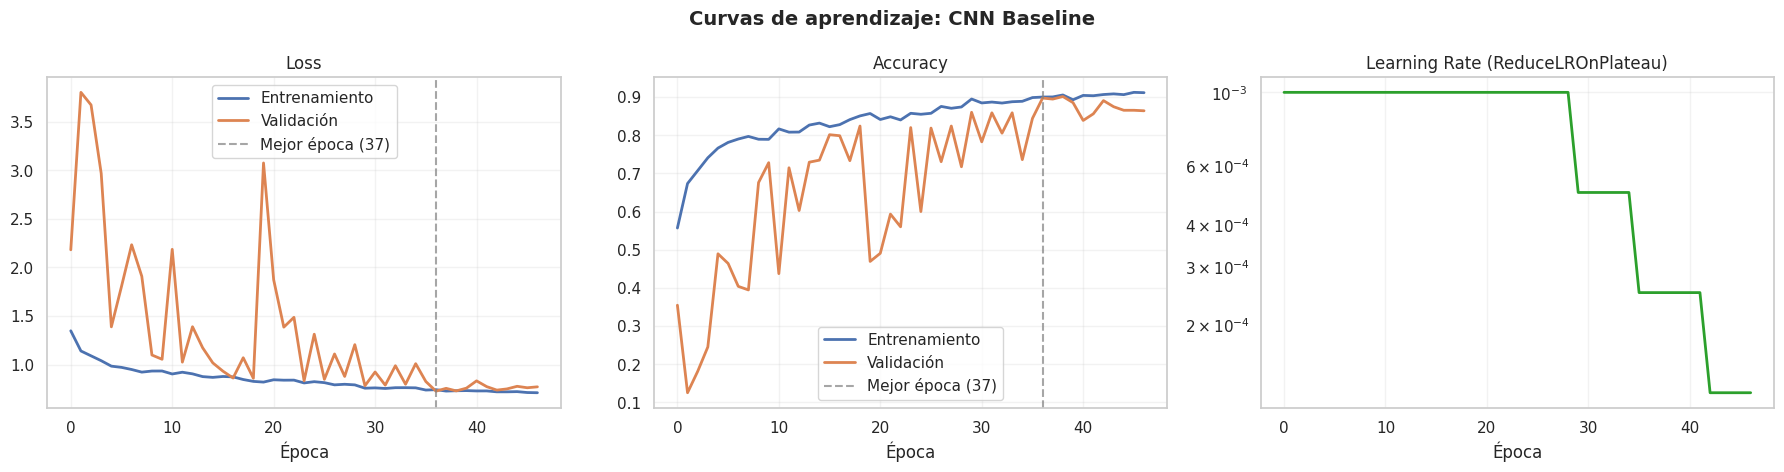

CNN Baseline    | mejor época 37 | train_acc=0.900 | val_acc=0.897 | brecha=+0.003  ->  ✅ Buen ajuste (brecha mínima y estable)



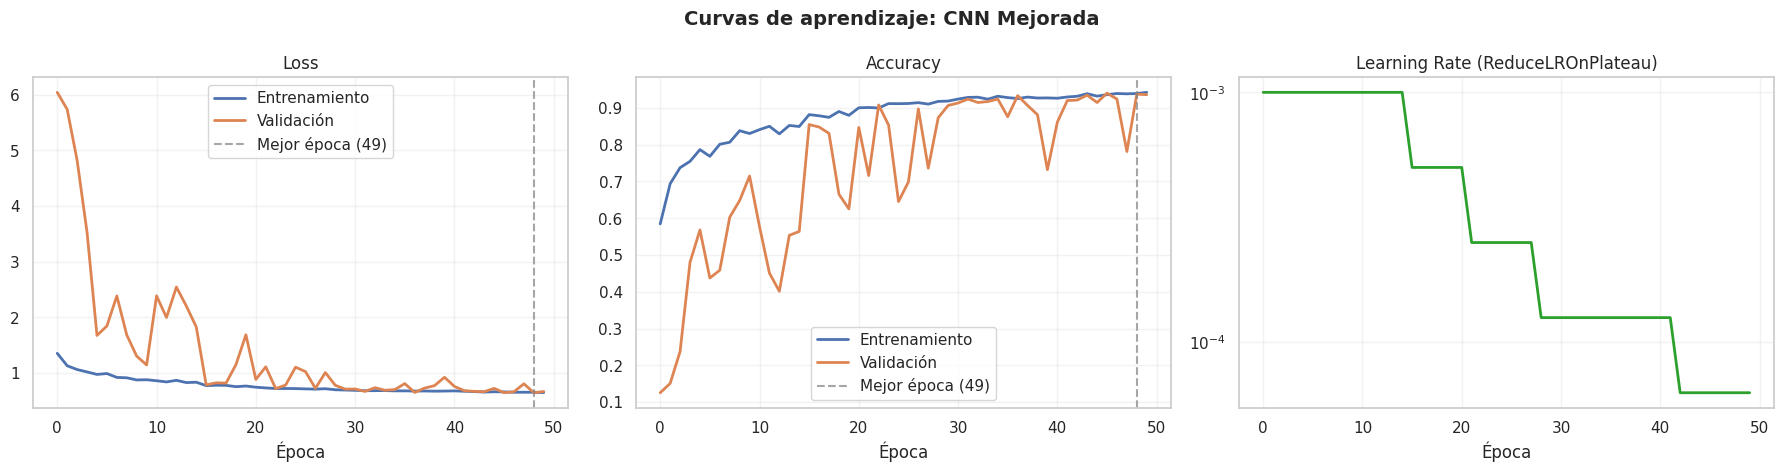

CNN Mejorada    | mejor época 49 | train_acc=0.939 | val_acc=0.937 | brecha=+0.002  ->  ✅ Buen ajuste (brecha mínima y estable)



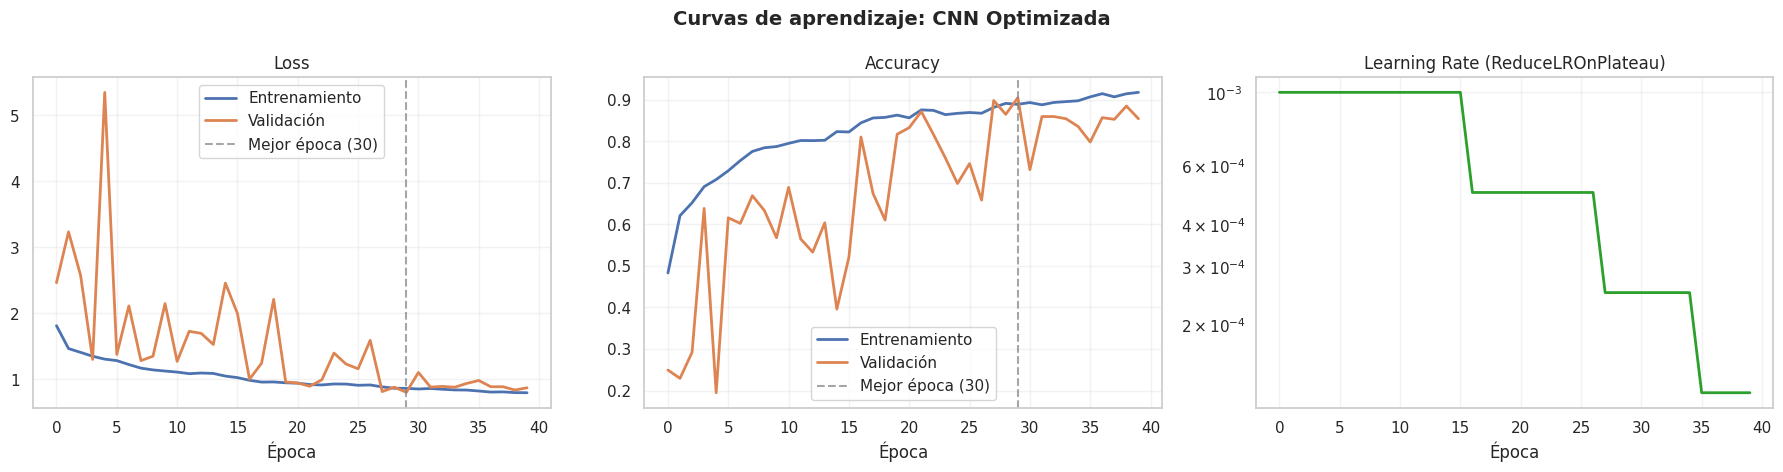

CNN Optimizada  | mejor época 30 | train_acc=0.889 | val_acc=0.905 | brecha=-0.016  ->  ✅ Buen ajuste (brecha mínima y estable)



In [27]:
def lr_key(history):
    for k in ('learning_rate', 'lr'):
        if k in history.history:
            return k
    return None

def plot_training_history(history, title="", save_name=None):
    h = history.history
    fig, axes = plt.subplots(1, 3, figsize=(18, 4.8))
    best = int(np.argmin(h['val_loss']))
    for ax, key, ttl in [(axes[0], 'loss', 'Loss'), (axes[1], 'accuracy', 'Accuracy')]:
        ax.plot(h[key], label='Entrenamiento', lw=2); ax.plot(h['val_' + key], label='Validación', lw=2)
        ax.axvline(best, color='gray', ls='--', alpha=.7, label=f'Mejor época ({best + 1})')
        ax.set_title(ttl); ax.set_xlabel('Época'); ax.legend()
    k = lr_key(history)
    if k:
        axes[2].plot(h[k], color='tab:green', lw=2); axes[2].set_yscale('log')
    axes[2].set_title('Learning Rate (ReduceLROnPlateau)'); axes[2].set_xlabel('Época')
    plt.suptitle(title, fontsize=14, fontweight='bold'); plt.tight_layout()
    if save_name: save_fig(save_name)
    else: plt.show()

def diagnose_fit(history):
    """Diagnóstico automático de la mejor época: overfitting / underfitting / buen ajuste."""
    h = history.history
    b = int(np.argmin(h['val_loss']))
    tr, va = h['accuracy'][b], h['val_accuracy'][b]
    gap = tr - va
    if va < 0.60 and tr < 0.60:
        dx = '⚠️ UNDERFITTING (el modelo no captura los patrones básicos)'
    elif gap > 0.08:
        dx = '⚠️ OVERFITTING (brecha train-val grande)'
    elif gap < -0.02:
        dx = '✅ Buen ajuste (train < val por el augmentation y el dropout activos solo en train)'
    else:
        dx = '✅ Buen ajuste (brecha mínima y estable)'
    return dict(best_epoch=b + 1, train_acc=tr, val_acc=va, gap=gap, diagnosis=dx)

for name, exp in EXPERIMENTS.items():
    plot_training_history(exp['history'], title=f"Curvas de aprendizaje: {name}",
                          save_name=f"curvas_{name.lower().replace(' ', '_')}")
    d = diagnose_fit(exp['history'])
    exp['diagnosis'] = d
    print(f"{name:<15} | mejor época {d['best_epoch']:>2} | train_acc={d['train_acc']:.3f} | "
          f"val_acc={d['val_acc']:.3f} | brecha={d['gap']:+.3f}  ->  {d['diagnosis']}\n")

---
## 📊 Fase 6: Suite de Evaluación Completa

### 6.1 Selección PREVIA a consultar el test

Los tres modelos se seleccionan por **Macro F1 de validación** entre los que cumplen simultáneamente las metas de tamaño y latencia. La latencia se medirá con lote de una imagen, **forzando CPU** sobre la máquina de Colab (no sobre un teléfono). Es una medida orientativa dependiente del hardware.

Si ninguno cumple las metas, se elegirá un **finalista académico** por Macro F1 de validación y se mostrará de manera explícita que **no está listo para el uso previsto**. No se cambiarán las metas mirando los resultados del test.

> La elección de la mejor época se realiza por `val_loss` (callbacks). La selección entre arquitecturas es por Macro F1 en validación. La evaluación en test es descriptiva y se hace después de fijar la elección.


In [28]:
def get_predictions(model, ds):
    """Etiquetas reales y probabilidades ordenadas (el dataset debe tener shuffle=False)."""
    probs = np.asarray(model.predict(ds, verbose=0))
    y_true = np.concatenate([np.argmax(y.numpy(), axis=1) for _, y in ds])
    assert len(y_true) == len(probs), 'Desalineación entre predicciones y etiquetas'
    return y_true, probs, np.argmax(probs, axis=1)

def macro_auc(y_true, probs):
    y_bin = label_binarize(y_true, classes=list(range(NUM_CLASSES)))
    return roc_auc_score(y_bin, probs, average='macro')

def save_lightweight(model, path):
    """Exportar una copia sin optimizador; el original y sus callbacks se preservan."""
    clone = tf.keras.models.clone_model(model)
    clone.set_weights(model.get_weights())
    clone.save(str(path))

def deploy_size_mb(model):
    tmp = EXP_DIR / '_tmp_size.keras'
    save_lightweight(model, tmp)
    mb = tmp.stat().st_size / 1024**2
    tmp.unlink()
    return mb

def measure_latency_cpu(model, n=15, warmup=3):
    """Latencia de inferencia de UN parche, forzando CPU de esta máquina, en ms.
    Las transferencias de pesos entre dispositivos pueden afectar la medición.
    No extrapolar automáticamente a teléfonos ni equipos clínicos.
    """
    x_np = (np.random.default_rng(SEED).random((1, *IMG_SIZE, 3)) * 255).astype('float32')
    with tf.device('/CPU:0'):
        x_cpu = tf.convert_to_tensor(x_np)
        for _ in range(warmup):
            _ = model(x_cpu, training=False).numpy()  # sincronización
        measurements = []
        for _ in range(n):
            t0 = time.perf_counter()
            _ = model(x_cpu, training=False).numpy()
            measurements.append((time.perf_counter() - t0) * 1000)
    return float(np.median(measurements))

VAL_RESULTS, TEST_RESULTS, PREDS = {}, {}, {}
for name, exp in EXPERIMENTS.items():
    m = exp['model']
    yt, pr, yp = get_predictions(m, val_ds)
    VAL_RESULTS[name] = {'acc': accuracy_score(yt, yp),
                         'f1': f1_score(yt, yp, average='macro', zero_division=0),
                         'auc': macro_auc(yt, pr)}
    exp['size_mb'] = deploy_size_mb(m)
    exp['latency_ms'] = measure_latency_cpu(m)

sel = pd.DataFrame([{
    'Modelo': n, 'Val Acc': VAL_RESULTS[n]['acc'], 'Val Macro F1': VAL_RESULTS[n]['f1'],
    'Val AUC': VAL_RESULTS[n]['auc'], 'Tamaño (MB)': e['size_mb'],
    'Latencia CPU Colab (ms/img)': e['latency_ms'],
    f'< {MAX_MODEL_MB} MB': e['size_mb'] < MAX_MODEL_MB,
    f'< {MAX_LATENCY_MS} ms': e['latency_ms'] < MAX_LATENCY_MS,
} for n, e in EXPERIMENTS.items()])
display(sel.style.hide(axis='index').format({
    'Val Acc': '{:.4f}', 'Val Macro F1': '{:.4f}', 'Val AUC': '{:.4f}',
    'Tamaño (MB)': '{:.2f}', 'Latencia CPU Colab (ms/img)': '{:.1f}'}))

eligibles = [n for n, e in EXPERIMENTS.items()
             if e['size_mb'] < MAX_MODEL_MB and e['latency_ms'] < MAX_LATENCY_MS]
FINAL_COMPLIANT = bool(eligibles)
if not eligibles:
    print('⚠️  Ninguna arquitectura satisface simultáneamente tamaño y latencia en CPU de Colab.')
    eligibles = [n for n, e in EXPERIMENTS.items() if e['size_mb'] < MAX_MODEL_MB]
    if not eligibles:
        print('⚠️  Tampoco se satisface el límite de tamaño: finalista solo experimental.')
        eligibles = list(EXPERIMENTS)
FINAL_NAME = max(eligibles, key=lambda n: VAL_RESULTS[n]['f1'])
final_model = EXPERIMENTS[FINAL_NAME]['model']
print(f'🏆 Modelo elegido SOLO con validación: {FINAL_NAME}')
print('Estado de las restricciones:', 'CUMPLE' if FINAL_COMPLIANT else 'NO CUMPLE (finalista académico)')


Modelo,Val Acc,Val Macro F1,Val AUC,Tamaño (MB),Latencia CPU Colab (ms/img),< 50 MB,< 100 ms
CNN Baseline,0.8973,0.8981,0.9920,1.55,33.5,True,True
CNN Mejorada,0.9373,0.9384,0.9947,15.00,110.4,True,False
CNN Optimizada,0.9053,0.9065,0.9916,28.35,74.0,True,True


🏆 Modelo elegido SOLO con validación: CNN Optimizada
Estado de las restricciones: CUMPLE


### 6.2 Evaluación sobre el test (tras fijar el modelo)

Se informa precision, recall, F1 por clase y resultados de las tres arquitecturas **solo para comparación descriptiva**. No se cambiará el finalista ni su arquitectura tras ver el test. La separación de test es por recorte, no por paciente (salvo que se haya aportado procedencia verificada).


In [29]:
# Modelos fijados antes de consultar el test. NO seleccionar después el de mejor Test F1.
for name, exp in EXPERIMENTS.items():
    yt, pr, yp = get_predictions(exp['model'], test_ds)
    PREDS[name] = (yt, pr, yp)
    TEST_RESULTS[name] = {'acc': accuracy_score(yt, yp), 'f1': f1_score(yt, yp, average='macro', zero_division=0), 'auc': macro_auc(yt, pr)}

y_true, y_pred_probs, y_pred = PREDS[FINAL_NAME]
print(f"Evaluación de «{FINAL_NAME}» sobre {len(y_true)} imágenes de TEST (nunca vistas)\n")
print(classification_report(y_true, y_pred, target_names=CLASS_LABELS, digits=4, zero_division=0))

# Comparación con el baseline aleatorio de la Fase 1
rng = np.random.default_rng(SEED)
rand_pred = rng.integers(0, NUM_CLASSES, size=len(y_true))
print(f"Baseline aleatorio -> accuracy={accuracy_score(y_true, rand_pred):.3f} | macro F1={f1_score(y_true, rand_pred, average='macro'):.3f}")
print(f"Nuestro modelo     -> accuracy={TEST_RESULTS[FINAL_NAME]['acc']:.3f} | macro F1={TEST_RESULTS[FINAL_NAME]['f1']:.3f} | macro AUC={TEST_RESULTS[FINAL_NAME]['auc']:.4f}")
meta_ok = TEST_RESULTS[FINAL_NAME]['f1'] >= TARGET_MACRO_F1
print(f"\n{'✅' if meta_ok else '⚠️'} Meta Macro F1 ≥ {TARGET_MACRO_F1:.2f}: {'CUMPLIDA' if meta_ok else 'no alcanzada (ver análisis de errores y estrategias de mejora)'}")

# Bootstrap por IMAGEN (no refleja correlación por lámina/paciente). Es un IC exploratorio.
boot = []
for _ in range(1000):
    idx = rng.integers(0, len(y_true), len(y_true))
    boot.append(f1_score(y_true[idx], y_pred[idx], average='macro', labels=list(range(NUM_CLASSES)), zero_division=0))
CI_F1 = (float(np.percentile(boot, 2.5)), float(np.percentile(boot, 97.5)))
print(f"Macro F1 en test = {TEST_RESULTS[FINAL_NAME]['f1']:.4f}  (IC 95% por bootstrap de recortes: {CI_F1[0]:.4f} – {CI_F1[1]:.4f})")
print('⚠️  El intervalo asume recortes independientes; puede subestimar la incertidumbre por correlación entre láminas.')


Evaluación de «CNN Optimizada» sobre 750 imágenes de TEST (nunca vistas)

              precision    recall  f1-score   support

     Adiposo     0.9670    0.9362    0.9514        94
    Complejo     0.8478    0.8387    0.8432        93
    Detritos     0.8800    0.9362    0.9072        94
 Fondo vacío     0.9583    0.9787    0.9684        94
  Linfocitos     0.9348    0.9149    0.9247        94
      Mucosa     0.9884    0.9043    0.9444        94
     Estroma     0.8660    0.8936    0.8796        94
       Tumor     0.9479    0.9785    0.9630        93

    accuracy                         0.9227       750
   macro avg     0.9238    0.9226    0.9227       750
weighted avg     0.9238    0.9227    0.9228       750

Baseline aleatorio -> accuracy=0.124 | macro F1=0.124
Nuestro modelo     -> accuracy=0.923 | macro F1=0.923 | macro AUC=0.9948

✅ Meta Macro F1 ≥ 0.90: CUMPLIDA
Macro F1 en test = 0.9227  (IC 95% por bootstrap de recortes: 0.9015 – 0.9405)
⚠️  El intervalo asume recortes ind

### 6.3 Matriz de confusión profesional

**¿Cómo leerla?** Las **filas** son la *realidad* y las **columnas** la *expectativa (predicción)* del modelo. La diagonal son los aciertos; todo lo que queda fuera de ella son **errores observados (no necesariamente sistemáticos)**. La versión en porcentaje normaliza por fila (recall por clase) y deja comparar clases aunque tengan distinto tamaño.


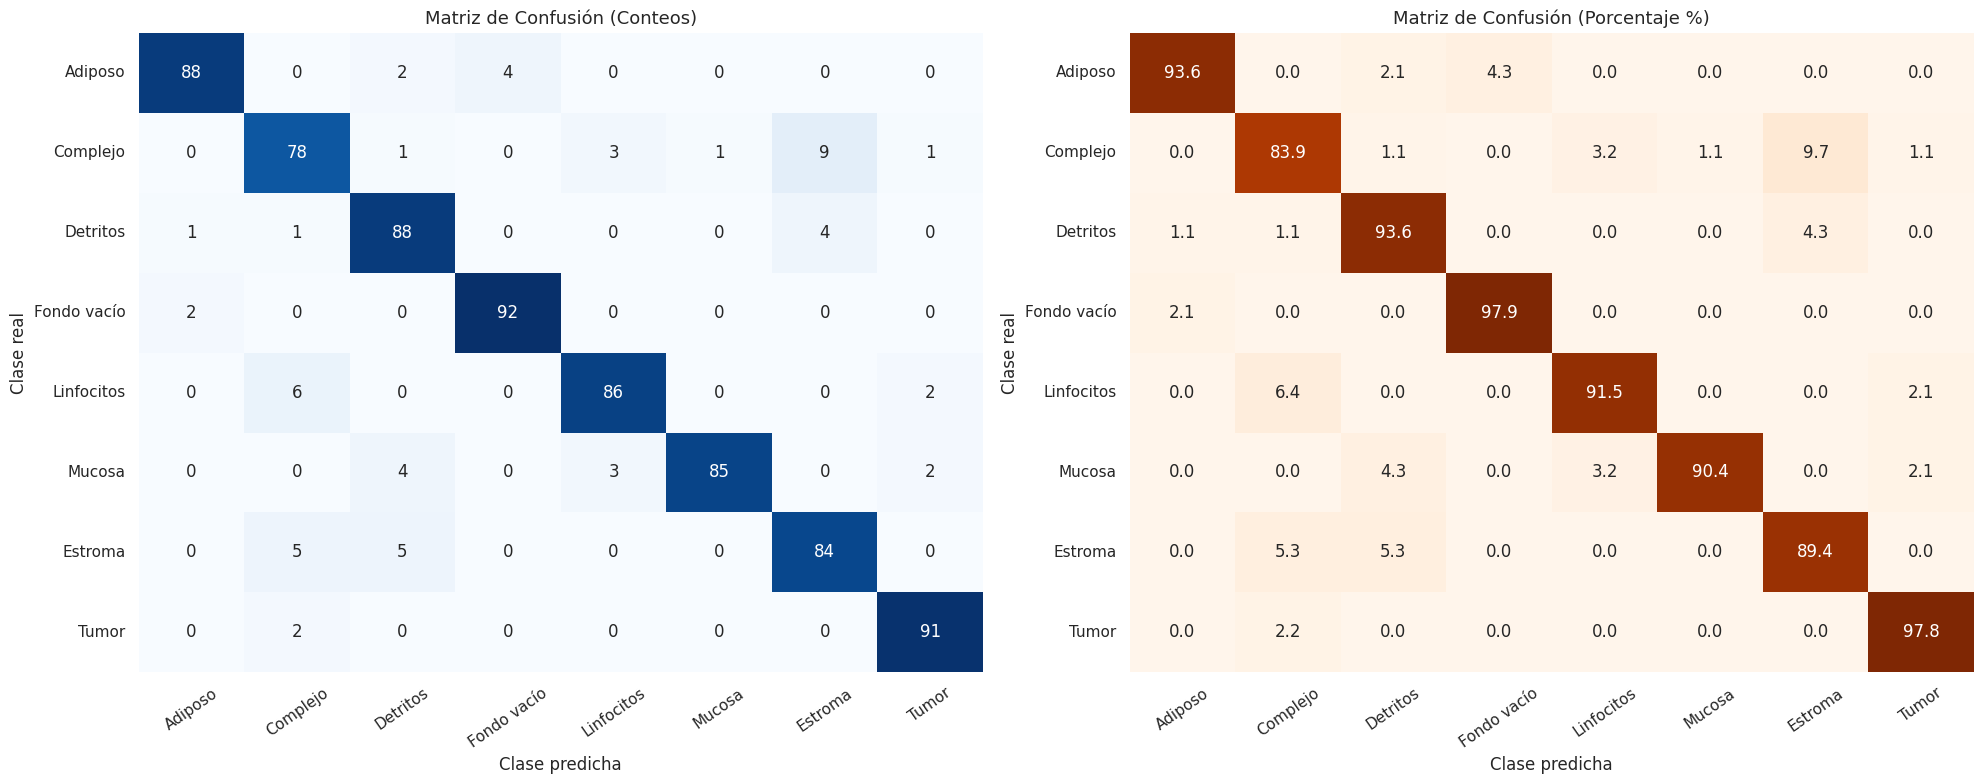

In [30]:
def plot_confusion_matrix(y_true, y_pred, labels, save_name=None):
    cm = confusion_matrix(y_true, y_pred, labels=range(len(labels)))
    cm_percent = cm.astype(float) / cm.sum(axis=1, keepdims=True) * 100
    fig, axes = plt.subplots(1, 2, figsize=(20, 8))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=labels, yticklabels=labels, ax=axes[0], cbar=False)
    axes[0].set_title('Matriz de Confusión (Conteos)', fontsize=13)
    sns.heatmap(cm_percent, annot=True, fmt='.1f', cmap='Oranges', xticklabels=labels, yticklabels=labels, ax=axes[1], cbar=False)
    axes[1].set_title('Matriz de Confusión (Porcentaje %)', fontsize=13)
    for ax in axes:
        ax.set_ylabel('Clase real'); ax.set_xlabel('Clase predicha')
        ax.tick_params(axis='x', rotation=35)
    plt.tight_layout()
    if save_name: save_fig(save_name)
    else: plt.show()
    return cm, cm_percent

cm, cm_percent = plot_confusion_matrix(y_true, y_pred, CLASS_LABELS, save_name='matriz_confusion')

### 6.4 Curvas ROC multiclase y Macro AUC

Enfoque **One-vs-Rest (OvR)**: evalúa la capacidad del modelo para distinguir *una clase específica contra todas las demás juntas*. Binarizamos las etiquetas y promediamos el AUC de las 8 clases (*macro*).

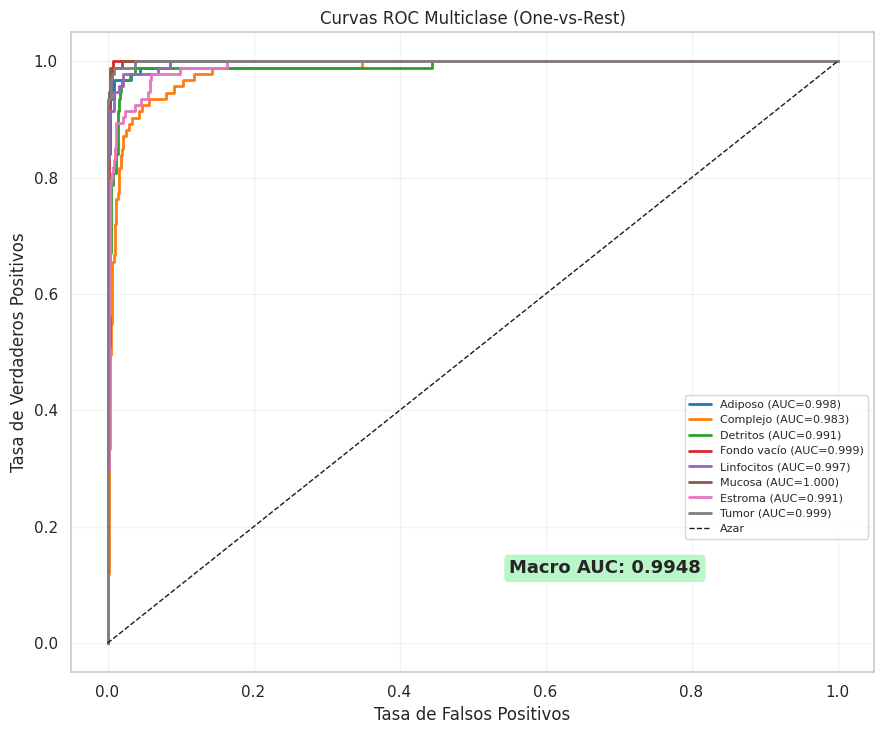

Macro AUC (OvR) = 0.9948


In [31]:
def plot_roc_curves(y_true, probs, labels, save_name=None):
    y_true_bin = label_binarize(y_true, classes=list(range(len(labels))))
    fig, ax = plt.subplots(figsize=(9, 7.5))
    colors = sns.color_palette('tab10', len(labels))
    for i, lab in enumerate(labels):
        fpr, tpr, _ = roc_curve(y_true_bin[:, i], probs[:, i])
        ax.plot(fpr, tpr, lw=2, color=colors[i], label=f'{lab} (AUC={auc(fpr, tpr):.3f})')
    ax.plot([0, 1], [0, 1], 'k--', lw=1, label='Azar')
    m_auc = roc_auc_score(y_true_bin, probs, multi_class='ovr', average='macro')
    ax.text(0.55, 0.12, f'Macro AUC: {m_auc:.4f}', fontsize=13, fontweight='bold',
            bbox=dict(boxstyle='round', facecolor='#b9f6ca'))
    ax.set_xlabel('Tasa de Falsos Positivos'); ax.set_ylabel('Tasa de Verdaderos Positivos')
    ax.set_title('Curvas ROC Multiclase (One-vs-Rest)'); ax.legend(loc='lower right', fontsize=8, bbox_to_anchor=(1.0, 0.2))
    plt.tight_layout()
    if save_name: save_fig(save_name)
    else: plt.show()
    return m_auc

# Cálculo del Macro AUC tal como en el slide (label_binarize + roc_auc_score OvR macro)
y_true_bin = label_binarize(y_true, classes=list(range(NUM_CLASSES)))
macro_auc_value = roc_auc_score(y_true_bin, y_pred_probs, multi_class='ovr', average='macro')
_ = plot_roc_curves(y_true, y_pred_probs, CLASS_LABELS, save_name='curvas_roc')
print(f"Macro AUC (OvR) = {macro_auc_value:.4f}")

---
## 🔬 Fase 7: Análisis de Errores: ¿Por Qué Falla?

> *El análisis de errores transforma un modelo aceptable en uno excelente.*

Un número global (por ejemplo, 93 % de accuracy) no dice **dónde** ni **por qué** falla el modelo. Aquí lo desarmamos en cuatro preguntas: ¿qué pares de clases se confunden?, ¿cómo se ven los errores?, ¿qué tan seguro estaba el modelo al equivocarse? y ¿hay algo en las imágenes (brillo, nitidez) que explique los fallos?

### 7.1 Top confusiones del modelo

Errores totales en test: 58 de 750 (7.73%)



Clase Real,Clase Predicha,Errores (Conteo),% de la Clase
Complejo,Estroma,9,9.7%
Linfocitos,Complejo,6,6.4%
Estroma,Complejo,5,5.3%
Estroma,Detritos,5,5.3%
Mucosa,Detritos,4,4.3%
Adiposo,Fondo vacío,4,4.3%
Detritos,Estroma,4,4.3%
Complejo,Linfocitos,3,3.2%
Mucosa,Linfocitos,3,3.2%
Fondo vacío,Adiposo,2,2.1%


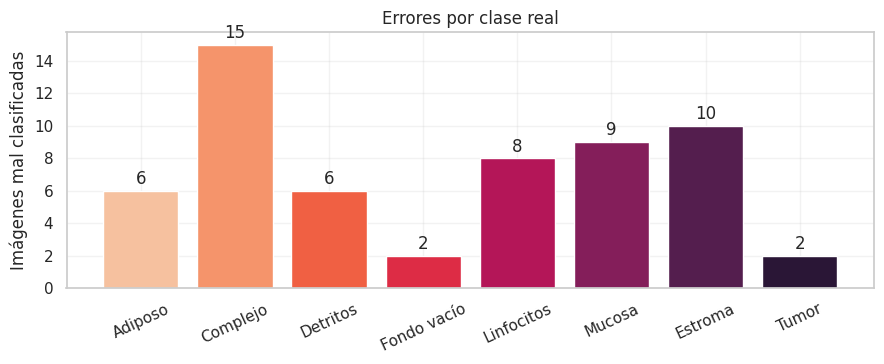

In [32]:
def top_confusions(cm, labels, k=10):
    cm_err = cm.copy()
    np.fill_diagonal(cm_err, 0)                       # Ignorar aciertos
    rows = [{'Clase Real': labels[i], 'Clase Predicha': labels[j],
             'Errores (Conteo)': int(cm_err[i, j]), '% de la Clase': cm_err[i, j] / cm[i].sum() * 100}
            for i in range(len(labels)) for j in range(len(labels)) if cm_err[i, j] > 0]
    cols = ['Clase Real', 'Clase Predicha', 'Errores (Conteo)', '% de la Clase']
    if not rows:
        return pd.DataFrame(columns=cols)
    return pd.DataFrame(rows).sort_values('Errores (Conteo)', ascending=False).head(k).reset_index(drop=True)

TOP_CONF = top_confusions(cm, CLASS_LABELS, k=10)
n_errors = int((y_true != y_pred).sum())
print(f"Errores totales en test: {n_errors} de {len(y_true)} ({n_errors/len(y_true):.2%})\n")
if len(TOP_CONF):
    display(TOP_CONF.style.hide(axis='index').format({'% de la Clase': '{:.1f}%'})
            .background_gradient(subset=['Errores (Conteo)'], cmap='Oranges'))
else:
    print("🎉 El modelo no cometió ningún error en test.")

# Errores por clase real (recall perdido)
err_by_class = pd.Series({lab: int(cm[i].sum() - cm[i, i]) for i, lab in enumerate(CLASS_LABELS)})
fig, ax = plt.subplots(figsize=(9, 3.8))
bars = ax.bar(err_by_class.index, err_by_class.values, color=sns.color_palette('rocket_r', len(err_by_class)))
ax.bar_label(bars, padding=2); ax.set_title('Errores por clase real'); ax.set_ylabel('Imágenes mal clasificadas')
plt.xticks(rotation=25); plt.tight_layout()
save_fig('errores_por_clase')

### 7.2 Visualización de errores: cero precisión, alta confianza

Los errores más peligrosos son los que el modelo comete **con mucha seguridad**. Mostramos las 12 imágenes mal clasificadas donde la confianza en la predicción incorrecta fue más alta. Esto revela limitaciones ocultas: tinción atípica, cortes ambiguos, o etiquetas dudosas.

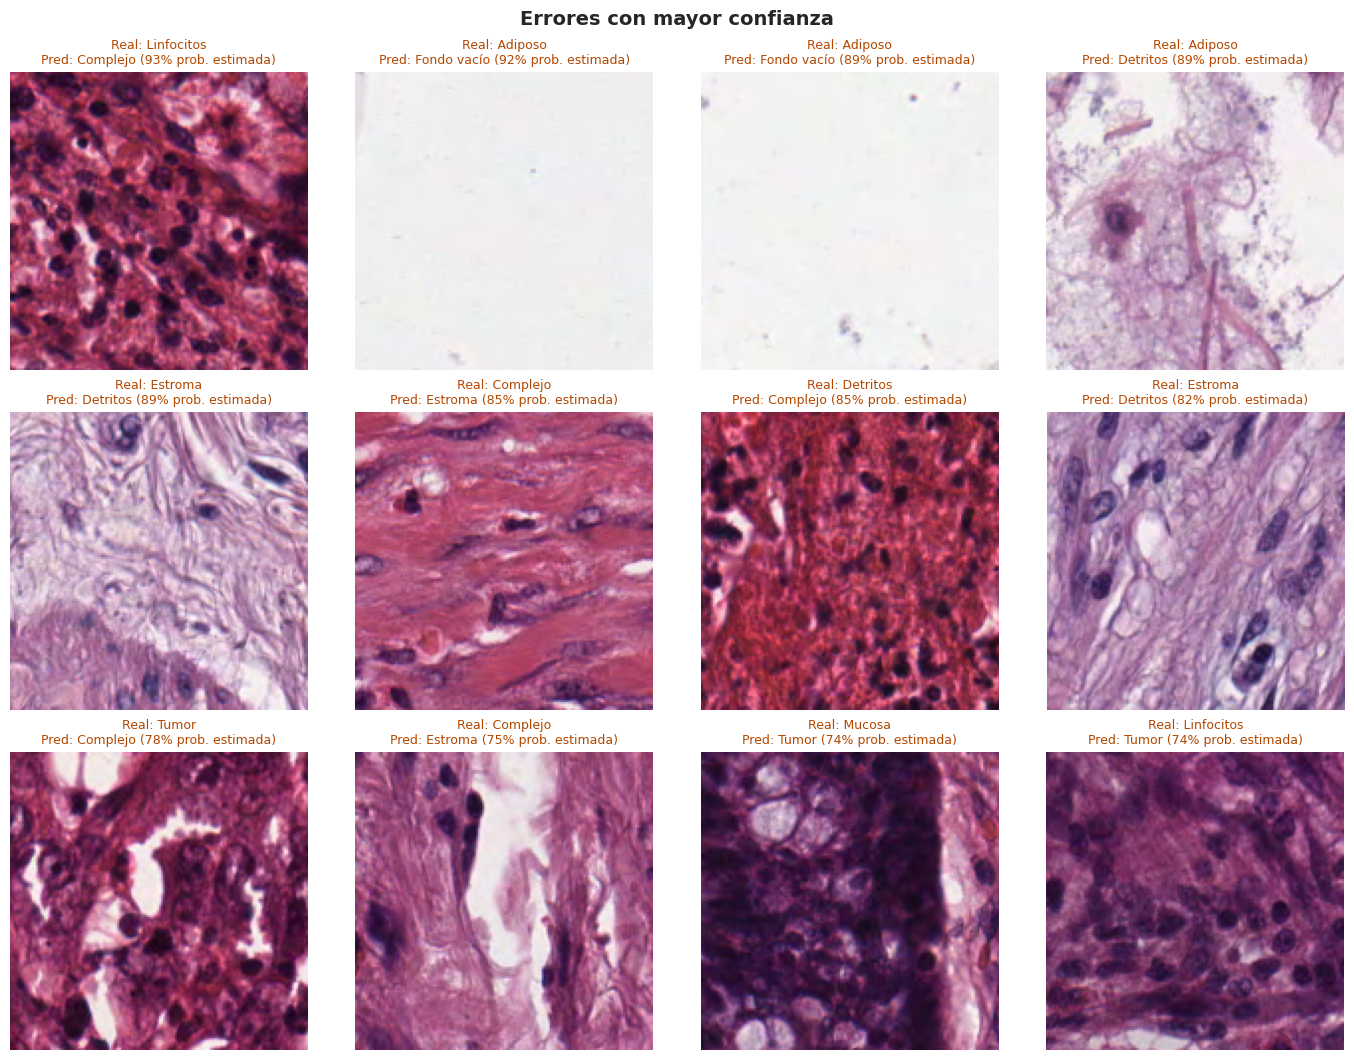

In [33]:
# Imágenes del test en el mismo orden que las predicciones (el test no baraja)
X_test = np.concatenate([x.numpy() for x, _ in test_ds]).astype('uint8')
assert len(X_test) == len(y_true)

wrong_idx = np.where(y_true != y_pred)[0]
confidences = y_pred_probs[wrong_idx, y_pred[wrong_idx]]
most_confident_errors = wrong_idx[np.argsort(-confidences)][:12]

if len(most_confident_errors):
    n = len(most_confident_errors)
    cols = 4; rows_ = int(np.ceil(n / cols))
    fig, axes = plt.subplots(rows_, cols, figsize=(14, 3.6 * rows_))
    for ax in np.atleast_1d(axes).ravel():
        ax.axis('off')
    for ax, idx in zip(np.atleast_1d(axes).ravel(), most_confident_errors):
        ax.imshow(X_test[idx])
        ax.set_title(f"Real: {CLASS_LABELS[y_true[idx]]}\nPred: {CLASS_LABELS[y_pred[idx]]} "
                     f"({y_pred_probs[idx, y_pred[idx]]:.0%} prob. estimada)", fontsize=9, color='#b34700')
    plt.suptitle('Errores con mayor confianza', fontsize=14, fontweight='bold'); plt.tight_layout()
    save_fig('errores_alta_confianza')
else:
    print("Sin errores que visualizar.")


### 7.3 ¿Qué tan seguro está el modelo cuando se equivoca?

Comparamos la confianza (probabilidad máxima) en aciertos y en errores, y medimos la **calibración** con el *Expected Calibration Error* (ECE). La confianza máxima no equivale automáticamente a probabilidad clínica. El ECE es una aproximación descriptiva dependiente del tamaño de los bins.


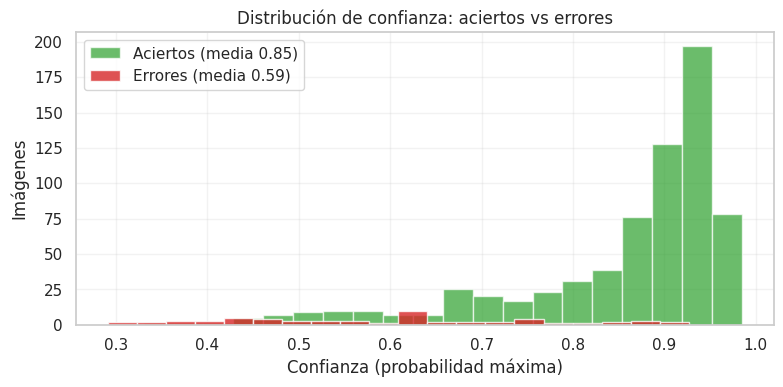

Confianza media en aciertos : 0.855
Confianza media en errores  : 0.590
Errores con confianza ≥ 80% : 13.8%
ECE (calibración)           : 0.0914   (0 = perfectamente calibrado)
Nota: label_smoothing puede moderar la confianza, pero NO garantiza buena calibración.


In [34]:
conf_all = y_pred_probs.max(axis=1)
correct = (y_true == y_pred)

def expected_calibration_error(conf, correct, n_bins=10):
    bins = np.linspace(0, 1, n_bins + 1); ece = 0.0
    for lo, hi in zip(bins[:-1], bins[1:]):
        m = (conf > lo) & (conf <= hi)
        if m.any():
            ece += m.mean() * abs(correct[m].mean() - conf[m].mean())
    return ece

ECE = expected_calibration_error(conf_all, correct)
conf_ok  = conf_all[correct].mean()
conf_bad = conf_all[~correct].mean() if (~correct).any() else float('nan')
share_conf_err = float((conf_all[~correct] >= 0.80).mean()) if (~correct).any() else 0.0

fig, ax = plt.subplots(figsize=(9, 3.8))
ax.hist(conf_all[correct], bins=20, alpha=.7, label=f'Aciertos (media {conf_ok:.2f})', color='tab:green')
if (~correct).any():
    ax.hist(conf_all[~correct], bins=20, alpha=.8, label=f'Errores (media {conf_bad:.2f})', color='tab:red')
ax.set_title('Distribución de confianza: aciertos vs errores'); ax.set_xlabel('Confianza (probabilidad máxima)')
ax.set_ylabel('Imágenes'); ax.legend()
save_fig('confianza_aciertos_errores')

print(f"Confianza media en aciertos : {conf_ok:.3f}")
print(f"Confianza media en errores  : {conf_bad:.3f}")
print(f"Errores con confianza ≥ 80% : {share_conf_err:.1%}")
print(f"ECE (calibración)           : {ECE:.4f}   (0 = perfectamente calibrado)")
print('Nota: label_smoothing puede moderar la confianza, pero NO garantiza buena calibración.')


### 7.4 ¿Los errores se relacionan con el brillo o la nitidez de la imagen?

El slide plantea la hipótesis *«errores en imágenes oscuras → sesgo de iluminación»*. La comprobamos con datos: dividimos el test en tres grupos de brillo (oscuras / medias / claras) y comparamos la tasa de error.

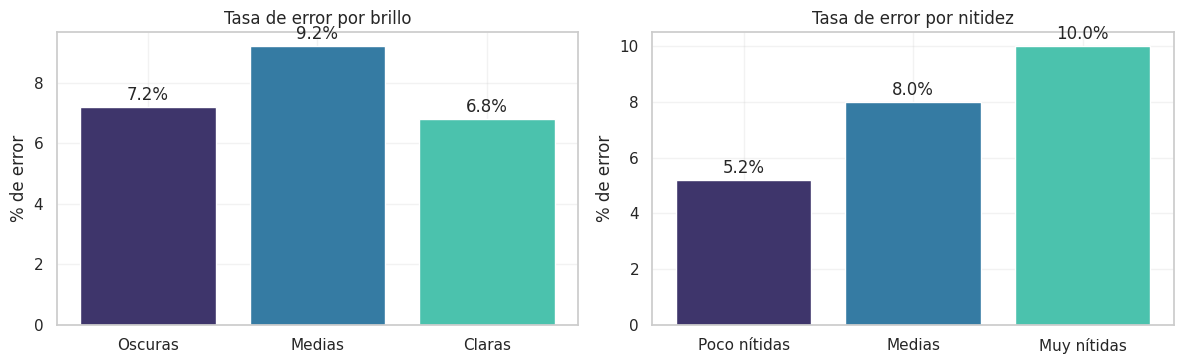

Brillo medio -> errores: 138.7 | aciertos: 145.0
ℹ️  No se observó una asociación clara bajo esta regla exploratoria; no prueba ausencia de sesgo.


In [35]:
gray = X_test.astype('float32').mean(axis=3)
test_brightness = gray.mean(axis=(1, 2))
test_sharp = np.array([laplacian_variance(g) for g in gray])

df_err = pd.DataFrame({'brillo': test_brightness, 'nitidez': test_sharp, 'error': ~correct})
try:
    df_err['grupo_brillo'] = pd.qcut(df_err['brillo'], 3, labels=['Oscuras', 'Medias', 'Claras'])
    df_err['grupo_nitidez'] = pd.qcut(df_err['nitidez'], 3, labels=['Poco nítidas', 'Medias', 'Muy nítidas'])
    tab_b = df_err.groupby('grupo_brillo', observed=True)['error'].agg(['mean', 'sum', 'count'])
    tab_s = df_err.groupby('grupo_nitidez', observed=True)['error'].agg(['mean', 'sum', 'count'])

    fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
    for ax, tab, ttl in [(axes[0], tab_b, 'Tasa de error por brillo'), (axes[1], tab_s, 'Tasa de error por nitidez')]:
        bars = ax.bar(tab.index.astype(str), tab['mean'] * 100, color=sns.color_palette('mako', 3))
        ax.bar_label(bars, fmt='%.1f%%', padding=2); ax.set_title(ttl); ax.set_ylabel('% de error')
    plt.tight_layout(); save_fig('errores_brillo_nitidez')
    sesgo_oscuras = tab_b.loc['Oscuras', 'mean'] > 1.5 * max(df_err['error'].mean(), 1e-9) and tab_b.loc['Oscuras', 'sum'] >= 3
except Exception as e:                                  # p. ej. si casi no hay errores
    print("No se pudo segmentar por brillo/nitidez:", e); sesgo_oscuras = False

print(f"Brillo medio -> errores: {test_brightness[~correct].mean() if (~correct).any() else float('nan'):.1f} | aciertos: {test_brightness[correct].mean():.1f}")
print("⚠️ Posible sesgo de iluminación detectado." if sesgo_oscuras else "ℹ️  No se observó una asociación clara bajo esta regla exploratoria; no prueba ausencia de sesgo.")


### 7.5 Estrategias de mejora post-análisis

Los hallazgos del test se utilizan para **describir errores y proponer investigación futura**, no para escoger retrospectivamente el modelo ni reajustarlo y volver a reportar el mismo test.

| Hallazgo posible | Hipótesis por comprobar | Acción sugerida |
|---|---|---|
| Dos clases se confunden | Texturas parecidas, tinción o etiquetado ambiguo | Revisar ejemplos con experto y reunir más datos independientes. **No fusionar categorías médicas para subir la métrica.** |
| Más errores en imágenes oscuras | La iluminación podría influir | Revisar ejemplos y estudiar variaciones de tinción en un nuevo experimento. |
| Baja precisión de una clase | Confusión con alguna categoría vecina | Revisar la matriz por clase; no aplicar automáticamente `class_weight` si el balance es correcto. |
| Alta confianza en fallos | Posible mala calibración | Evaluar calibración con validación adicional, no solo observar probabilidades. |


In [36]:
hallazgos = []
for _, r in TOP_CONF.head(3).iterrows():
    desc = (f"{r['Clase Real']} → {r['Clase Predicha']} "
            f"({int(r['Errores (Conteo)'])} errores; {r['% de la Clase']:.1f}% de la clase)")
    hallazgos.append([
        desc,
        'Posible solapamiento de textura/tinción o etiquetado; no demostrado por la matriz',
        'Revisar parches con un especialista y estudiar errores en muestras externas',
    ])
if share_conf_err >= 0.5:
    hallazgos.append([
        f'{share_conf_err:.0%} de los errores tienen predicción máxima ≥ 80%',
        'Posible descalibración; también podría reflejar muestras ambiguas',
        'Evaluar calibración en validación independiente; no usar test para ajustar umbrales',
    ])
if sesgo_oscuras:
    hallazgos.append([
        'Error descriptivamente elevado en imágenes oscuras',
        'Posible influencia de brillo, clase o procedencia; sin causalidad establecida',
        'Comprobar composición por clase y estudiar nuevas muestras de tinción distinta',
    ])
if not hallazgos:
    hallazgos.append(['No se identificaron errores destacables', 'Conjunto de test limitado',
                      'Validar con imágenes de otras láminas/laboratorios'])
TABLA_MEJORAS = pd.DataFrame(hallazgos,
                            columns=['Hallazgo observado', 'Hipótesis (no comprobada)', 'Próximo experimento propuesto'])
display(TABLA_MEJORAS.style.hide(axis='index').set_properties(**{
    'text-align': 'left', 'white-space': 'normal'}))


Hallazgo observado,Hipótesis (no comprobada),Próximo experimento propuesto
Complejo → Estroma (9 errores; 9.7% de la clase),Posible solapamiento de textura/tinción o etiquetado; no demostrado por la matriz,Revisar parches con un especialista y estudiar errores en muestras externas
Linfocitos → Complejo (6 errores; 6.4% de la clase),Posible solapamiento de textura/tinción o etiquetado; no demostrado por la matriz,Revisar parches con un especialista y estudiar errores en muestras externas
Estroma → Complejo (5 errores; 5.3% de la clase),Posible solapamiento de textura/tinción o etiquetado; no demostrado por la matriz,Revisar parches con un especialista y estudiar errores en muestras externas


### 7.6 Exploración opcional: TTA **SOLO en validación**

Se calculan ocho versiones geométricas plausibles del parche (cuatro rotaciones × espejo) y se promedian sus probabilidades. **Esta es una exploración sobre `val`, no sobre `test`**. No cambia el finalista ni las métricas oficiales de las Fases 6 y 8. Si el grupo decide utilizar TTA en un experimento futuro, debe fijar esa decisión ANTES de evaluar un nuevo test independiente.


In [37]:
def predict_tta(model, X, batch=64):
    """Promedio sobre las 8 simetrías diédricas (solo estudio en validación)."""
    total = None
    for k in range(4):
        for flip in (False, True):
            Xt = np.rot90(X, k, axes=(1, 2))
            if flip:
                Xt = Xt[:, :, ::-1, :]
            pr = model.predict(np.ascontiguousarray(Xt).astype('float32'),
                               batch_size=batch, verbose=0)
            total = pr if total is None else total + pr
    return total / 8

X_val = np.concatenate([x.numpy() for x, _ in val_ds]).astype('uint8')
y_val, val_probs, val_preds = get_predictions(final_model, val_ds)
probs_tta_val = predict_tta(final_model, X_val)
TTA_VAL = {'acc': accuracy_score(y_val, probs_tta_val.argmax(1)),
           'f1': f1_score(y_val, probs_tta_val.argmax(1), average='macro', zero_division=0)}
print(f"Validación sin TTA: Macro F1={VAL_RESULTS[FINAL_NAME]['f1']:.4f}")
print(f"Validación con TTA: Macro F1={TTA_VAL['f1']:.4f} "
      f"(Δ = {TTA_VAL['f1'] - VAL_RESULTS[FINAL_NAME]['f1']:+.4f})")
print('ℹ️  Resultado exploratorio: no modifica la elección ni se probará TTA en el test reservado.')


Validación sin TTA: Macro F1=0.9065
Validación con TTA: Macro F1=0.9080 (Δ = +0.0015)
ℹ️  Resultado exploratorio: no modifica la elección ni se probará TTA en el test reservado.


---
## ⚖️ Fase 8: Comparación Sistemática de Modelos

Con las tres arquitecturas entrenadas y evaluadas bajo las mismas condiciones (mismas particiones, misma semilla, misma configuración), las ponemos lado a lado: métricas de **validación** (las que sirvieron para elegir), métricas de **test** (solo descriptivas, jamás usadas para elegir), tamaño, latencia y costo de entrenamiento.


In [38]:
rows = []
for name, e in EXPERIMENTS.items():
    h = e['history'].history
    rows.append({
        'Modelo': name,
        'Parámetros (M)': e['model'].count_params() / 1e6,
        'Tamaño (MB)': e['size_mb'],
        'Latencia CPU Colab (ms/img)': e['latency_ms'],
        'Épocas': len(h['loss']),
        'Entrenamiento (min)': e['train_seconds'] / 60,
        'Val Acc': VAL_RESULTS[name]['acc'], 'Val F1': VAL_RESULTS[name]['f1'], 'Val AUC': VAL_RESULTS[name]['auc'],
        'Test Acc': TEST_RESULTS[name]['acc'], 'Test F1': TEST_RESULTS[name]['f1'], 'Test AUC': TEST_RESULTS[name]['auc'],
    })
COMPARISON = pd.DataFrame(rows)
COMPARISON.to_csv(EXP_DIR / 'comparacion_modelos.csv', index=False)
display(COMPARISON.style.hide(axis='index').format({
    'Parámetros (M)': '{:.2f}', 'Tamaño (MB)': '{:.2f}', 'Latencia CPU Colab (ms/img)': '{:.1f}', 'Entrenamiento (min)': '{:.1f}',
    'Val Acc': '{:.4f}', 'Val F1': '{:.4f}', 'Val AUC': '{:.4f}', 'Test Acc': '{:.4f}', 'Test F1': '{:.4f}', 'Test AUC': '{:.4f}'})
    .highlight_max(subset=['Val F1'], color='#c8e6c9'))


Modelo,Parámetros (M),Tamaño (MB),Latencia CPU Colab (ms/img),Épocas,Entrenamiento (min),Val Acc,Val F1,Val AUC,Test Acc,Test F1,Test AUC
CNN Baseline,0.13,1.55,33.5,47,19.3,0.8973,0.8981,0.9920,0.9107,0.9110,0.9948
CNN Mejorada,1.30,15.00,110.4,50,26.9,0.9373,0.9384,0.9947,0.9293,0.9301,0.9956
CNN Optimizada,2.46,28.35,74.0,40,6.0,0.9053,0.9065,0.9916,0.9227,0.9227,0.9948


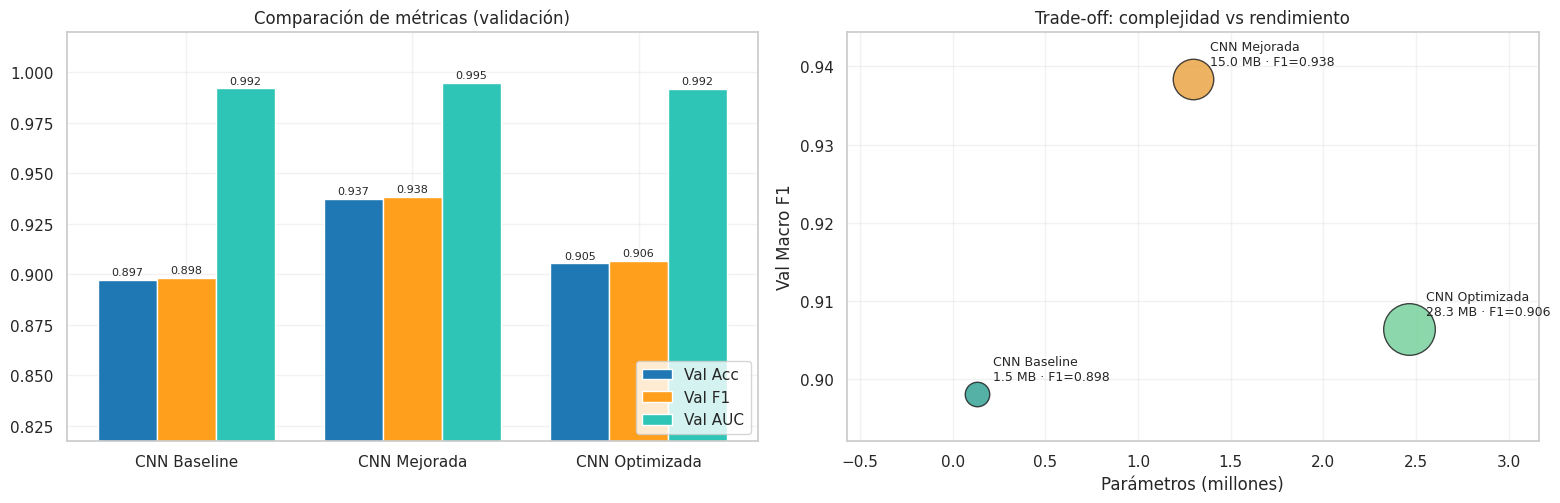

💡 TAKEAWAY
  • El mejor Val F1 es «CNN Mejorada» (0.9384); el más liviano es «CNN Baseline» (0.13 M de parámetros).
  • Pasar de «CNN Baseline» a «CNN Mejorada» cambia el F1 en +0.0403 usando 10.0× los parámetros.
  • Trade-off: un modelo más complejo no siempre es viable si el tiempo de inferencia y el tamaño superan las restricciones de producción.


KeyError: 'Latencia (ms/img)'

In [39]:
fig, axes = plt.subplots(1, 2, figsize=(16, 5.2))

# (a) Comparación de métricas de validación
metric_cols = ['Val Acc', 'Val F1', 'Val AUC']
x = np.arange(len(COMPARISON)); w = 0.26
for k, (col, color) in enumerate(zip(metric_cols, ['#1f77b4', '#ff9f1c', '#2ec4b6'])):
    b = axes[0].bar(x + (k - 1) * w, COMPARISON[col], w, label=col.replace('Val ', 'Val '), color=color)
    axes[0].bar_label(b, fmt='%.3f', fontsize=8, padding=2)
axes[0].set_xticks(x); axes[0].set_xticklabels(COMPARISON['Modelo'])
lo = max(0, COMPARISON[metric_cols].values.min() - 0.08)
axes[0].set_ylim(lo, 1.02); axes[0].set_title('Comparación de métricas (validación)'); axes[0].legend(loc='lower right')

# (b) Trade-off tamaño vs rendimiento
colors = ['#2a9d8f', '#e9a03b', '#6fcf97']
for (_, r), c in zip(COMPARISON.iterrows(), colors):
    axes[1].scatter(r['Parámetros (M)'], r['Val F1'], s=250 + r['Tamaño (MB)'] * 40, color=c, alpha=.8, edgecolor='k')
    axes[1].annotate(f"{r['Modelo']}\n{r['Tamaño (MB)']:.1f} MB · F1={r['Val F1']:.3f}",
                     (r['Parámetros (M)'], r['Val F1']), textcoords='offset points', xytext=(12, 10), fontsize=9)
axes[1].set_xlabel('Parámetros (millones)'); axes[1].set_ylabel('Val Macro F1')
axes[1].set_title('Trade-off: complejidad vs rendimiento')
axes[1].margins(x=0.3, y=0.15)
plt.tight_layout()
save_fig('comparacion_modelos')

best_f1 = COMPARISON.loc[COMPARISON['Val F1'].idxmax()]
smallest = COMPARISON.loc[COMPARISON['Parámetros (M)'].idxmin()]
print("💡 TAKEAWAY")
print(f"  • El mejor Val F1 es «{best_f1['Modelo']}» ({best_f1['Val F1']:.4f}); el más liviano es «{smallest['Modelo']}» ({smallest['Parámetros (M)']:.2f} M de parámetros).")
print(f"  • Pasar de «{smallest['Modelo']}» a «{best_f1['Modelo']}» cambia el F1 en {best_f1['Val F1'] - smallest['Val F1']:+.4f} usando {best_f1['Parámetros (M)'] / smallest['Parámetros (M)']:.1f}× los parámetros.")
print("  • Trade-off: un modelo más complejo no siempre es viable si el tiempo de inferencia y el tamaño superan las restricciones de producción.")
print(f"  • Todos cumplen < {MAX_MODEL_MB} MB: {all(COMPARISON['Tamaño (MB)'] < MAX_MODEL_MB)} | Todos cumplen < {MAX_LATENCY_MS} ms: {all(COMPARISON['Latencia (ms/img)'] < MAX_LATENCY_MS)}")
print(f"  • Modelo elegido para producción: «{FINAL_NAME}».")

### 8.1 Pregunta de producción: ¿y si el requisito fuera < 10 MB?

Una restricción más dura (por ejemplo, una app móvil liviana) cambiaría la decisión. Lo calculamos con las cifras reales, comparando el tamaño real `.keras` con una estimación inferior de tamaño por pesos float16 (no es el tamaño real del archivo TFLite, que se medirá en la Fase 12).


In [ ]:
LIMITE_MOVIL = 10
q = COMPARISON[['Modelo', 'Parámetros (M)', 'Tamaño (MB)', 'Val F1']].copy()
q['TFLite float16 TEÓRICO (MB)'] = q['Parámetros (M)'] * 1e6 * 2 / 1024**2
q[f'Cabe en {LIMITE_MOVIL} MB (.keras)'] = q['Tamaño (MB)'] < LIMITE_MOVIL
q[f'Cabe en {LIMITE_MOVIL} MB (float16)'] = q['TFLite float16 TEÓRICO (MB)'] < LIMITE_MOVIL
display(q.style.hide(axis='index').format({'Parámetros (M)': '{:.2f}', 'Tamaño (MB)': '{:.2f}', 'Val F1': '{:.4f}', 'TFLite float16 TEÓRICO (MB)': '{:.2f}'}))

cand = q[q[f'Cabe en {LIMITE_MOVIL} MB (float16)']]
if len(cand):
    pick = cand.loc[cand['Val F1'].idxmax()]
    print(f"\n👉 Con límite de {LIMITE_MOVIL} MB (cuantizado), el mejor candidato sería «{pick['Modelo']}» "
          f"(~{pick['TFLite float16 TEÓRICO (MB)']:.1f} MB, Val F1 = {pick['Val F1']:.4f}).")
else:
    print(f"\n👉 Ningún modelo cabe en {LIMITE_MOVIL} MB ni cuantizado; habría que reducir filtros o usar pruning.")


---
## 🗃️ Fase 9: Versionado del Proyecto (MLOps Básico)

**¿Por qué versionar?** Reproducibilidad, colaboración en equipo y capacidad de *rollback*.

> 🟡 **Regla de oro: ¡Git es para código, no para pesos!** Nunca se versionan carpetas de datos crudos ni modelos pesados; para eso se usan herramientas como **DVC**. Por eso nuestro `.gitignore` excluye `data/raw/`, `data/processed/`, `*.keras` y `*.h5`.

### 9.1 Estructura del proyecto

In [ ]:
def print_tree(root, prefix='', depth=0, max_depth=3, collapse=('raw', 'processed', 'tensorboard', 'figures', '.git', '__pycache__')):
    root = Path(root)
    entries = sorted(root.iterdir(), key=lambda p: (p.is_file(), p.name))
    for i, p in enumerate(entries):
        last = i == len(entries) - 1
        branch = '└── ' if last else '├── '
        if p.is_dir():
            if p.name in collapse:
                n = sum(1 for _ in p.rglob('*') if _.is_file())
                print(f"{prefix}{branch}📁 {p.name}/  ({n} archivos, no se versiona)" if p.name in ('raw', 'processed') else f"{prefix}{branch}📁 {p.name}/  ({n} archivos)")
            else:
                print(f"{prefix}{branch}📁 {p.name}/")
                if depth + 1 < max_depth:
                    print_tree(p, prefix + ('    ' if last else '│   '), depth + 1, max_depth, collapse)
        else:
            print(f"{prefix}{branch}{p.name}")

print(f"📦 {PROJECT_DIR.name}/")
print_tree(PROJECT_DIR, max_depth=3)

### 9.2 `.gitignore` y scripts reales, sin extracción inestable

Los módulos `src/models/architectures.py` y `src/training/train.py` se escriben a partir de versiones **explícitas y sincronizadas** del código del notebook. Se comprueban la sintaxis, la importación y un pequeño forward pass de la arquitectura exportada. Si falla algo, se detiene la ejecución: no se imprimirá un éxito falso.


In [ ]:
gitignore = """# Datos (se versionan con DVC, no con Git)
data/raw/
data/processed/
procedencia_laminas.csv

# Pesos de modelos
*.keras
*.h5
*.tflite
*.pb
*.onnx

# Auxiliares
experiments/*/tensorboard/
__pycache__/
.ipynb_checkpoints/
_tmp_saved_model/
*.zip
"""
(PROJECT_DIR / '.gitignore').write_text(gitignore, encoding='utf-8')
print(gitignore)

In [ ]:
# Exportación DETERMINISTA: el código fuente ya está incorporado al notebook.
# Evitamos inspect.getsource(), que no es fiable para celdas de Colab.
import py_compile
import importlib.util
ARCHITECTURES_SOURCE = "\"\"\"Arquitecturas reproducibles del proyecto Kather; exportadas desde el notebook corregido.\"\"\"\nimport tensorflow as tf\n\nAUG_CONFIG = {'rotation':0.25, 'zoom':0.10, 'brightness':0.10, 'contrast':0.10}\n\ndef build_augmentation(rotation=0.25, zoom=0.10, brightness=0.10, contrast=0.10):\n    \"\"\"Augmentation como bloque Sequential de capas nativas (solo actúa con training=True).\"\"\"\n    return tf.keras.Sequential([\n        tf.keras.layers.RandomFlip('horizontal_and_vertical'),\n        tf.keras.layers.RandomRotation(rotation, fill_mode='reflect'),\n        tf.keras.layers.RandomZoom(zoom, fill_mode='reflect'),\n        tf.keras.layers.RandomBrightness(brightness, value_range=(0, 255)),\n        tf.keras.layers.RandomContrast(contrast),\n    ], name='data_augmentation')\n\n\ndef build_baseline_model(input_shape, num_classes):\n    model = tf.keras.Sequential([\n        tf.keras.layers.Input(shape=input_shape),\n        tf.keras.layers.Rescaling(1. / 255),\n\n        # Bloque Conv repetido (32 -> 64 -> 128)\n        tf.keras.layers.Conv2D(32, (3, 3), padding='same'),\n        tf.keras.layers.BatchNormalization(),\n        tf.keras.layers.Activation('relu'),\n        tf.keras.layers.MaxPooling2D((2, 2)),\n\n        tf.keras.layers.Conv2D(64, (3, 3), padding='same'),\n        tf.keras.layers.BatchNormalization(),\n        tf.keras.layers.Activation('relu'),\n        tf.keras.layers.MaxPooling2D((2, 2)),\n\n        tf.keras.layers.Conv2D(128, (3, 3), padding='same'),\n        tf.keras.layers.BatchNormalization(),\n        tf.keras.layers.Activation('relu'),\n        tf.keras.layers.MaxPooling2D((2, 2)),\n\n        # Transición y Clasificador\n        tf.keras.layers.GlobalAveragePooling2D(),\n        tf.keras.layers.Dense(256, activation='relu'),\n        tf.keras.layers.Dropout(0.5),\n        tf.keras.layers.Dense(num_classes, activation='softmax'),\n    ], name='cnn_baseline')\n    return model\n\n\ndef residual_block(x, filters, stride=1, l2=0.0):\n    \"\"\"Bloque residual: dos convoluciones 3x3 + atajo (skip connection) sumado a la salida.\"\"\"\n    reg = tf.keras.regularizers.l2(l2) if l2 else None\n    shortcut = x\n\n    # Ruta principal\n    x = tf.keras.layers.Conv2D(filters, (3, 3), strides=stride, padding='same', use_bias=False, kernel_regularizer=reg)(x)\n    x = tf.keras.layers.BatchNormalization()(x)\n    x = tf.keras.layers.Activation('relu')(x)\n    x = tf.keras.layers.Conv2D(filters, (3, 3), padding='same', use_bias=False, kernel_regularizer=reg)(x)\n    x = tf.keras.layers.BatchNormalization()(x)\n\n    # Si cambian las dimensiones, el atajo se proyecta con una conv 1x1\n    if stride != 1 or shortcut.shape[-1] != filters:\n        shortcut = tf.keras.layers.Conv2D(filters, (1, 1), strides=stride, padding='same', use_bias=False, kernel_regularizer=reg)(shortcut)\n        shortcut = tf.keras.layers.BatchNormalization()(shortcut)\n\n    # SUMA (Skip Connection o Atajo)\n    x = tf.keras.layers.Add()([x, shortcut])\n    return tf.keras.layers.Activation('relu')(x)\n\n\ndef build_improved_model(input_shape, num_classes):\n    inputs = tf.keras.layers.Input(shape=input_shape)\n    x = tf.keras.layers.Rescaling(1. / 255)(inputs)\n    x = tf.keras.layers.Conv2D(32, (3, 3), padding='same', use_bias=False)(x)\n    x = tf.keras.layers.BatchNormalization()(x)\n    x = tf.keras.layers.Activation('relu')(x)\n    for filters, stride in [(32, 1), (64, 2), (128, 2), (256, 2)]:\n        x = residual_block(x, filters, stride)\n    x = tf.keras.layers.GlobalAveragePooling2D()(x)\n    x = tf.keras.layers.Dense(256, activation='relu')(x)\n    x = tf.keras.layers.Dropout(0.5)(x)\n    outputs = tf.keras.layers.Dense(num_classes, activation='softmax')(x)\n    return tf.keras.Model(inputs, outputs, name='cnn_mejorada')\n\n\ndef build_optimized_model(input_shape, num_classes, l2=1e-4, aug=True):\n    \"\"\"Augmentation integrado en el grafo + stem con stride agresivo + L2 en todo + Dropout escalonado.\n    aug=False crea una copia 'de inferencia' sin capas de augmentation (útil para exportar).\"\"\"\n    reg = tf.keras.regularizers.l2(l2)\n    inputs = tf.keras.layers.Input(shape=input_shape)\n    x = build_augmentation(**AUG_CONFIG)(inputs) if aug else inputs      # solo activo en training\n    x = tf.keras.layers.Rescaling(1. / 255)(x)\n\n    # Stem con stride agresivo: reduce rápido la memoria (150 -> 75 -> 38)\n    x = tf.keras.layers.Conv2D(32, (5, 5), strides=2, padding='same', use_bias=False, kernel_regularizer=reg)(x)\n    x = tf.keras.layers.BatchNormalization()(x)\n    x = tf.keras.layers.Activation('relu')(x)\n    x = tf.keras.layers.MaxPooling2D((3, 3), strides=2, padding='same')(x)\n\n    # Bloques residuales con L2 y Dropout espacial escalonado\n    x = residual_block(x, 64, 1, l2)\n    x = residual_block(x, 128, 2, l2)\n    x = tf.keras.layers.SpatialDropout2D(0.10)(x)\n    x = residual_block(x, 256, 2, l2)\n    x = tf.keras.layers.SpatialDropout2D(0.15)(x)\n    x = residual_block(x, 256, 1, l2)\n\n    # Cabeza clasificadora con Dropout escalonado (0.3 -> 0.5)\n    x = tf.keras.layers.GlobalAveragePooling2D()(x)\n    x = tf.keras.layers.Dropout(0.3)(x)\n    x = tf.keras.layers.Dense(256, activation='relu', kernel_regularizer=reg)(x)\n    x = tf.keras.layers.Dropout(0.5)(x)\n    outputs = tf.keras.layers.Dense(num_classes, activation='softmax', kernel_regularizer=reg)(x)\n    return tf.keras.Model(inputs, outputs, name='cnn_optimizada')\n"
TRAIN_SOURCE = "\"\"\"Entrenamiento y logging del proyecto Kather.\"\"\"\nimport json\nimport logging\nimport time\nfrom pathlib import Path\nimport numpy as np\nimport tensorflow as tf\n\nEXP_DIR = Path(__file__).resolve().parents[2] / 'experiments'\n\nclass ExperimentLogger(tf.keras.callbacks.Callback):\n    \"\"\"Callback propio (Fase 10): deja una huella persistente de cada época en experiment.log.\"\"\"\n    def __init__(self, log_file, name):\n        super().__init__()\n        self.logger = logging.getLogger(f\"experimento.{name}\")\n        self.logger.setLevel(logging.INFO)\n        self.logger.propagate = False\n        for h in list(self.logger.handlers):\n            self.logger.removeHandler(h)\n        fh = logging.FileHandler(log_file, mode='w', encoding='utf-8')\n        fh.setFormatter(logging.Formatter('[%(asctime)s] %(levelname)s: %(message)s'))\n        self.logger.addHandler(fh)\n        self.name = name\n\n    def on_train_begin(self, logs=None):\n        self.t0 = time.time()\n        self.logger.info(f\"Inicio del experimento '{self.name}' | parámetros={self.model.count_params():,}\")\n\n    def on_epoch_end(self, epoch, logs=None):\n        logs = logs or {}\n        lr_var = self.model.optimizer.learning_rate\n        lr = float(lr_var.numpy()) if hasattr(lr_var, 'numpy') else float(lr_var)\n        self.logger.info(\n            f\"Época {epoch + 1}: loss={logs.get('loss', float('nan')):.4f}, \"\n            f\"acc={logs.get('accuracy', float('nan')):.4f}, \"\n            f\"val_loss={logs.get('val_loss', float('nan')):.4f}, \"\n            f\"val_acc={logs.get('val_accuracy', float('nan')):.4f}, lr={lr:.2e}\")\n\n    def on_train_end(self, logs=None):\n        self.logger.info(f\"Fin del entrenamiento. Duración: {time.time() - self.t0:.1f} s\")\n        for h in list(self.logger.handlers):\n            h.flush()\n\n\ndef train_model(model, train_data, val_data, config, experiment_name):\n    \"\"\"Compila y entrena un modelo con la configuración centralizada y los callbacks profesionales.\"\"\"\n    exp_dir = EXP_DIR / experiment_name\n    (exp_dir / 'tensorboard').mkdir(parents=True, exist_ok=True)\n\n    with open(exp_dir / 'config.json', 'w', encoding='utf-8') as f:          # configuración versionada\n        json.dump(config, f, indent=2, default=str)\n\n    # Optimizador y Loss avanzados\n    optimizer = tf.keras.optimizers.Adam(learning_rate=config['learning_rate'],\n                                         weight_decay=config['weight_decay'])\n    loss_fn = tf.keras.losses.CategoricalCrossentropy(label_smoothing=config['label_smoothing'])\n\n    # Compilación con métricas robustas\n    model.compile(optimizer=optimizer, loss=loss_fn,\n                  metrics=['accuracy', tf.keras.metrics.AUC(multi_label=True, name='auc')])\n\n    callbacks = [\n        tf.keras.callbacks.ModelCheckpoint(str(exp_dir / 'best_model.keras'), monitor='val_loss',\n                                           mode='min', save_best_only=True, verbose=0),\n        tf.keras.callbacks.EarlyStopping(monitor='val_loss', patience=config['early_stopping_patience'],\n                                         restore_best_weights=True, verbose=1),\n        tf.keras.callbacks.ReduceLROnPlateau(monitor='val_loss', factor=config['reduce_lr_factor'],\n                                             patience=config['reduce_lr_patience'], min_lr=config['min_lr'], verbose=1),\n        tf.keras.callbacks.TensorBoard(log_dir=str(exp_dir / 'tensorboard')),\n        tf.keras.callbacks.CSVLogger(str(exp_dir / 'training_log.csv')),\n        ExperimentLogger(exp_dir / 'experiment.log', experiment_name),       # callback propio\n    ]\n\n    t0 = time.time()\n    history = model.fit(train_data, validation_data=val_data, epochs=config['epochs'],\n                        callbacks=callbacks, verbose=2)\n    train_seconds = time.time() - t0\n\n    # Garantizar que el modelo en memoria corresponde al mejor checkpoint según val_loss.\n    best = tf.keras.models.load_model(exp_dir / 'best_model.keras', compile=False)\n    model.set_weights(best.get_weights())\n    with open(exp_dir / 'model_summary.txt', 'w', encoding='utf-8') as f:\n        model.summary(print_fn=lambda s: f.write(s + '\\n'))\n    return history, exp_dir, train_seconds\n"
arch_path = SRC_DIR / 'models' / 'architectures.py'
train_path = SRC_DIR / 'training' / 'train.py'
arch_path.write_text(ARCHITECTURES_SOURCE, encoding='utf-8')
train_path.write_text(TRAIN_SOURCE, encoding='utf-8')
for p in [arch_path, train_path]:
    py_compile.compile(str(p), doraise=True)

# Importación real de los dos módulos exportados (no solo sintaxis).
def import_local_script(name, path):
    spec = importlib.util.spec_from_file_location(name, str(path))
    module = importlib.util.module_from_spec(spec)
    spec.loader.exec_module(module)
    return module

mod_arch = import_local_script('kather_architectures', arch_path)
mod_train = import_local_script('kather_training', train_path)
assert all(hasattr(mod_arch, fn) for fn in ('build_baseline_model', 'build_improved_model', 'build_optimized_model'))
assert all(hasattr(mod_train, fn) for fn in ('ExperimentLogger', 'train_model'))
# Construir una arquitectura exportada y verificar una predicción válida sin entrenamiento.
smoke = mod_arch.build_baseline_model(INPUT_SHAPE, NUM_CLASSES)
y_check = smoke(tf.zeros((1, *INPUT_SHAPE)), training=False).numpy()
assert y_check.shape == (1, NUM_CLASSES) and np.allclose(y_check.sum(), 1, atol=1e-4)
del smoke
SCRIPTS_IMPORT_OK = True
print('✅ architectures.py y train.py: sintaxis, importación y forward pass verificados.')


### 9.3 Modelo de producción y metadata (el «DNI» del experimento)

Guardamos el finalista académico (que puede incumplir alguna meta de despliegue) en `models/production/model_v1.keras`, junto con la lista de clases y un **JSON de metadata** con arquitectura, configuración, métricas, origen de los datos y versiones del entorno. El formato JSON da máxima interoperabilidad entre sistemas.


In [ ]:
# ---- 1. Guardar el modelo y verificar que la copia en disco reproduce exactamente las predicciones ----
prod_path = PROD_DIR / 'model_v1.keras'
save_lightweight(final_model, prod_path)      # sin estado del optimizador
loaded = tf.keras.models.load_model(prod_path)
_, probs_loaded, _ = get_predictions(loaded, val_ds)
assert np.allclose(probs_loaded, get_predictions(final_model, val_ds)[1], atol=1e-4), "El modelo guardado no reproduce las predicciones"
print(f"✅ Modelo guardado en {prod_path}  ({os.path.getsize(prod_path) / 1024**2:.2f} MB) y verificado contra predicciones de validación.")

# ---- 2. Clases para el despliegue ----
with open(PROD_DIR / 'class_names.json', 'w', encoding='utf-8') as f:
    json.dump({'class_names': class_names, 'labels_es': CLASS_LABELS}, f, ensure_ascii=False, indent=2)

# ---- 3. Metadata del modelo ----
fe = EXPERIMENTS[FINAL_NAME]
hist = fe['history'].history
metadata = {
    'version': '1.0',
    'status': 'prototipo academico; NO validado clinicamente',
    'meets_size_and_cpu_latency_targets': bool(FINAL_COMPLIANT),
    'cpu_latency_ms_per_image': float(EXPERIMENTS[FINAL_NAME]['latency_ms']),
    'timestamp': datetime.datetime.now().isoformat(timespec='seconds'),
    'model': {
        'architecture': FINAL_NAME,
        'total_params': int(final_model.count_params()),
        'input_shape': list(INPUT_SHAPE),
        'output_classes': NUM_CLASSES,
        'size_mb': round(os.path.getsize(prod_path) / 1024**2, 3),
    },
    'training': {
        'best_val_loss': float(min(hist['val_loss'])),
        'best_epoch': int(np.argmin(hist['val_loss']) + 1),
        'final_epoch': int(len(hist['loss'])),
        'checkpoint_monitor': 'val_loss',
        'model_selection_metric': 'macro_f1_validation',
        'training_minutes': round(fe['train_seconds'] / 60, 2),
        'config': CONFIG,
    },
    'metrics': {
        'val':  {k: float(v) for k, v in VAL_RESULTS[FINAL_NAME].items()},
        'test': {**{k: float(v) for k, v in TEST_RESULTS[FINAL_NAME].items()}, 'f1_ci95': [CI_F1[0], CI_F1[1]]},
    },
    'dataset': {
        'name': 'Kather-texture-2016',
        'source': HF_URL,
        'total_images': int(len(df_clean)),
        'splits': {'train': int(len(df_train)), 'val': int(len(df_val)), 'test': int(len(df_test))},
        'classes': class_names,
        'split_protocol': SPLIT_PROTOCOL,
        'patient_or_slide_independent': bool(SPLIT_BY_SLIDE),
        'manifest': 'data/processed/manifest_splits.csv',
    },
    'environment': {
        'tensorflow_version': tf.__version__,
        'python_version': platform.python_version(),
        'seed': SEED,
        'platform': platform.platform(),
    },
}
with open(PROD_DIR / 'metadata.json', 'w', encoding='utf-8') as f:
    json.dump(metadata, f, indent=2, ensure_ascii=False, default=str)
print(json.dumps({k: metadata[k] for k in ('model', 'dataset', 'environment')}, indent=2, ensure_ascii=False)[:1400])


### 9.4 Registro de experimentos y Git

Se registran configuraciones y métricas en CSV. Git versiona **código**, no datos ni pesos. El notebook intentará realizar commits solo cuando Git esté instalado y haya una identidad local configurada; **no inventará un correo institucional del grupo**. Un commit es evidencia real únicamente si `git log` muestra el hash creado.


In [ ]:
registro = pd.DataFrame([{
    'experimento': e['dir'].name, 'modelo': n, 'parametros': e['model'].count_params(),
    'epocas': len(e['history'].history['loss']), 'mejor_val_loss': min(e['history'].history['val_loss']),
    'val_acc': VAL_RESULTS[n]['acc'], 'val_f1': VAL_RESULTS[n]['f1'], 'val_auc': VAL_RESULTS[n]['auc'],
    'test_acc': TEST_RESULTS[n]['acc'], 'test_f1': TEST_RESULTS[n]['f1'], 'test_auc': TEST_RESULTS[n]['auc'],
    'minutos': round(e['train_seconds'] / 60, 2), 'elegido_validacion': n == FINAL_NAME,
} for n, e in EXPERIMENTS.items()])
registro.to_csv(EXP_DIR / 'registro_experimentos.csv', index=False)

def git(*args):
    return subprocess.run(['git', *args], cwd=PROJECT_DIR, capture_output=True, text=True)

def git_commit(message):
    if not shutil.which('git'):
        print('ℹ️  Git no está instalado; quedan archivos de código, pero no commits.')
        return False
    if not (PROJECT_DIR / '.git').exists():
        init = git('init', '-q')
        if init.returncode:
            print('⚠️  No se pudo inicializar Git:', init.stderr.strip()); return False
    has_name, has_email = git('config', 'user.name'), git('config', 'user.email')
    if has_name.returncode or has_email.returncode or not has_name.stdout.strip() or not has_email.stdout.strip():
        print('ℹ️  Git no tiene nombre/correo configurado; no se hará un commit ficticio.')
        print("   Configuren dentro de proyecto_cnn: git config user.name 'Nombre del grupo'")
        print("   y git config user.email 'correo_real_del_grupo@dominio.com'")
        return False
    add = git('add', '-A')
    if add.returncode:
        print('⚠️  Error en git add:', add.stderr.strip()); return False
    commit = git('commit', '-m', message)
    if commit.returncode:
        print('ℹ️  Commit no creado:', (commit.stderr or commit.stdout).strip()[:300]); return False
    head = git('rev-parse', '--short', 'HEAD')
    print('✅ Commit real:', head.stdout.strip(), message)
    return True

GIT_COMMIT_CREATED = git_commit('pipeline CNN Kather: experimentos y metadata')
if shutil.which('git') and (PROJECT_DIR / '.git').exists():
    print('Git log:', git('log', '--oneline', '-3').stdout.strip() or '(sin commits)')
    print('Archivos rastreados:', git('ls-files').stdout.strip()[:1000])


---
## 📒 Fase 10: Logging y Registro de Experimentos

> **No depender del output efímero de la consola.** Todo experimento debe dejar una **rastro persistente**. Los archivos de log por sí solos son editables; el hash facilita detectar cambios si se conserva por separado.

Cada entrenamiento dejó en su carpeta `experiments/<experimento>/`:

| Archivo | Quién lo genera | Para qué |
|---|---|---|
| `experiment.log` | `ExperimentLogger` (callback propio) | Bitácora con marca de tiempo por época |
| `training_log.csv` | `CSVLogger` | Métricas en texto plano, fáciles de analizar |
| `tensorboard/` | `TensorBoard` | Telemetría interactiva |
| `config.json` | `train_model` | Hiperparámetros exactos usados |
| `best_model.keras` | `ModelCheckpoint` | Mejor modelo de ese experimento |

### 10.1 La bitácora del experimento


In [ ]:
log_file = EXPERIMENTS[FINAL_NAME]['dir'] / 'experiment.log'
lines = log_file.read_text(encoding='utf-8').splitlines()
print(f"📄 {log_file}  ({len(lines)} líneas)\n")
print("\n".join(lines[:4]))
print("   ...")
print("\n".join(lines[-3:]))

### 10.2 Curvas reconstruidas **desde los archivos CSV**

Para demostrar que el registro es suficiente, comparamos los tres experimentos leyendo únicamente los `training_log.csv` guardados en disco, sin usar los objetos en memoria.

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(15, 4.6))
for (name, e), c in zip(EXPERIMENTS.items(), ['#2a9d8f', '#e9a03b', '#6c5ce7']):
    log = pd.read_csv(e['dir'] / 'training_log.csv')
    axes[0].plot(log['epoch'] + 1, log['val_loss'], lw=2, color=c, label=name)
    axes[1].plot(log['epoch'] + 1, log['val_accuracy'], lw=2, color=c, label=name)
axes[0].set_title('val_loss (desde CSVLogger)'); axes[1].set_title('val_accuracy (desde CSVLogger)')
for ax in axes: ax.set_xlabel('Época'); ax.legend()
plt.tight_layout()
save_fig('logs_csv_comparacion')

### 10.3 Integridad verificable mediante hashes: checksums y TensorBoard

Calculamos un **hash SHA-256** de los artefactos de cada experimento. Si alguien modifica un archivo después, el hash cambiará y se notará.


In [ ]:
def sha256_file(path, chunk=1 << 20):
    h = hashlib.sha256()
    with open(path, 'rb') as f:
        for block in iter(lambda: f.read(chunk), b''):
            h.update(block)
    return h.hexdigest()

for name, e in EXPERIMENTS.items():
    sums = {fn: sha256_file(e['dir'] / fn) for fn in ['best_model.keras', 'config.json', 'training_log.csv', 'experiment.log']}
    with open(e['dir'] / 'checksums.json', 'w') as f:
        json.dump(sums, f, indent=2)
    print(f"{name:<15} " + " | ".join(f"{k.split('.')[0]}: {v[:10]}…" for k, v in sums.items()))

In [ ]:
# TensorBoard embebido (funciona en Colab / Jupyter con la extensión cargada)
try:
    ip = get_ipython()
    ip.run_line_magic('load_ext', 'tensorboard')
    ip.run_line_magic('tensorboard', f'--logdir {EXP_DIR} --reload_interval 30')
except Exception as e:
    print(f"ℹ️ No se pudo incrustar TensorBoard aquí ({type(e).__name__}). Ejecuta en una terminal:  tensorboard --logdir {EXP_DIR}")

---
## 📝 Fase 11: Documentación Técnica

El entregable de documentación es un **`README.md`** de 7 secciones (slide *«Fase 11»*). La sección de **Reproducibilidad** es *el sello de oro de la ingeniería de software*: requiere `requirements.txt`, semillas fijadas e instrucciones claras de ejecución.

Lo generamos **por código con los valores reales** de esta ejecución, de modo que la documentación nunca contradice a los resultados.

In [ ]:
from importlib.metadata import version, PackageNotFoundError
def pkg_version(p):
    try: return version(p)
    except PackageNotFoundError: return None

pkgs = ['tensorflow', 'numpy', 'pandas', 'matplotlib', 'seaborn', 'scikit-learn', 'pillow', 'datasets', 'flask']
requirements = "\n".join(f"{p}=={pkg_version(p)}" for p in pkgs if pkg_version(p))
(PROJECT_DIR / 'requirements.txt').write_text(requirements + "\n", encoding='utf-8')
print("📦 requirements.txt\n" + requirements)

In [ ]:
tr, ve, te = VAL_RESULTS[FINAL_NAME], VAL_RESULTS[FINAL_NAME], TEST_RESULTS[FINAL_NAME]
met_tbl = "\n".join(
    f"| {n} | {EXPERIMENTS[n]['model'].count_params()/1e6:.2f} M | "
    f"{EXPERIMENTS[n]['size_mb']:.2f} MB | {VAL_RESULTS[n]['f1']:.4f} | "
    f"{TEST_RESULTS[n]['acc']:.4f} | {TEST_RESULTS[n]['f1']:.4f} | {TEST_RESULTS[n]['auc']:.4f} |"
    for n in EXPERIMENTS)
conf_txt = "\n".join(
    f"- {r['Clase Real']} → {r['Clase Predicha']}: {int(r['Errores (Conteo)'])} "
    f"errores ({r['% de la Clase']:.1f}% de la clase)" for _, r in TOP_CONF.head(3).iterrows())
if not conf_txt:
    conf_txt = '- No se registraron errores en el test de recortes.'
cumple = 'se alcanzó' if te['f1'] >= TARGET_MACRO_F1 else 'no se alcanzó'

README = f"""# Clasificación de tipos de tejido colorrectal con CNN

**Curso:** Ingeniería de Conocimientos · **Fecha del trabajo:** 11/11/2026 · **Universidad:** UNCP
**Equipo:** Bendezu Arana Joss Erick; Briceño Carrión Polmar Yacid; Morales Huaman Jhordan Aldair; Morales Valverde Antony Rodrigo.

## 1. Resumen ejecutivo
Sistema académico de **clasificación de parches histológicos** en {NUM_CLASSES} tipos de tejido.
Modelo seleccionado exclusivamente por validación: **{FINAL_NAME}**.
En un test **interno por recortes** obtuvo accuracy **{te['acc']:.4f}**, Macro F1 **{te['f1']:.4f}**, Macro AUC **{te['auc']:.4f}**.
La meta propuesta de Macro F1 ≥ {TARGET_MACRO_F1:.2f} {cumple} en este test. **No implica validez diagnóstica ni por paciente**.

## 2. Definición del problema
Clasificación multiclase de parches RGB {IMG_SIZE[0]}×{IMG_SIZE[1]} px, con softmax y entropía cruzada categórica.
Baseline aleatorio uniforme teórico: **{1/NUM_CLASSES:.1%} accuracy**. Objetivos propios del grupo: tamaño < {MAX_MODEL_MB} MB, latencia < {MAX_LATENCY_MS} ms/imagen en CPU **de Colab** y Macro F1 ≥ {TARGET_MACRO_F1:.2f}.
El modelo escogido {'cumple' if FINAL_COMPLIANT else 'NO cumple'} conjuntamente las metas de tamaño y latencia medidas aquí.

## 3. Dataset y limitaciones de procedencia
- **Fuente:** Kather-texture-2016, {HF_URL}, CC BY 4.0. Referencia: Kather et al., Scientific Reports 2016; doi:10.1038/srep27988.
- Imágenes originales: {len(df_meta)}; después de excluir corruptas ({n_corrupt}) y duplicadas exactas ({n_dup_extra}): {len(df_clean)}.
- División: train={len(df_train)}; val={len(df_val)}; test={len(df_test)}.
- Protocolo: **{SPLIT_PROTOCOL}**. Manifiesto en `data/processed/manifest_splits.csv`.
- Procedencia: el artículo original informa **10 muestras tumorales**. Si no se proporcionaron IDs fiables de lámina, **no podemos demostrar independencia por paciente**. Los hashes solo excluyen archivos idénticos, y la correlación entre recortes puede sobreestimar la generalización.

## 4. Metodología y arquitecturas
- `tf.data`, normalización 1/255 dentro del modelo y augmentation únicamente durante el entrenamiento.
- CNN Baseline: 3 bloques convolucionales. CNN Mejorada: conexiones residuales. CNN Optimizada: aumento integrado, L2 y Dropout.
- Adam con learning rate {CONFIG['learning_rate']}, weight decay {CONFIG['weight_decay']}, label smoothing {CONFIG['label_smoothing']}.
- Mejor época: `val_loss` mediante ModelCheckpoint/EarlyStopping. Mejor arquitectura: **Macro F1 en val**, con restricciones de tamaño/latencia previamente fijadas. Nada se seleccionó mediante test.

## 5. Resultados
| Modelo | Parámetros | Tamaño | Val Macro F1 | Test Acc | Test Macro F1 | Test Macro AUC |
|---|---|---|---|---|---|---|
{met_tbl}

**Finalista:** {FINAL_NAME}; test Macro F1 **{te['f1']:.4f}**; IC bootstrap por recortes 95% **[{CI_F1[0]:.4f}, {CI_F1[1]:.4f}]**. Este IC presupone recortes independientes y puede subestimar la incertidumbre por lámina.
Estudio exploratorio de TTA **solo en validación**: Val Macro F1 {TTA_VAL['f1']:.4f}; no se incorporó al sistema final.

**Confusiones observadas (hipótesis, no causas demostradas):**
{conf_txt}

## 6. Conclusiones y límites
- El notebook implementa los componentes de las 12 fases; su evidencia funcional figura en el checklist al final.
- El modelo **no diagnostica cáncer, no emite pronóstico ni reemplaza al patólogo**; clasifica el tipo de tejido de recortes.
- Las métricas se refieren a un test interno por recortes del mismo conjunto Kather, no necesariamente a pacientes externos.
- El tamaño de `.keras` y latencia CPU de Colab no equivalen a rendimiento en un móvil o laboratorio.
- Trabajo futuro: evaluación por lámina/paciente con IDs fiables, datos externos, calibración y despliegue monitorizado.

## 7. Reproducibilidad
- Semilla {SEED}; TensorFlow {tf.__version__}, Python {platform.python_version()}.
- Dependencias: `requirements.txt`; experimento: `experiments/`; pesos: `models/production/`.
- Abrir el notebook en Google Colab con GPU opcional y ejecutar secuencialmente; verificar el acceso al dataset de Hugging Face.
- Para la API local: `python src/deployment/app.py` y POST `/predict` con campo `file`; no es un despliegue público ni un producto médico.
- Los archivos de datos y pesos no se suben a Git; los commits solo existen si Git está correctamente configurado.
"""
(PROJECT_DIR / 'README.md').write_text(README, encoding='utf-8')
display(Markdown(README))


In [ ]:
git_commit("Documentación técnica: README (7 secciones) y requirements.txt")

---
## 🚀 Fase 12: Despliegue Básico

El docente solicita demostrar inferencia fuera del notebook. Probaremos una exportación Keras, una conversión TFLite y una API Flask **local**. Esto es un prototipo académico: **no es una herramienta médica certificada ni un servicio desplegado en la nube**.

### 12.1 Verificar las metas propuestas por el grupo
La latencia se mide sobre CPU de Colab, no sobre el dispositivo del usuario. Si incumple una meta, se declara y se conserva la exportación como demostración académica.


In [ ]:
prod_model = tf.keras.models.load_model(PROD_DIR / 'model_v1.keras')
size_prod = os.path.getsize(PROD_DIR / 'model_v1.keras') / 1024**2
lat_prod = measure_latency_cpu(prod_model)
_, probs_prod, pred_prod = get_predictions(prod_model, test_ds)
f1_prod = f1_score(y_true, pred_prod, average='macro')

restr = pd.DataFrame([
    [f'Tamaño < {MAX_MODEL_MB} MB', f'{size_prod:.2f} MB', size_prod < MAX_MODEL_MB],
    [f'Latencia CPU Colab < {MAX_LATENCY_MS} ms/imagen', f'{lat_prod:.1f} ms', lat_prod < MAX_LATENCY_MS],
    [f'Macro F1 en test ≥ {TARGET_MACRO_F1:.2f}', f'{f1_prod:.4f}', f1_prod >= TARGET_MACRO_F1],
], columns=['Restricción / meta (Fase 1)', 'Medido', 'Cumple'])
restr['Cumple'] = restr['Cumple'].map({True: '✅ Sí', False: '⚠️ No'})
display(restr.style.hide(axis='index'))


### 12.2 Conversión a TFLite (cuantización float16)

Si el finalista es la **CNN Optimizada**, el augmentation vive dentro del grafo. Para exportar creamos una copia **solo de inferencia** (sin capas aleatorias) y le copiamos los pesos entrenados; verificamos que ambas den resultados idénticos. Después convertimos con `Optimize.DEFAULT` + `float16` y comprobamos que las predicciones del modelo móvil coinciden con las del original.

In [ ]:
def make_inference_model(model, name):
    """Para la CNN optimizada, replica capas con pesos sin el augmentation aleatorio."""
    if name != 'CNN Optimizada':
        return model
    twin = build_optimized_model(INPUT_SHAPE, NUM_CLASSES,
                                 l2=CONFIG['l2_layers'], aug=False)
    src_layers = [l for l in model.layers if l.weights and not l.name.startswith('data_augmentation')]
    dst_layers = [l for l in twin.layers if l.weights]
    assert len(src_layers)==len(dst_layers), 'No coinciden las capas entrenables'
    for src_layer, dst_layer in zip(src_layers,dst_layers):
        sw, dw = src_layer.get_weights(), dst_layer.get_weights()
        assert len(sw)==len(dw) and all(a.shape==b.shape for a,b in zip(sw,dw)), (
            f'Incompatibilidad de pesos: {src_layer.name} → {dst_layer.name}')
        dst_layer.set_weights(sw)
    return twin

def convert_to_tflite(model, output_path):
    """Primero Keras, si falla la conversión se utiliza SavedModel como alternativa."""
    def configure(converter):
        converter.optimizations = [tf.lite.Optimize.DEFAULT]
        converter.target_spec.supported_types = [tf.float16]
        return converter
    try:
        bytes_model = configure(tf.lite.TFLiteConverter.from_keras_model(model)).convert()
    except Exception as e:
        print(f'ℹ️  Conversión directa desde Keras falló ({type(e).__name__}). Probando SavedModel...')
        tmp = PROJECT_DIR / '_tmp_saved_model'
        shutil.rmtree(tmp, ignore_errors=True)
        model.export(str(tmp))
        bytes_model = configure(tf.lite.TFLiteConverter.from_saved_model(str(tmp))).convert()
        shutil.rmtree(tmp, ignore_errors=True)
    Path(output_path).write_bytes(bytes_model)
    assert Path(output_path).stat().st_size > 0, 'TFLite exportado vacío'
    return bytes_model

infer_model = make_inference_model(prod_model, FINAL_NAME)
check = np.abs(infer_model(X_test[:16].astype('float32'), training=False).numpy() -
               prod_model(X_test[:16].astype('float32'), training=False).numpy()).max()
assert check < 1e-4, f'El modelo de inferencia difiere del original (Δmax={check})'
print(f'✅ Modelo de inferencia coincide con el guardado (diferencia máxima {check:.2e}).')

tflite_path = PROD_DIR / 'model_v1_float16.tflite'
convert_to_tflite(infer_model, tflite_path)
size_tfl = tflite_path.stat().st_size / 1024**2
print(f'Keras: {size_prod:.2f} MB → TFLite float16: {size_tfl:.2f} MB')


In [ ]:
# Verificación: el modelo TFLite debe coincidir con el modelo Keras
interp = tf.lite.Interpreter(model_path=str(tflite_path))
interp.allocate_tensors()
inp, out = interp.get_input_details()[0], interp.get_output_details()[0]

idx = np.linspace(0, len(X_test) - 1, min(200, len(X_test))).astype(int)       # muestra repartida entre todas las clases
tfl_pred, t0 = [], time.perf_counter()
for i in idx:
    interp.set_tensor(inp['index'], X_test[i:i + 1].astype(inp['dtype']))
    interp.invoke()
    tfl_pred.append(int(np.argmax(interp.get_tensor(out['index'])[0])))
tfl_ms = (time.perf_counter() - t0) / len(idx) * 1000  # Interpreter usa CPU por defecto; promedio incluye set/get
tfl_pred = np.array(tfl_pred)

agree = float((tfl_pred == pred_prod[idx]).mean())
tfl_acc = float((tfl_pred == y_true[idx]).mean())
print(f"Imágenes comparadas       : {len(idx)}")
print(f"Coincidencia TFLite/Keras : {agree:.1%}")
print(f"Accuracy TFLite (muestra) : {tfl_acc:.1%}  | Keras (misma muestra): {(pred_prod[idx] == y_true[idx]).mean():.1%}")
print(f'Latencia TFLite en CPU Colab (promedio, muestra): {tfl_ms:.1f} ms/imagen')
print(f"{'✅' if size_tfl < 10 else 'ℹ️'} Tamaño TFLite {size_tfl:.2f} MB ({'entra' if size_tfl < 10 else 'no entra'} en un límite móvil de 10 MB)")
TFLITE_INFO = {'size_mb': size_tfl, 'agreement': agree, 'latency_ms': tfl_ms}


### 12.3 Script de predicción y API Flask

Escribimos dos scripts independientes en `src/deployment/`:

- **`predict.py`**: carga el modelo y predice una imagen (también se usa por línea de comandos).
- **`app.py`**: API Flask con `GET /health` y `POST /predict` (recibe la imagen en el campo `file`).

Los modelos reciben píxeles 0–255 (el reescalado está dentro del modelo), por lo que el despliegue solo tiene que redimensionar si hace falta.

In [ ]:
predict_py = '''# Predice el tipo de tejido de una imagen histologica con el modelo de produccion.
# Uso:  python src/deployment/predict.py ruta/imagen.png
import argparse, json
from pathlib import Path

import numpy as np
from PIL import Image
import tensorflow as tf

BASE = Path(__file__).resolve().parents[2]
MODEL_PATH = BASE / "models" / "production" / "model_v1.keras"
META_PATH = BASE / "models" / "production" / "class_names.json"
IMG_SIZE = (150, 150)

_MODEL = None


def load_model():
    global _MODEL
    if _MODEL is None:
        _MODEL = tf.keras.models.load_model(MODEL_PATH)
    return _MODEL


def preprocess(image):
    # PIL.Image -> arreglo (1, 150, 150, 3) en escala 0-255 (el modelo reescala internamente)
    img = image.convert("RGB")
    if img.size != IMG_SIZE:
        img = img.resize(IMG_SIZE, Image.BILINEAR)
    return np.expand_dims(np.asarray(img, dtype="float32"), axis=0)


def predict_image(image, top_k=3):
    # image: ruta (str/Path) o PIL.Image. Devuelve un diccionario con la clase y la confianza
    if not isinstance(image, Image.Image):
        image = Image.open(image)
    meta = json.loads(META_PATH.read_text(encoding="utf-8"))
    probs = load_model().predict(preprocess(image), verbose=0)[0]
    order = np.argsort(probs)[::-1][:top_k]
    return {
        "class": meta["class_names"][int(order[0])],
        "label": meta["labels_es"][int(order[0])],
        "confidence": float(probs[order[0]]),
        "top": [{"label": meta["labels_es"][int(i)], "confidence": float(probs[i])} for i in order],
    }


if __name__ == "__main__":
    parser = argparse.ArgumentParser(description="Clasifica una imagen histologica")
    parser.add_argument("image", help="ruta de la imagen")
    args = parser.parse_args()
    print(json.dumps(predict_image(args.image), indent=2, ensure_ascii=False))
'''

app_py = '''# API Flask del clasificador de tejidos histologicos.
# Uso:  python src/deployment/app.py   ->   POST http://localhost:5000/predict  (campo 'file')
import sys
from pathlib import Path

from flask import Flask, jsonify, request
from PIL import Image

sys.path.insert(0, str(Path(__file__).resolve().parent))
from predict import load_model, predict_image

app = Flask(__name__)
app.json.ensure_ascii = False
app.config["MAX_CONTENT_LENGTH"] = 8 * 1024 * 1024   # límite de 8 MB por solicitud
MODEL = load_model()          # se carga una sola vez al iniciar el servicio


@app.route("/health", methods=["GET"])
def health():
    return jsonify({"status": "ok", "model": "model_v1.keras"})


@app.route("/predict", methods=["POST"])
def predict():
    if "file" not in request.files:
        return jsonify({"error": "Envia la imagen en el campo 'file'"}), 400
    try:
        img = Image.open(request.files["file"].stream)
        img.load()
    except Exception:
        return jsonify({"error": "El archivo no es una imagen valida"}), 400
    return jsonify(predict_image(img))


if __name__ == "__main__":
    app.run(host="127.0.0.1", port=5000)  # demostración local, no servidor público
'''

(SRC_DIR / 'deployment' / 'predict.py').write_text(predict_py, encoding='utf-8')
(SRC_DIR / 'deployment' / 'app.py').write_text(app_py, encoding='utf-8')
for fn in ['predict.py', 'app.py']:
    py_compile.compile(str(SRC_DIR / 'deployment' / fn), doraise=True)
print("✅ src/deployment/predict.py y src/deployment/app.py creados (sintaxis válida)")

In [ ]:
# ---- Probar el script de predicción real sobre 4 imágenes del test (de clases distintas) ----
spec = importlib.util.spec_from_file_location('predict_mod', SRC_DIR / 'deployment' / 'predict.py')
predict_mod = importlib.util.module_from_spec(spec); spec.loader.exec_module(predict_mod)

demo_idx = [int(np.where(y_true == c)[0][0]) for c in range(0, NUM_CLASSES, max(1, NUM_CLASSES // 4))][:4]
fig, axes = plt.subplots(1, len(demo_idx), figsize=(4 * len(demo_idx), 4.6))
for ax, i in zip(np.atleast_1d(axes), demo_idx):
    res = predict_mod.predict_image(Image.fromarray(X_test[i]))
    ok_ = res['label'] == CLASS_LABELS[y_true[i]]
    ax.imshow(X_test[i]); ax.axis('off')
    ax.set_title(f"Real: {CLASS_LABELS[y_true[i]]}\nPred: {res['label']} ({res['confidence']:.0%})",
                 color='green' if ok_ else 'red', fontsize=10)
plt.suptitle('predict_image() sobre imágenes del test', fontsize=13); plt.tight_layout()
save_fig('demo_prediccion')
print(json.dumps(predict_mod.predict_image(Image.fromarray(X_test[demo_idx[0]])), indent=2, ensure_ascii=False))

In [ ]:
# ---- Probar la API Flask con el cliente de pruebas (sin necesidad de abrir un puerto) ----
spec = importlib.util.spec_from_file_location('app_mod', SRC_DIR / 'deployment' / 'app.py')
app_mod = importlib.util.module_from_spec(spec); spec.loader.exec_module(app_mod)
client = app_mod.app.test_client()

print("GET /health ->", client.get('/health').get_json())

buf = io.BytesIO(); Image.fromarray(X_test[demo_idx[0]]).save(buf, format='PNG'); buf.seek(0)
resp = client.post('/predict', data={'file': (buf, 'parche.png')}, content_type='multipart/form-data')
print(f"\nPOST /predict -> HTTP {resp.status_code}")
print(json.dumps(resp.get_json(), indent=2, ensure_ascii=False))

bad = client.post('/predict', data={}, content_type='multipart/form-data')
print(f"\nPOST /predict sin archivo -> HTTP {bad.status_code}: {bad.get_json()}")
assert resp.status_code == 200 and bad.status_code == 400
assert 0 <= resp.get_json()['confidence'] <= 1
assert len(resp.get_json()['top']) == 3
print("\n✅ La API responde correctamente (éxito y manejo de error).")


### 12.4 Empaquetado de la entrega

Comprimimos el proyecto **sin los datos ni las copias duplicadas de pesos** (la regla de oro de la Fase 9 también aplica al entregable) y hacemos el último *commit*.

In [ ]:
import zipfile
git_commit("Despliegue: TFLite float16, predict.py y API Flask")

zip_path = Path('proyecto_cnn_entrega.zip')
skip_dirs = {'raw', 'processed', '.git', '_tmp_saved_model', '__pycache__', 'tensorboard'}
with zipfile.ZipFile(zip_path, 'w', zipfile.ZIP_DEFLATED) as z:
    for p in PROJECT_DIR.rglob('*'):
        if p.is_file() and not (set(p.parts) & skip_dirs) and p.name != 'best_model.keras':
            z.write(p, p.relative_to(PROJECT_DIR.parent))
print(f"📦 {zip_path}  ({zip_path.stat().st_size / 1024**2:.1f} MB)")

try:                                                  # descarga automática en Colab
    from google.colab import files
    files.download(str(zip_path))
except Exception:
    print("ℹ️ Fuera de Colab: el archivo queda en la carpeta actual.")

---
## ✅ Cierre: Checklist basado en **evidencia ejecutada**

La existencia de un archivo no garantiza que su código sea válido. Además de archivos y gráficos, verificamos la descarga, la separación, el entrenamiento, los checkpoints, la exportación importable y las respuestas de la API. Se indica **aparte** el cumplimiento de metas de producción y la limitación del split.


In [ ]:
def exists(*paths):
    return all(Path(p).exists() for p in paths)

checklist = [
    ('1. Problema definido', len(case_study) == 5, 'Ficha de 5 preguntas'),
    ('2. Dataset válido', len(df_clean) >= 1000 and len(CLASS_DIRS) >= 3, f'{len(df_clean)} imágenes y {len(CLASS_DIRS)} clases'),
    ('3. EDA', exists(FIG_DIR/'eda_distribucion_clases.png', FIG_DIR/'eda_calidad_color.png'), 'Gráficos de clases y calidad'),
    ('4. División y preprocessing', exists(PROC_DIR/'manifest_splits.csv') and not(h_tr&h_va or h_tr&h_te or h_va&h_te), SPLIT_PROTOCOL),
    ('5. Tres arquitecturas', len(MODELS)==3 and all(m.output_shape[-1]==NUM_CLASSES for m in MODELS.values()), '3 CNN de 8 salidas'),
    ('6. Entrenamiento', all(exists(e['dir']/'best_model.keras', e['dir']/'training_log.csv') for e in EXPERIMENTS.values()), 'Checkpoints y logs reales'),
    ('7. Evaluación', len(y_true)==len(df_test) and exists(FIG_DIR/'matriz_confusion.png', FIG_DIR/'curvas_roc.png'), 'Evaluación sobre test reservado'),
    ('8. Errores', exists(FIG_DIR/'errores_por_clase.png') and len(TABLA_MEJORAS)>0, 'Confusiones e hipótesis'),
    ('9. Comparación', exists(EXP_DIR/'comparacion_modelos.csv') and len(COMPARISON)==3, 'Métricas de las 3 CNN'),
    ('10. Versionado y registro', exists(PROJECT_DIR/'.gitignore', PROD_DIR/'metadata.json', EXP_DIR/'registro_experimentos.csv') and SCRIPTS_IMPORT_OK, 'Archivos + scripts importables; commit real: '+str(GIT_COMMIT_CREATED)),
    ('11. Reporte', exists(PROJECT_DIR/'README.md', PROJECT_DIR/'requirements.txt') and 'independencia' in README.lower(), 'README con alcance y límites'),
    ('12. Predicción/API', exists(PROD_DIR/'model_v1.keras', tflite_path) and resp.status_code==200 and bad.status_code==400, 'Modelo exportado, TFLite y Flask local probados'),
]
chk = pd.DataFrame([{'Ítem': name, 'Estado': '✅' if valid else '❌', 'Evidencia': ev}
                    for name, valid, ev in checklist])
display(chk.style.hide(axis='index').set_properties(**{'text-align':'left'}))
assert all(valid for _,valid,_ in checklist), 'Alguna fase no pasó las pruebas funcionales'
print('✅ Componentes académicos implementados y probados en esta ejecución.')
print('⚠️  Modelo cumple tamaño + latencia CPU:', FINAL_COMPLIANT)
print('⚠️  Test independiente por lámina/paciente:', SPLIT_BY_SLIDE)
print('ℹ️  Demostración local de API ≠ despliegue clínico/comercial.')


In [ ]:
te = TEST_RESULTS[FINAL_NAME]
meta_txt = ('se alcanzó' if te['f1'] >= TARGET_MACRO_F1 else 'no se alcanzó')
mejor_par = (f"La confusión más frecuente fue **{TOP_CONF.iloc[0]['Clase Real']} → "
             f"{TOP_CONF.iloc[0]['Clase Predicha']}** ({int(TOP_CONF.iloc[0]['Errores (Conteo)'])} errores)."
             if len(TOP_CONF) else 'No se registraron errores en el test interno.')
display(Markdown(f"""
### 🧾 Conclusiones finales de la ejecución

1. **Resultado interno.** Finalista elegido por validación: **{FINAL_NAME}**. En el test de recortes obtuvo accuracy **{te['acc']:.4f}**, Macro F1 **{te['f1']:.4f}** (IC bootstrap de recortes 95%: {CI_F1[0]:.4f}–{CI_F1[1]:.4f}) y Macro AUC **{te['auc']:.4f}**. Meta propuesta ≥ {TARGET_MACRO_F1:.2f}: **{meta_txt}**.
2. **Comparación.** Las tres CNN usan las mismas particiones y la selección del finalista se hizo mediante **Macro F1 de validación**, no por el test. Restricciones simultáneas tamaño/latencia CPU: **{'cumplidas' if FINAL_COMPLIANT else 'NO cumplidas'}**.
3. **Errores.** {mejor_par} Las causas descritas son **hipótesis que requieren verificación especializada**, no diagnósticos ni causalidades demostradas.
4. **Despliegue experimental.** Conversión TFLite float16: {TFLITE_INFO['size_mb']:.2f} MB; acuerdo con Keras en la muestra: {TFLITE_INFO['agreement']:.1%}. La API Flask respondió a las pruebas **locales**. No se validó en clínica ni se publicó un servicio web.
5. **Limitación principal.** Partición: **{SPLIT_PROTOCOL}**. Si es por recortes, no se puede demostrar independencia por paciente o lámina y las métricas pueden ser optimistas. El IC por bootstrap de imágenes no corrige esta dependencia.
6. **Reproducibilidad.** Configuración central, semilla, registro de experimentos, hashes, scripts importables y README; los commits Git dependen de configuración real.

**Trabajo futuro:** evaluación con láminas/pacientes independientes y nuevos hospitales, comprobación de calibración y medición en hardware real.

> ⚠️ Prototipo académico de clasificación de tipos de tejido, **no** una herramienta de diagnóstico.
"""))


---
> 🎓 **Ingeniería de Conocimientos · UNCP · Facultad de Ingeniería de Sistemas · Semestre V · 11/11/2026**
> Bendezu Arana Joss Erick · Briceño Carrión Polmar Yacid · Morales Huaman Jhordan Aldair · Morales Valverde Antony Rodrigo

---
### 🧩 Registro de correcciones respecto al notebook del grupo

Esta versión mantiene las doce fases del docente y sus tres CNN. Se corrigieron los siguientes puntos, sin inventar resultados de entrenamiento:

- **Fases 2–4:** auditoría de duplicados contradictorios, manifiesto reproducible y advertencia sobre dependencia entre recortes de las diez muestras originales. División opcional por lámina **solo si se dispone de procedencia verificada**.
- **Fase 5:** construcción de pesos nuevos después de fijar la semilla y recuperación explícita del checkpoint de menor `val_loss`.
- **Fases 6–8:** elección del finalista por Macro F1 de validación con restricciones de tamaño y latencia CPU; test reservado para descripción final. El estudio de TTA usa validación, no el test.
- **Fases 7 y 11:** las causas de los errores son hipótesis, no hechos clínicos demostrados; se reportan correctamente los límites del IC bootstrap y de generalización por paciente.
- **Fases 9–12:** scripts exportados mediante código explícito y comprobados por sintaxis/importación, Git sin identidad falsa, README con limitaciones, TFLite con alternativa de conversión y API probada localmente.

**Importante:** el código se validó estáticamente al crear el archivo. Las pruebas de TensorFlow, el entrenamiento de las tres redes, los tiempos de CPU y la conversión TFLite **deben verificarse al ejecutar en Google Colab**. El notebook no trae accuracy ni F1 ficticios.
